# Recomendación de ofertas a candidatos en JTH: Etapa 1

**Grupo 5 · IIC3633.** Este notebook evalúa si un filtro de vigencia y un ensamble superan a la regresión logística bajo el protocolo del paper. Contiene el trabajo de `01_datos_y_validacion.ipynb`, cuyos resultados reproduce (`scripts/check_v2_reproduces_v1.py`), más los experimentos que faltaban para alinearlo con la propuesta. La mecánica compartida está en `src/jth/`, y las corridas largas quedan en una caché ignorada por git.

Todas las cifras son de **validación**, salvo donde se indique lo contrario.


## Parte 1. Datos y protocolo

Queremos recomendar ofertas a un candidato en una fecha concreta. Cada modelo asignará puntuaciones a las ofertas y devolverá una lista ordenada. Evaluaremos dónde queda la oferta asociada al proceso observado.

Para replicar JTH, un positivo es un **proceso candidato–oferta registrado**, cualquiera sea su etapa final. No significa necesariamente contratación ni una preferencia explícita del candidato.

Antes de modelar necesitamos saber qué datos corresponden a entrenamiento, qué bloque servirá para elegir parámetros y cuál se conserva para la evaluación final. Una interacción es una fila de proceso; una consulta es una combinación candidato–día. Estos conceptos no siempre tienen el mismo conteo.


### 1.1. Entorno y tablas

Localizamos el repositorio a partir de la carpeta de ejecución y cargamos las librerías ya instaladas. La tabla siguiente muestra qué Python y qué versiones estamos utilizando. No se instalan paquetes desde el notebook.


`candidates.csv` describe candidatos, `jobs.csv` describe ofertas y `history.csv` contiene procesos entre ambos. Leemos los IDs como texto para no cambiar su representación. Primero mostramos tamaños y nombres de columnas; no hace falta mostrar perfiles individuales para entender la estructura.


In [1]:
from pathlib import Path
import sys
import subprocess
import tempfile
import hashlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

inicio = Path.cwd().resolve()
RAIZ = next(
    (ruta for ruta in [inicio, *inicio.parents]
     if (ruta / 'pyproject.toml').is_file() and (ruta / 'src' / 'jth').is_dir()),
    None,
)
if RAIZ is None:
    raise RuntimeError('Abre el notebook desde el repositorio jth-recsys o desde scripts.')

RAW = RAIZ / 'data' / 'raw'
DIVISOR_OFICIAL = RAIZ / 'external' / 'JTH' / 'code' / 'utils' / 'binary_splitter.py'
assert DIVISOR_OFICIAL.is_file(), 'Falta inicializar el submódulo oficial.'

display(pd.DataFrame({
    'Elemento': ['Raíz del repositorio', 'Python utilizado', 'Versión de Python', 'pandas', 'numpy'],
    'Valor': [RAIZ.name, Path(sys.executable).name, sys.version.split()[0], pd.__version__, np.__version__],
}))


,Elemento,Valor
0,Raíz del repositorio,jth-recsys
1,Python utilizado,python3
2,Versión de Python,3.12.11
3,pandas,3.0.6
4,numpy,2.5.3


In [2]:
candidatos = pd.read_csv(RAW / 'candidates.csv', dtype=str)
ofertas = pd.read_csv(RAW / 'jobs.csv', dtype=str)
historial = pd.read_csv(RAW / 'history.csv', dtype=str)

tablas = {'candidates.csv': candidatos, 'jobs.csv': ofertas, 'history.csv': historial}
display(pd.DataFrame([
    {'Archivo': nombre, 'Filas': len(tabla), 'Columnas': len(tabla.columns)}
    for nombre, tabla in tablas.items()
]))


,Archivo,Filas,Columnas
0,candidates.csv,37554,54
1,jobs.csv,6011,34
2,history.csv,42288,16


En esta versión hay 37.554 perfiles de candidatos, 6.011 ofertas y 42.288 procesos. No todas las entidades del catálogo tienen un proceso registrado.

Las columnas de `history.csv` permiten ver qué conecta cada proceso y cuáles son las fechas disponibles.


In [3]:
display(pd.DataFrame({'Columna de history.csv': historial.columns}))

display(pd.DataFrame([
    {'Entidad': nombre, 'IDs únicos': tabla[columna].nunique(),
     'IDs duplicados': int(tabla[columna].duplicated().sum()),
     'IDs faltantes': int(tabla[columna].isna().sum())}
    for nombre, tabla, columna in [
        ('Candidato', candidatos, 'candidate_id'),
        ('Oferta', ofertas, 'job_id'),
    ]
]))


,Columna de history.csv
0,application_id
1,candidate_id
2,job_id
3,spontaneous_application_date
4,shortlist_date
5,qualification_date
6,resume_sent_to_company_date
7,1st_interview_date
8,2nd_interview_date
9,3rd_interview_date


,Entidad,IDs únicos,IDs duplicados,IDs faltantes
0,Candidato,37554,0,0
1,Oferta,6011,0,0


### 1.2. Fecha de una interacción

El divisor oficial usa la fecha mínima entre las columnas que contienen `_date`, excluye las que contienen `KO` y excluye `job_offer_opening_date`. Es la primera etapa registrada del proceso, no su fecha de contratación.

En esta celda mostramos las columnas utilizadas y comprobamos que se puede asignar una fecha a cada proceso.


In [4]:
columnas_fecha = [
    nombre for nombre in historial.columns
    if '_date' in nombre and 'KO' not in nombre and nombre != 'job_offer_opening_date'
]
fechas = historial[columnas_fecha].apply(pd.to_datetime)
primera_fecha = fechas.min(axis=1)

assert primera_fecha.notna().all(), 'Hay procesos sin fecha utilizable.'
assert historial[['candidate_id', 'job_id']].notna().all().all()

display(pd.DataFrame({'Fechas consideradas por el divisor oficial': columnas_fecha}))
display(pd.DataFrame({
    'Medida': ['Procesos con fecha', 'Primera fecha', 'Última fecha'],
    'Valor': [int(primera_fecha.notna().sum()),
              primera_fecha.min().date(), primera_fecha.max().date()],
}))


,Fechas consideradas por el divisor oficial
0,spontaneous_application_date
1,shortlist_date
2,qualification_date
3,resume_sent_to_company_date
4,1st_interview_date
5,2nd_interview_date
6,3rd_interview_date
7,4th_interview_date
8,job_offer_proposed_date
9,job_offer_accepted_date


,Medida,Valor
0,Procesos con fecha,42288
1,Primera fecha,2018-03-09
2,Última fecha,2025-04-21


### 1.3. Partición oficial, y procesos frente a consultas

Para mantener la comparación con el paper, ejecutamos el **divisor oficial sin modificarlo**. Ordena los procesos por su primera fecha y asigna el 80 % inicial al entrenamiento y el resto al test.

`train_oficial` y `test_oficial` serán DataFrames que permanecerán disponibles para las siguientes celdas.


In [5]:
hash_divisor = hashlib.sha256(DIVISOR_OFICIAL.read_bytes()).hexdigest()

with tempfile.TemporaryDirectory(prefix='jth_notebook_split_') as carpeta_temporal:
    ejecucion = subprocess.run(
        [sys.executable, str(DIVISOR_OFICIAL), str(RAW / 'history.csv'), carpeta_temporal],
        check=True, capture_output=True, text=True,
    )
    train_oficial = pd.read_csv(
        Path(carpeta_temporal) / 'train.csv', dtype=str, parse_dates=['timestamp']
    )
    test_oficial = pd.read_csv(
        Path(carpeta_temporal) / 'test.csv', dtype=str, parse_dates=['timestamp']
    )

def resumir(nombre, datos):
    dias = datos['timestamp'].dt.normalize()
    return {
        'Bloque': nombre,
        'Procesos': len(datos),
        'Consultas candidato-día': datos.assign(dia=dias).groupby(['candidate_id', 'dia']).ngroups,
        'Desde': dias.min().date(),
        'Hasta': dias.max().date(),
    }

display(pd.DataFrame([
    resumir('Entrenamiento oficial', train_oficial),
    resumir('Test oficial', test_oficial),
]))
print('SHA256 del divisor oficial:', hash_divisor)


,Bloque,Procesos,Consultas candidato-día,Desde,Hasta
0,Entrenamiento oficial,33830,33604,2018-03-09,2024-03-23
1,Test oficial,8458,8341,2024-03-23,2025-04-21


SHA256 del divisor oficial: 62b44069fbd3ec09ddb3c490b3cd3a25f96f3640cf368126ec13d4c880e05bd3


El entrenamiento oficial contiene 33.830 procesos y el test contiene 8.458. Son las cantidades que aparecían en la propuesta. El entrenamiento oficial completo se utilizará para ajustar el modelo final una vez elegidos sus parámetros.

La siguiente separación de validación se hace exclusivamente dentro del entrenamiento oficial.


### 1.4. Validación

Reservamos aproximadamente el **último 12,5 % del entrenamiento oficial**, moviendo el corte a una frontera de día. Aquí reconstruimos esa decisión de manera visible y revisable.

- **Entrenamiento reducido:** sirve para aprender modelos y transformaciones como vocabulario e IDF.
- **Validación:** sirve para comparar variantes y elegir parámetros.
- **Test oficial:** se conserva para evaluar la configuración final.



In [6]:
FRACCION_VALIDACION = 0.125
assert 0 < FRACCION_VALIDACION < 1

dias_train = train_oficial['timestamp'].dt.normalize()
posicion_corte = int(len(train_oficial) * (1 - FRACCION_VALIDACION))
dia_corte = dias_train.sort_values(kind='mergesort').iloc[posicion_corte]

es_entrenamiento = dias_train < dia_corte
train_reducido = train_oficial.loc[es_entrenamiento].copy()
validacion = train_oficial.loc[~es_entrenamiento].copy()

print('Día de corte:', dia_corte.date())
print(f'Porcentaje efectivo de validación dentro del train oficial: {len(validacion) / len(train_oficial):.2%}')
display(pd.DataFrame([
    resumir('Entrenamiento reducido', train_reducido),
    resumir('Validación', validacion),
    resumir('Test oficial', test_oficial),
]))


Día de corte: 2023-07-21
Porcentaje efectivo de validación dentro del train oficial: 12.51%


,Bloque,Procesos,Consultas candidato-día,Desde,Hasta
0,Entrenamiento reducido,29599,29396,2018-03-09,2023-07-20
1,Validación,4231,4208,2023-07-21,2024-03-23
2,Test oficial,8458,8341,2024-03-23,2025-04-21


Con los datos y la fracción actuales, el corte es el **21 de julio de 2023**. Quedan 29.599 procesos para entrenamiento reducido y 4.231 para validación. En el primer entrenamiento no se usan estos últimos procesos; una LR entrenada con todo el entrenamiento oficial no serviría para evaluar honestamente esta validación.


#### Comprobaciones

Comprobamos que los dos bloques reconstruyen el entrenamiento oficial, que no comparten días y que sus períodos están ordenados. Si una condición falla, detenemos el notebook mediante una aserción.

También revisamos una particularidad del benchmark: el corte oficial 80/20 puede compartir un día entre train y test porque se hace por filas. Lo registramos sin cambiar silenciosamente el protocolo del paper.


In [7]:
assert not train_reducido.empty and not validacion.empty
reconstruido = pd.concat([train_reducido, validacion]).sort_index()
pd.testing.assert_frame_equal(reconstruido, train_oficial)

dias_reducido = set(train_reducido['timestamp'].dt.normalize())
dias_validacion = set(validacion['timestamp'].dt.normalize())
assert dias_reducido.isdisjoint(dias_validacion)
assert max(dias_reducido) < min(dias_validacion)

dias_compartidos_oficiales = sorted(
    set(train_oficial['timestamp'].dt.normalize())
    & set(test_oficial['timestamp'].dt.normalize())
)

display(pd.DataFrame({
    'Comprobación': ['Filas del train conservadas', 'Días comunes entre train reducido y validación',
                     'Último día de train reducido anterior a validación'],
    'Resultado': [True, len(dias_reducido & dias_validacion), True],
}))
print('Días compartidos por train/test oficiales:', [str(d.date()) for d in dias_compartidos_oficiales])


,Comprobación,Resultado
0,Filas del train conservadas,True
1,Días comunes entre train reducido y validación,0
2,Último día de train reducido anterior a valida...,True


Días compartidos por train/test oficiales: ['2024-03-23']


La validación acordada tiene una frontera diaria estricta. La partición oficial, en cambio, comparte el 23 de marzo de 2024 entre entrenamiento y test. Conservamos esta particularidad para replicar el benchmark y no afirmamos que esa frontera oficial sea estricta por día.

Durante la evaluación diaria, un modelo debe puntuar todas las consultas del día antes de incorporar sus interacciones. La actualización diaria del historial no autoriza a elegir parámetros con resultados del test.


#### Línea de tiempo

El gráfico siguiente muestra el volumen mensual de procesos y colorea los períodos de entrenamiento reducido, validación y test. Los meses extremos pueden contener datos parciales.


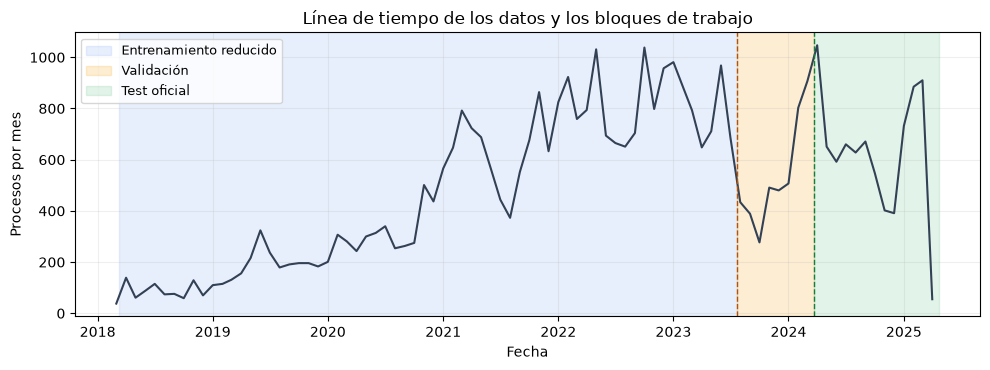

In [8]:
todos_los_procesos = pd.concat([train_oficial, test_oficial], ignore_index=True)
volumen_mensual = todos_los_procesos.set_index('timestamp').resample('MS').size()
inicio_test = test_oficial['timestamp'].min()
fin_datos = test_oficial['timestamp'].max() + pd.Timedelta(days=1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(train_oficial['timestamp'].min(), dia_corte,
           color='#2563eb', alpha=0.10, label='Entrenamiento reducido')
ax.axvspan(dia_corte, inicio_test, color='#f59e0b', alpha=0.18, label='Validación')
ax.axvspan(inicio_test, fin_datos, color='#16a34a', alpha=0.12, label='Test oficial')
ax.plot(volumen_mensual.index, volumen_mensual.values, color='#334155', linewidth=1.5)
ax.axvline(dia_corte, color='#b45309', linestyle='--', linewidth=1)
ax.axvline(inicio_test, color='#15803d', linestyle='--', linewidth=1)
ax.set(title='Línea de tiempo de los datos y los bloques de trabajo',
       xlabel='Fecha', ylabel='Procesos por mes')
ax.grid(alpha=0.2)
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
plt.show()


## Parte 2. Exploración de los datos

Los análisis de perfiles completos son **descriptivos de la instantánea publicada**. No autorizan a ajustar IDF, imputaciones o modelos con perfiles futuros. No mostramos filas de personas reales ni usamos atributos demográficos como features.


In [9]:
import json
import random
import time
import importlib.util

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


### 2.1. Atributos y calidad

#### Composición de columnas e inventario

Todos los CSV se leyeron como texto para preservar los IDs. Ese dtype de lectura no significa que todas las variables sean semánticamente iguales. Distinguimos identificadores, fechas, atributos de reclutador, atributos inferidos por LLM y campos de proceso.

El inventario desplegable permite consultar **todas las columnas**, su disponibilidad y cardinalidad. Una respuesta `False` o un valor cero cuentan como datos presentes; no se consideran ausencias. La disponibilidad no mide exactitud ni relevancia predictiva.


Grupo,Atributo LLM,Atributo de reclutador/origen,Campo de proceso,Fecha,Identificador
Archivo,,,,,
candidates.csv,43,9,0,1,1
history.csv,0,0,2,11,3
jobs.csv,23,9,0,1,1


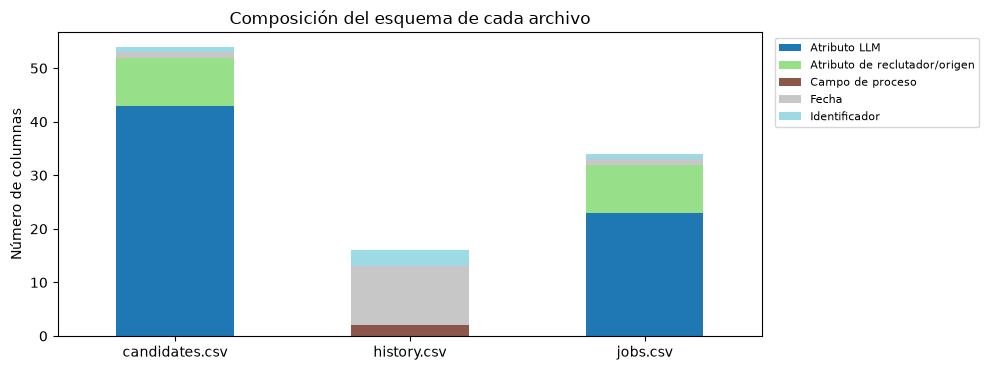

Archivo,Columna,Grupo,Disponibilidad (%),Valores distintos presentes,Excluir como feature demográfica
candidates.csv,candidate_id,Identificador,100.00,37554,False
candidates.csv,create_date,Fecha,92.58,2582,False
candidates.csv,skills,Atributo de reclutador/origen,88.63,19149,False
candidates.csv,expertise_area,Atributo de reclutador/origen,92.05,165,False
candidates.csv,job_category,Atributo de reclutador/origen,73.15,2993,False
candidates.csv,years_experience,Atributo de reclutador/origen,16.50,3,False
candidates.csv,actual_salary,Atributo de reclutador/origen,6.12,2258,False
candidates.csv,actual_daily_salary,Atributo de reclutador/origen,2.27,354,False
candidates.csv,contract_type,Atributo de reclutador/origen,85.13,7,False
candidates.csv,zipcode,Atributo de reclutador/origen,58.45,84,False


In [10]:
from IPython.display import HTML
from matplotlib.ticker import PercentFormatter

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

SENSIBLES = {'llm_sex', 'llm_nationality', 'llm_age_bucket'}

def presente(serie):
    return serie.notna() & serie.fillna('').astype(str).str.strip().ne('')

def grupo_campo(nombre, archivo):
    if nombre.endswith('_id'):
        return 'Identificador'
    if nombre == 'create_date' or nombre.endswith('_date'):
        return 'Fecha'
    if nombre.startswith('llm_'):
        return 'Atributo LLM'
    return 'Campo de proceso' if archivo == 'history.csv' else 'Atributo de reclutador/origen'

inventario = pd.DataFrame([
    {'Archivo': archivo, 'Columna': columna, 'Grupo': grupo_campo(columna, archivo),
     'Disponibilidad (%)': 100 * presente(tabla[columna]).mean(),
     'Valores distintos presentes': tabla.loc[presente(tabla[columna]), columna].nunique(),
     'Excluir como feature demográfica': columna in SENSIBLES}
    for archivo, tabla in tablas.items() for columna in tabla.columns
])
composicion = pd.crosstab(inventario['Archivo'], inventario['Grupo'])
display(composicion)
ax = composicion.plot.bar(stacked=True, figsize=(10, 3.8), colormap='tab20')
ax.set(xlabel='', ylabel='Número de columnas', title='Composición del esquema de cada archivo')
ax.tick_params(axis='x', rotation=0)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()
display(HTML('<details><summary>Desplegar inventario completo de columnas</summary>'
             + inventario.round(2).to_html(index=False) + '</details>'))


La abundancia de columnas LLM no garantiza que aporten señal independiente. Varias describen el mismo concepto que un atributo humano y pueden discrepar. Los IDs no son números ordinales. Los resultados finales del proceso tampoco son atributos conocidos al recomendar su primera etapa.


#### Datos faltantes y complementariedad entre fuentes

Mostramos los atributos con más ausencias y comparamos conceptos presentes tanto en campos humanos como en campos LLM. La tabla distingue cuatro casos: ambas fuentes, solo humano, solo LLM y ninguna.

El porcentaje se calcula sobre **todos los perfiles de cada archivo**. Esto describe cobertura de la instantánea, no disponibilidad histórica en una fecha ni precisión de las inferencias.


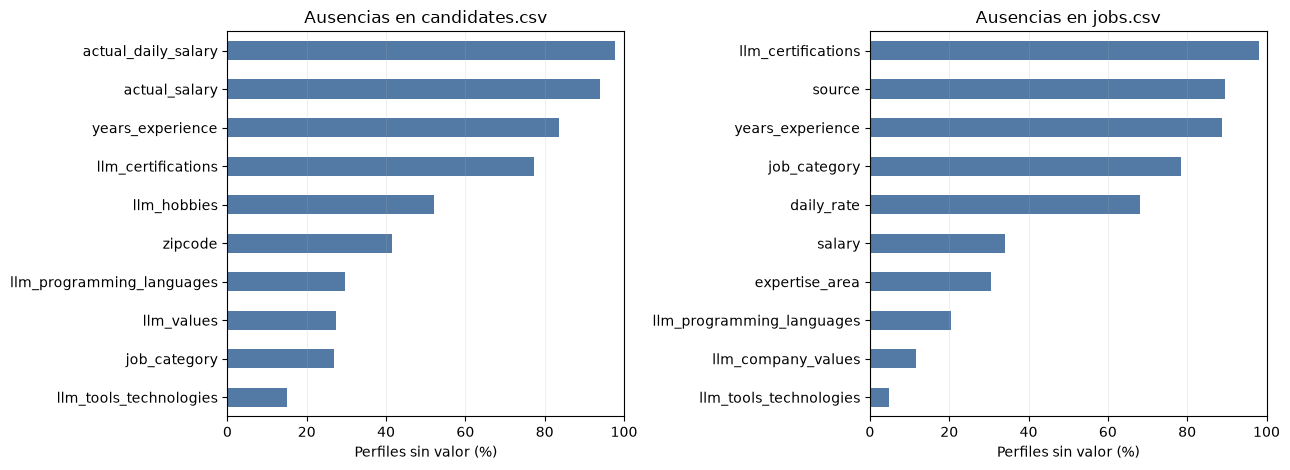

,Entidad,Concepto,Ambas (%),Solo humano (%),Solo LLM (%),Ninguna (%)
0,Candidatos,Habilidades,81.4,7.2,6.5,4.9
1,Ofertas,Habilidades,97.6,0.2,2.1,0.0
2,Candidatos,Área de experiencia,84.2,7.8,3.5,4.5
3,Ofertas,Área de experiencia,69.4,0.0,30.5,0.0
4,Candidatos,Categoría,67.3,5.9,21.5,5.3
5,Ofertas,Categoría,21.4,0.0,78.5,0.0
6,Candidatos,Experiencia,16.5,0.0,83.5,0.0
7,Ofertas,Experiencia,11.1,0.0,88.9,0.0
8,Candidatos,Salario,6.1,0.0,93.9,0.0
9,Ofertas,Salario,65.8,0.0,34.2,0.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, archivo in zip(axes, ['candidates.csv', 'jobs.csv']):
    subconjunto = inventario[
        (inventario['Archivo'] == archivo)
        & inventario['Grupo'].isin(['Atributo LLM', 'Atributo de reclutador/origen'])
        & ~inventario['Excluir como feature demográfica']
    ].copy()
    faltantes = (100 - subconjunto.set_index('Columna')['Disponibilidad (%)']).nlargest(10)
    faltantes.sort_values().plot.barh(ax=ax, color='#527aa5')
    ax.set(title=f'Ausencias en {archivo}', xlabel='Perfiles sin valor (%)', ylabel='')
    ax.set_xlim(0, 100)
    ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

pares_atributos = [
    ('Habilidades', 'skills', 'llm_hard_skills', 'skills', 'llm_hard_skills'),
    ('Área de experiencia', 'expertise_area', 'llm_expertise_area', 'expertise_area', 'llm_expertise_area'),
    ('Categoría', 'job_category', 'llm_job_category', 'job_category', 'llm_job_category'),
    ('Experiencia', 'years_experience', 'llm_years_of_work_experience',
     'years_experience', 'llm_required_years_of_work_experience'),
    ('Salario', 'actual_salary', 'llm_estimated_salary_eur_per_year',
     'salary', 'llm_salary_estimation_eur_per_year'),
]
filas_cobertura = []
for concepto, ch, cl, jh, jl in pares_atributos:
    for entidad, tabla, humano, llm in [
        ('Candidatos', candidatos, ch, cl), ('Ofertas', ofertas, jh, jl)
    ]:
        h, l = presente(tabla[humano]), presente(tabla[llm])
        filas_cobertura.append({
            'Entidad': entidad, 'Concepto': concepto,
            'Ambas (%)': 100 * (h & l).mean(), 'Solo humano (%)': 100 * (h & ~l).mean(),
            'Solo LLM (%)': 100 * (~h & l).mean(), 'Ninguna (%)': 100 * (~h & ~l).mean(),
        })
cobertura_atributos = pd.DataFrame(filas_cobertura)
display(cobertura_atributos.round(1))
assert np.allclose(cobertura_atributos.filter(like='(%)').sum(axis=1), 100)


Un campo inferido puede ampliar cobertura donde falta el humano, pero no es una observación adicional del resultado de contratación ni un reemplazo automáticamente fiable. En el baseline de contenido podremos comparar fuentes y tratar explícitamente perfiles sin tokens. No imputaremos salarios o experiencia usando todo el dataset para entrenar.


#### Integridad, repeticiones y fechas

Comprobamos identificadores, enlaces entre tablas y fechas. Una fila repetida exactamente, un `application_id` repetido y un par candidato–oferta repetido son situaciones diferentes. El mismo par puede identificar varios procesos; no lo eliminamos automáticamente.

También contamos procesos anteriores a la creación declarada de sus entidades y diferencias en las fechas de etapas. Las fechas fueron anonimizadas; una anomalía requiere investigar su semántica, no corregirla por intuición. En todos los casos reportamos el denominador.


In [12]:
creacion_candidatos = pd.to_datetime(candidatos.set_index('candidate_id')['create_date'], errors='coerce')
creacion_ofertas = pd.to_datetime(ofertas.set_index('job_id')['create_date'], errors='coerce')
fecha_candidato_proceso = historial['candidate_id'].map(creacion_candidatos)
fecha_oferta_proceso = historial['job_id'].map(creacion_ofertas)

etapas_ordenadas = [
    'spontaneous_application_date', 'shortlist_date', 'qualification_date',
    'resume_sent_to_company_date', '1st_interview_date', '2nd_interview_date',
    '3rd_interview_date', '4th_interview_date', 'job_offer_proposed_date', 'job_offer_accepted_date',
]
fechas_etapas = fechas[etapas_ordenadas]
retroceso_etapas = fechas_etapas.ffill(axis=1).diff(axis=1).lt(pd.Timedelta(0)).any(axis=1)
fechas_invalidas = sum(
    (presente(tabla['create_date']) & pd.to_datetime(tabla['create_date'], errors='coerce').isna()).sum()
    for tabla in [candidatos, ofertas]
)

filas_auditoria = [
    ('IDs candidatos duplicados', candidatos['candidate_id'].duplicated().sum(), len(candidatos)),
    ('IDs ofertas duplicados', ofertas['job_id'].duplicated().sum(), len(ofertas)),
    ('IDs de proceso duplicados', historial['application_id'].duplicated().sum(), len(historial)),
    ('Filas de historial exactamente duplicadas', historial.duplicated().sum(), len(historial)),
    ('Filas adicionales de pares candidato-oferta repetidos',
     historial.duplicated(['candidate_id', 'job_id']).sum(), len(historial)),
    ('Procesos con candidato sin perfil', (~historial['candidate_id'].isin(candidatos['candidate_id'])).sum(), len(historial)),
    ('Procesos con oferta sin perfil', (~historial['job_id'].isin(ofertas['job_id'])).sum(), len(historial)),
    ('Candidatos sin create_date', creacion_candidatos.isna().sum(), len(candidatos)),
    ('Ofertas sin create_date', creacion_ofertas.isna().sum(), len(ofertas)),
    ('Fechas de creación presentes no parseables', fechas_invalidas, len(candidatos) + len(ofertas)),
    ('Procesos anteriores a creación del candidato',
     (primera_fecha < fecha_candidato_proceso).sum(), fecha_candidato_proceso.notna().sum()),
    ('Procesos anteriores a creación de la oferta',
     (primera_fecha < fecha_oferta_proceso).sum(), fecha_oferta_proceso.notna().sum()),
    ('Procesos con retroceso entre etapas observadas', retroceso_etapas.sum(), len(historial)),
    ('Fin de proceso anterior a última etapa observada',
     (fechas['end_of_process_date'] < fechas_etapas.max(axis=1)).sum(),
     fechas['end_of_process_date'].notna().sum()),
]
auditoria = pd.DataFrame(filas_auditoria, columns=['Control', 'Casos', 'Denominador'])
auditoria['Porcentaje'] = 100 * auditoria['Casos'] / auditoria['Denominador'].replace(0, np.nan)
display(auditoria.round(3))

por_par = historial.groupby(['candidate_id', 'job_id']).size()
display(pd.DataFrame({
    'Medida': ['Pares distintos', 'Pares con varios procesos', 'Máximo de procesos por par'],
    'Cantidad': [len(por_par), int((por_par > 1).sum()), int(por_par.max())],
}))


,Control,Casos,Denominador,Porcentaje
0,IDs candidatos duplicados,0,37554,0.000
1,IDs ofertas duplicados,0,6011,0.000
2,IDs de proceso duplicados,0,42288,0.000
3,Filas de historial exactamente duplicadas,0,42288,0.000
4,Filas adicionales de pares candidato-oferta repetidos,980,42288,2.317
5,Procesos con candidato sin perfil,0,42288,0.000
6,Procesos con oferta sin perfil,0,42288,0.000
7,Candidatos sin create_date,2788,37554,7.424
8,Ofertas sin create_date,0,6011,0.000
9,Fechas de creación presentes no parseables,0,43565,0.000


,Medida,Cantidad
0,Pares distintos,41308
1,Pares con varios procesos,727
2,Máximo de procesos por par,24


Conservamos la unidad de proceso del benchmark. Un CF binario puede colapsar pares como parte de su representación, mientras un baseline de actividad cuenta eventos; esas elecciones deben documentarse porque no significan lo mismo. Las fechas de creación faltantes requieren una política explícita de elegibilidad. Este análisis no modifica datos ni elimina consultas problemáticas.


#### Formatos de experiencia, contratos y salario

Exploramos perfiles de entidades **con procesos en entrenamiento reducido**. Este subconjunto describe entidades observadas por ese historial; no representa todos los perfiles del mercado ni autoriza suponer que sus atributos tengan versiones históricas.

La experiencia humana usa categorías como `0-2 years`, y la experiencia LLM de candidatos usa intervalos como `5-10`; la experiencia requerida LLM de ofertas sí puede ser numérica. La conversión automática de todos esos campos a número perdería información. No asignamos puntos medios a los intervalos en esta exploración.


,Entidad,Campo,Presentes,Parseables como número,Texto/rango entre los presentes
0,Candidatos,years_experience,3620,0,3620
1,Candidatos,llm_years_of_work_experience,18191,0,18191
2,Candidatos,actual_salary,1468,1468,0
3,Ofertas,years_experience,2,0,2
4,Ofertas,llm_required_years_of_work_experience,3296,3296,0
5,Ofertas,salary,2087,2087,0


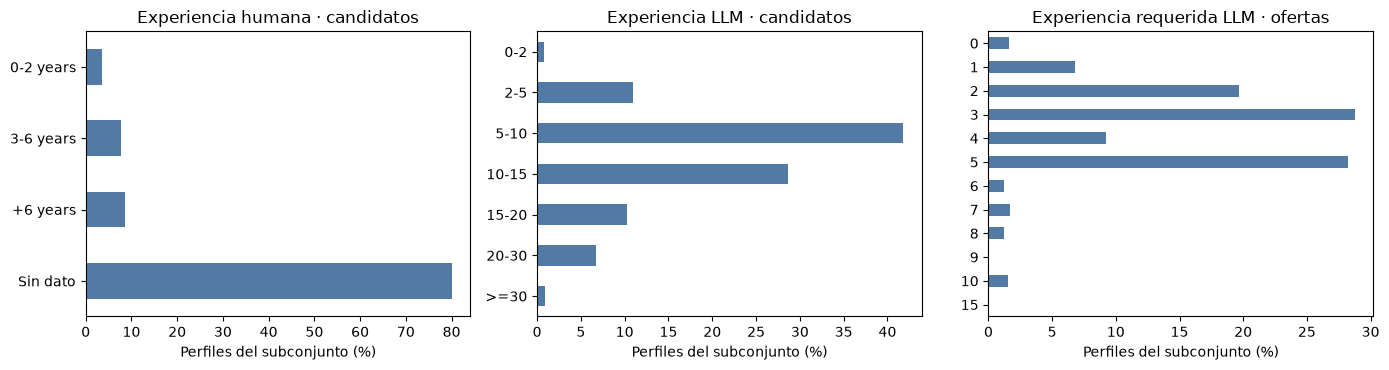

,Candidatos,Ofertas
contract_type,,
Sin dato,5.94,0.00
fixed-term;freelance,0.01,0.00
fixed-term;freelance;permanent,4.23,0.00
freelance,22.33,34.19
freelance;permanent,2.52,0.00
internship,0.14,0.00
permanent,64.83,65.81


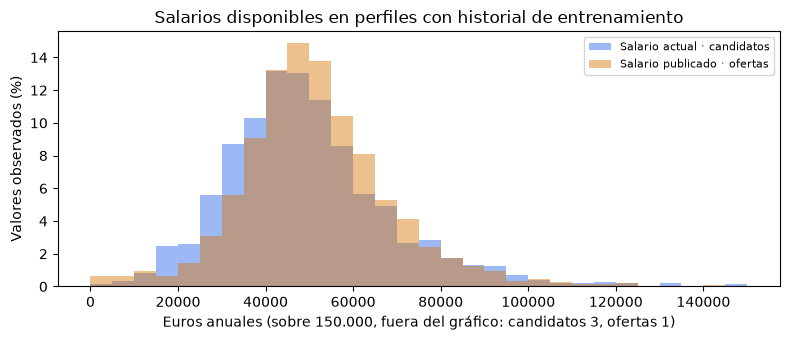

,Campo,Observaciones,Sin dato (%),Ceros,Mediana observada (€ / año),P95 observado
0,Salario actual · candidatos,1468,91.93,0,47288.0,85087.45
1,Salario publicado · ofertas,2087,36.68,0,49899.0,81407.40


In [13]:
candidatos_train = candidatos[candidatos['candidate_id'].isin(train_reducido['candidate_id'])].copy()
ofertas_train = ofertas[ofertas['job_id'].isin(train_reducido['job_id'])].copy()

filas_formato = []
for entidad, tabla, campos in [
    ('Candidatos', candidatos_train, ['years_experience', 'llm_years_of_work_experience', 'actual_salary']),
    ('Ofertas', ofertas_train, ['years_experience', 'llm_required_years_of_work_experience', 'salary']),
]:
    for campo in campos:
        p = presente(tabla[campo])
        n = pd.to_numeric(tabla[campo], errors='coerce')
        filas_formato.append({'Entidad': entidad, 'Campo': campo, 'Presentes': int(p.sum()),
                              'Parseables como número': int(n.notna().sum()),
                              'Texto/rango entre los presentes': int((p & n.isna()).sum())})
display(pd.DataFrame(filas_formato))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, tabla, campo, titulo in [
    (axes[0], candidatos_train, 'years_experience', 'Experiencia humana · candidatos'),
    (axes[1], candidatos_train, 'llm_years_of_work_experience', 'Experiencia LLM · candidatos'),
    (axes[2], ofertas_train, 'llm_required_years_of_work_experience', 'Experiencia requerida LLM · ofertas'),
]:
    valores = tabla[campo].fillna('Sin dato').value_counts()
    if campo == 'llm_required_years_of_work_experience':
        valores = valores.reindex(sorted(valores.index, key=lambda x: float(x) if x != 'Sin dato' else np.inf))
    else:
        orden = (['0-2 years', '3-6 years', '+6 years', 'Sin dato'] if campo == 'years_experience'
                 else ['0-2', '2-5', '5-10', '10-15', '15-20', '20-30', '>=30', 'Sin dato'])
        orden = [v for v in orden if v in valores.index] + [v for v in valores.index if v not in orden]
        valores = valores.reindex(orden)
    (valores.iloc[::-1] / len(tabla) * 100).plot.barh(ax=ax, color='#527aa5')
    ax.set(title=titulo, xlabel='Perfiles del subconjunto (%)', ylabel='')
fig.tight_layout()
plt.show()

contratos = pd.DataFrame({
    'Candidatos': candidatos_train['contract_type'].fillna('Sin dato').value_counts(normalize=True),
    'Ofertas': ofertas_train['contract_type'].fillna('Sin dato').value_counts(normalize=True),
}).fillna(0).mul(100)
display(contratos.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
salarios_resumen = []
bins_salario = np.arange(0, 155000, 5000)
fuera_grafico = []
for nombre, tabla, campo, color in [
    ('Salario actual · candidatos', candidatos_train, 'actual_salary', '#2563eb'),
    ('Salario publicado · ofertas', ofertas_train, 'salary', '#d97706'),
]:
    valores = pd.to_numeric(tabla[campo], errors='coerce')
    observados = valores.dropna()
    ax.hist(observados, bins=bins_salario, weights=np.full(len(observados), 100 / len(observados)),
            alpha=.45, label=nombre, color=color)
    fuera_grafico.append(int((observados > bins_salario[-1]).sum()))
    salarios_resumen.append({'Campo': nombre, 'Observaciones': len(observados),
                             'Sin dato (%)': 100 * valores.isna().mean(), 'Ceros': observados.eq(0).sum(),
                             'Mediana observada (€ / año)': observados.median(), 'P95 observado': observados.quantile(.95)})
ax.set(title='Salarios disponibles en perfiles con historial de entrenamiento',
       xlabel=f'Euros anuales (sobre 150.000, fuera del gráfico: candidatos {fuera_grafico[0]}, ofertas {fuera_grafico[1]})',
       ylabel='Valores observados (%)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame(salarios_resumen).round(2))


Las distribuciones salariales se condicionan a tener un valor observado y corresponden a conceptos diferentes, salario actual y salario de oferta, así que no comparan directamente expectativas ni permiten tratar ausencia como cero. La tarjeta del dataset informa perturbación y recorte de valores extremos al percentil 95, pero el archivo conserva salarios muy por encima de ese percentil (hasta cerca de 900.000 €) y valores muy bajos para un sueldo anual, así que no conviene asumir que esos extremos fueron recortados.

Los contratos pueden enumerar varias opciones separadas por `;`. La tabla cuenta la combinación completa tal como viene en el CSV, no su compatibilidad semántica, así que `freelance;permanent` es una fila distinta de `permanent`. Por estas diferencias de significado y formato, conviene partir el contenido por campos con vocabulario compartido (habilidades, área y categoría) antes que por contrato, experiencia o salario.

### 2.2. Historial y dispersión

#### Participación y colas largas

Primero contrastamos el catálogo completo con las entidades que tienen al menos un proceso en todo el registro. Es una descripción retrospectiva del archivo, no el catálogo disponible en una fecha.

Para estudiar la señal que un modelo inicial puede aprender, calculamos después las distribuciones usando **solo entrenamiento reducido**. La densidad usa pares distintos; informamos por separado el número de procesos para no confundir repeticiones con celdas diferentes de una matriz.


,Con procesos,Sin procesos
Entidad,,
Candidatos,26101,11453
Ofertas,4116,1895


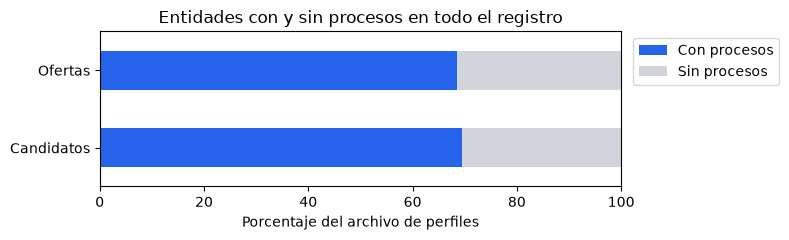

,Bloque,Procesos,Pares distintos,Candidatos con historial,Ofertas con historial,Densidad sobre entidades con historial (%)
0,Registro completo · descriptivo,42288,41308,26101,4116,0.0385
1,Entrenamiento reducido,29599,29342,18191,3296,0.0489
2,Validación · solo su composición,4231,4096,3631,493,0.2288


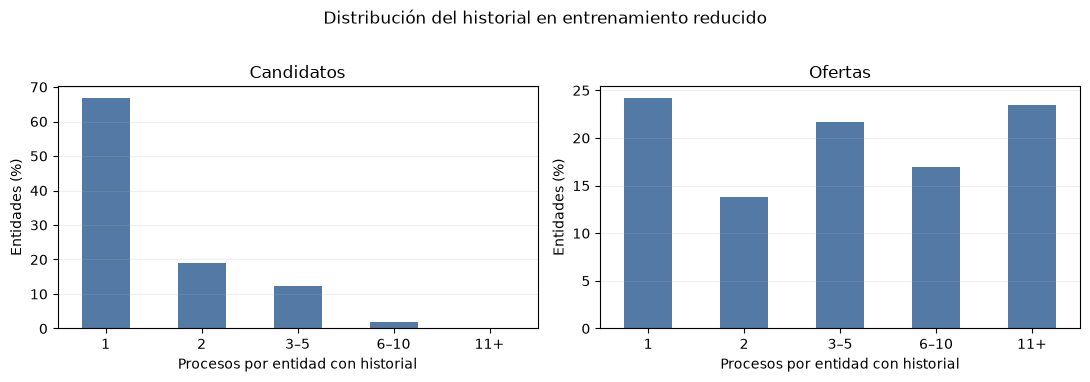

,Entidad,Mínimo,Mediana,Promedio,P90,Máximo,Con un solo proceso (%),Procesos concentrados en el 20% más activo (%)
0,Candidatos,1,1.0,1.63,3.0,17,66.85,42.76
1,Ofertas,1,4.0,8.98,22.5,209,24.21,66.00


In [14]:
participacion = pd.DataFrame([
    {'Entidad': 'Candidatos', 'Con procesos': historial['candidate_id'].nunique(),
     'Sin procesos': len(candidatos) - historial['candidate_id'].nunique()},
    {'Entidad': 'Ofertas', 'Con procesos': historial['job_id'].nunique(),
     'Sin procesos': len(ofertas) - historial['job_id'].nunique()},
]).set_index('Entidad')
display(participacion)
ax = participacion.div(participacion.sum(axis=1), axis=0).mul(100).plot.barh(
    stacked=True, figsize=(8, 2.5), color=['#2563eb', '#d1d5db']
)
ax.set(xlabel='Porcentaje del archivo de perfiles', ylabel='',
       title='Entidades con y sin procesos en todo el registro')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

def estructura(nombre, datos):
    nc, nj = datos['candidate_id'].nunique(), datos['job_id'].nunique()
    pares = len(datos.drop_duplicates(['candidate_id', 'job_id']))
    return {'Bloque': nombre, 'Procesos': len(datos), 'Pares distintos': pares,
            'Candidatos con historial': nc, 'Ofertas con historial': nj,
            'Densidad sobre entidades con historial (%)': 100 * pares / (nc * nj)}

display(pd.DataFrame([
    estructura('Registro completo · descriptivo', todos_los_procesos),
    estructura('Entrenamiento reducido', train_reducido),
    estructura('Validación · solo su composición', validacion),
]).round(4))

grados_candidatos = train_reducido.groupby('candidate_id').size()
grados_ofertas = train_reducido.groupby('job_id').size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
resumen_grados = []
for ax, nombre, grados in [
    (axes[0], 'Candidatos', grados_candidatos), (axes[1], 'Ofertas', grados_ofertas)
]:
    grupos = pd.cut(grados, [0, 1, 2, 5, 10, np.inf], labels=['1', '2', '3–5', '6–10', '11+'])
    (grupos.value_counts(sort=False) / len(grados) * 100).plot.bar(ax=ax, color='#527aa5', rot=0)
    ax.set(title=nombre, xlabel='Procesos por entidad con historial', ylabel='Entidades (%)')
    ax.grid(axis='y', alpha=0.2)
    ntop = max(1, int(np.ceil(len(grados) * 0.2)))
    resumen_grados.append({
        'Entidad': nombre, 'Mínimo': grados.min(), 'Mediana': grados.median(),
        'Promedio': grados.mean(), 'P90': grados.quantile(.9), 'Máximo': grados.max(),
        'Con un solo proceso (%)': 100 * grados.eq(1).mean(),
        'Procesos concentrados en el 20% más activo (%)': 100 * grados.nlargest(ntop).sum() / grados.sum(),
    })
fig.suptitle('Distribución del historial en entrenamiento reducido', y=1.02)
fig.tight_layout()
plt.show()
resumen_grados = pd.DataFrame(resumen_grados)
display(resumen_grados.round(2))


Un candidato con un único proceso ofrece poca señal colaborativa. Las ofertas pueden acumular más ejemplos y permitir un perfil basado en candidatos previos. La cola larga obliga a evaluar por cantidad de historial; una media global puede ocultar muchos casos casi sin datos. Una entidad sin procesos en el archivo no es un ejemplo negativo observado ni necesariamente una oferta cerrada.


#### Composición de los procesos y etapas

Distinguimos **etapa máxima final** y **presencia de una fecha de etapa**. La primera distribución no es un embudo de conversiones y la segunda tampoco implica que todos los procesos recorran las mismas etapas sin saltos.

Analizamos procesos cuyo inicio pertenece al entrenamiento reducido. Sus resultados finales son retrospectivos: algunas etapas pueden ocurrir después del corte de ese entrenamiento. Por eso comparamos fechas presentes en la instantánea con fechas realmente anteriores al corte. Los resultados finales no entran como features al predecir el inicio del proceso.


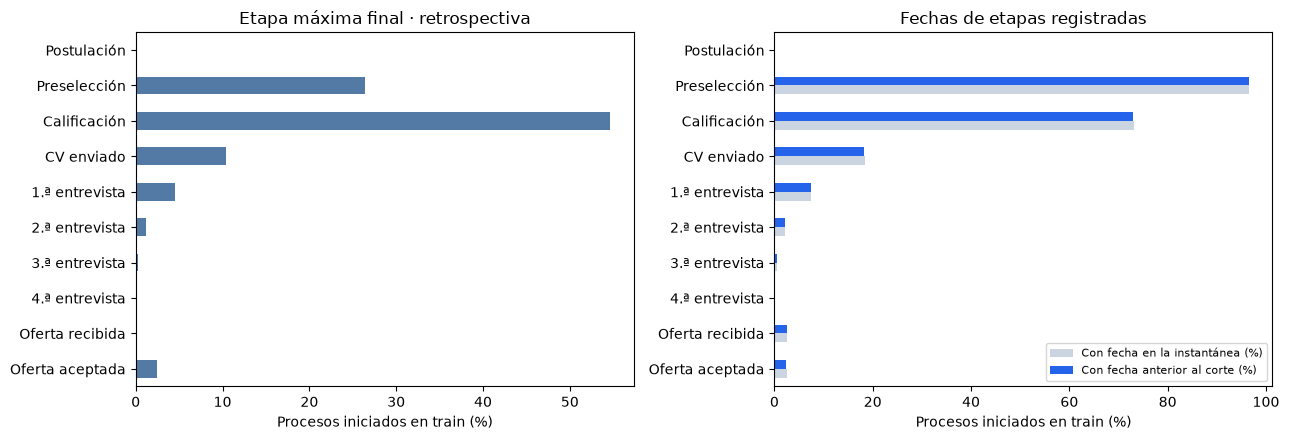

,Con fecha en la instantánea (%),Con fecha anterior al corte (%)
Postulación,0.14,0.14
Preselección,96.48,96.48
Calificación,73.08,73.00
CV enviado,18.42,18.31
1.ª entrevista,7.53,7.53
2.ª entrevista,2.19,2.19
3.ª entrevista,0.53,0.53
4.ª entrevista,0.10,0.10
Oferta recibida,2.55,2.53
Oferta aceptada,2.46,2.44


Etapas de esos procesos fechadas en o después del corte: 67


In [15]:
mascara_inicio_train = primera_fecha.dt.normalize() < dia_corte
historial_inicio_train = historial.loc[mascara_inicio_train]
etapas_inicio_train = fechas_etapas.loc[mascara_inicio_train]
ETIQUETAS_ETAPA = {
    'Application Made': 'Postulación', 'Shortlist': 'Preselección', 'Qualification': 'Calificación',
    'Resume Sent': 'CV enviado', '1st Interview': '1.ª entrevista', '2nd Interview': '2.ª entrevista',
    '3rd Interview': '3.ª entrevista', '4th Interview': '4.ª entrevista',
    'Offer Received': 'Oferta recibida', 'Offer Accepted': 'Oferta aceptada',
}
maxima = historial_inicio_train['last_stage_reached'].value_counts().reindex(ETIQUETAS_ETAPA, fill_value=0)
maxima.index = [ETIQUETAS_ETAPA[x] for x in maxima.index]
etapas_disponibles = pd.DataFrame({
    'Con fecha en la instantánea (%)': 100 * etapas_inicio_train.notna().mean(),
    'Con fecha anterior al corte (%)': 100 * etapas_inicio_train.lt(dia_corte).mean(),
})
etapas_disponibles.index = list(ETIQUETAS_ETAPA.values())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(maxima / len(historial_inicio_train) * 100).iloc[::-1].plot.barh(ax=axes[0], color='#527aa5')
axes[0].set(title='Etapa máxima final · retrospectiva', xlabel='Procesos iniciados en train (%)', ylabel='')
etapas_disponibles.iloc[::-1].plot.barh(ax=axes[1], color=['#cbd5e1', '#2563eb'])
axes[1].set(title='Fechas de etapas registradas', xlabel='Procesos iniciados en train (%)', ylabel='')
axes[1].legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()
display(etapas_disponibles.round(2))
print('Etapas de esos procesos fechadas en o después del corte:',
      int(etapas_inicio_train.ge(dia_corte).sum().sum()))


Si luego representamos una oferta mediante candidatos preseleccionados, solo podremos incorporar a cada candidato cuando la preselección ya haya ocurrido. No basta con que el proceso empezara antes. Una etapa sin fecha no demuestra que el candidato la haya rechazado; puede no haberse registrado o no corresponder a ese proceso. Si cambiamos el positivo a contratación, estaremos definiendo otra tarea y afrontando distinta observabilidad y desbalance.


#### Cold-start al comienzo de cada día

Ahora simulamos únicamente la **disponibilidad del historial**, sin entrenar ni puntuar un modelo. Iniciamos el estado con entrenamiento reducido. Para cada día de validación, construimos las consultas, consultamos el estado anterior y recién después revelamos todos los procesos de ese día.

Conservamos un positivo por candidato–día usando la última fila, como el evaluador oficial. Registramos también el tiempo desde la última interacción previa de su oferta relevante. Las ofertas y candidatos del mismo día no pueden proporcionarse historial entre sí antes de ser evaluados.


oferta_con_historial,Oferta nueva en historial,Oferta con historial
candidato_con_historial,,
Candidato nuevo,272,2488
Candidato con historial,158,1290


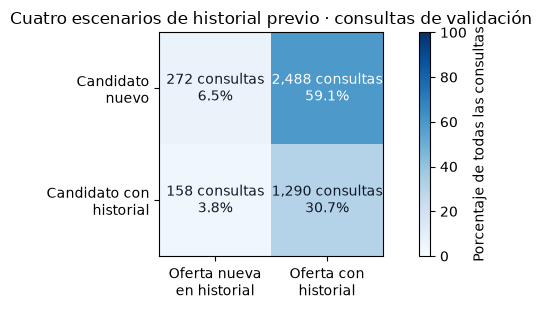

,Entidad,Entidades distintas de val ausentes en train reducido (%),Consultas sin historial al recomendar (%)
0,Candidatos,76.01,65.59
1,Ofertas,81.34,10.22


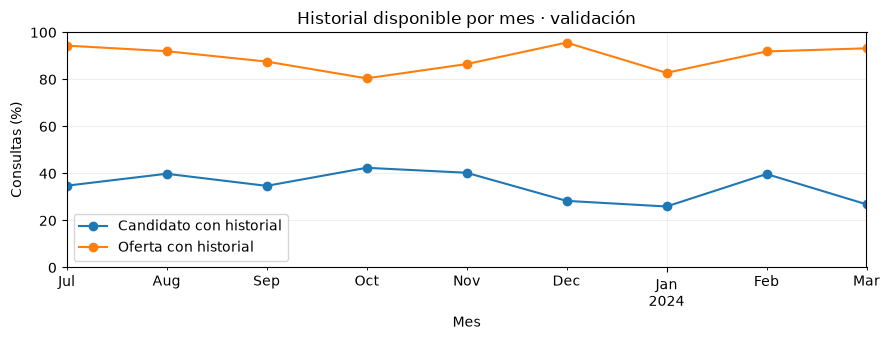

In [16]:
hist_candidatos = set(train_reducido['candidate_id'])
hist_ofertas = set(train_reducido['job_id'])
ultima_actividad_oferta = train_reducido.groupby('job_id')['timestamp'].max().dt.normalize().to_dict()
registros_consultas = []

for dia, procesos_dia in validacion.assign(dia=validacion['timestamp'].dt.normalize()).groupby('dia', sort=True):
    consultas_dia = procesos_dia.drop_duplicates('candidate_id', keep='last').copy()
    ultima_previa = pd.to_datetime(consultas_dia['job_id'].map(ultima_actividad_oferta))
    bloque = pd.DataFrame({
        'dia': dia,
        'candidate_id': consultas_dia['candidate_id'],
        'job_id': consultas_dia['job_id'],
        'candidato_con_historial': consultas_dia['candidate_id'].isin(hist_candidatos),
        'oferta_con_historial': consultas_dia['job_id'].isin(hist_ofertas),
        'dias_desde_ultima_actividad': (dia - ultima_previa).dt.days,
        'fecha_creacion_oferta': consultas_dia['job_id'].map(creacion_ofertas),
    })
    registros_consultas.append(bloque)
    # Solo después de construir TODAS las consultas del día revelamos sus procesos.
    hist_candidatos.update(procesos_dia['candidate_id'])
    hist_ofertas.update(procesos_dia['job_id'])
    ultima_actividad_oferta.update(dict.fromkeys(procesos_dia['job_id'], dia))

consultas_validacion = pd.concat(registros_consultas, ignore_index=True)
assert len(consultas_validacion) == validacion.assign(dia=validacion['timestamp'].dt.normalize()).groupby(['candidate_id', 'dia']).ngroups
assert consultas_validacion.loc[consultas_validacion['oferta_con_historial'], 'dias_desde_ultima_actividad'].ge(1).all()

cohortes = pd.crosstab(
    consultas_validacion['candidato_con_historial'].map({False:'Candidato nuevo', True:'Candidato con historial'}),
    consultas_validacion['oferta_con_historial'].map({False:'Oferta nueva en historial', True:'Oferta con historial'}),
).reindex(index=['Candidato nuevo', 'Candidato con historial'],
          columns=['Oferta nueva en historial', 'Oferta con historial'], fill_value=0)
porcentajes_cohortes = cohortes / len(consultas_validacion) * 100
display(cohortes)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(porcentajes_cohortes.to_numpy(), cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(2), ['Oferta nueva\nen historial', 'Oferta con\nhistorial'])
ax.set_yticks(range(2), ['Candidato\nnuevo', 'Candidato con\nhistorial'])
for i in range(2):
    for j in range(2):
        v = porcentajes_cohortes.iloc[i, j]
        ax.text(j, i, f'{cohortes.iloc[i, j]:,} consultas\n{v:.1f}%',
                ha='center', va='center', color='white' if v > 50 else '#111827')
ax.set_title('Cuatro escenarios de historial previo · consultas de validación')
fig.colorbar(im, ax=ax, label='Porcentaje de todas las consultas')
fig.tight_layout()
plt.show()

comparacion_nuevos = []
for entidad, clave, bandera in [
    ('Candidatos', 'candidate_id', 'candidato_con_historial'),
    ('Ofertas', 'job_id', 'oferta_con_historial'),
]:
    unicas_val = validacion[clave].drop_duplicates()
    comparacion_nuevos.append({
        'Entidad': entidad,
        'Entidades distintas de val ausentes en train reducido (%)': 100 * (~unicas_val.isin(train_reducido[clave])).mean(),
        'Consultas sin historial al recomendar (%)': 100 * (~consultas_validacion[bandera]).mean(),
    })
display(pd.DataFrame(comparacion_nuevos).round(2))
cohortes_mensuales = consultas_validacion.set_index('dia').resample('MS').agg(
    consultas=('candidate_id', 'size'), candidato_warm=('candidato_con_historial', 'mean'),
    oferta_warm=('oferta_con_historial', 'mean')
)
ax = cohortes_mensuales[['candidato_warm', 'oferta_warm']].mul(100).rename(columns={
    'candidato_warm':'Candidato con historial', 'oferta_warm':'Oferta con historial'
}).plot(marker='o', figsize=(9, 3.5))
ax.set(title='Historial disponible por mes · validación', xlabel='Mes', ylabel='Consultas (%)', ylim=(0, 100))
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


Un candidato ausente del entrenamiento puede adquirir historial durante validación. Los porcentajes por entidades distintas y por consultas dinámicas tienen denominadores diferentes. La combinación de candidatos nuevos con ofertas que sí tienen historial es el escenario que motiva el perfil dinámico centrado en ofertas; no demuestra todavía una mejora de ranking.


### 2.3. Contenido

#### Cobertura entre cohortes

El subconjunto de entrenamiento contiene muy pocos valores humanos de experiencia requerida para las ofertas. Un porcentaje global del CSV puede esconder este patrón. Comparamos la cobertura de atributos por entidades distintas con procesos en entrenamiento reducido y por entidades distintas con procesos en validación.

Las entidades pueden pertenecer a ambos subconjuntos y los atributos son una instantánea. Esto es una comparación de composición entre cohortes, **no una reconstrucción de cuándo se completó cada perfil**. No ajustamos ninguna transformación con validación.


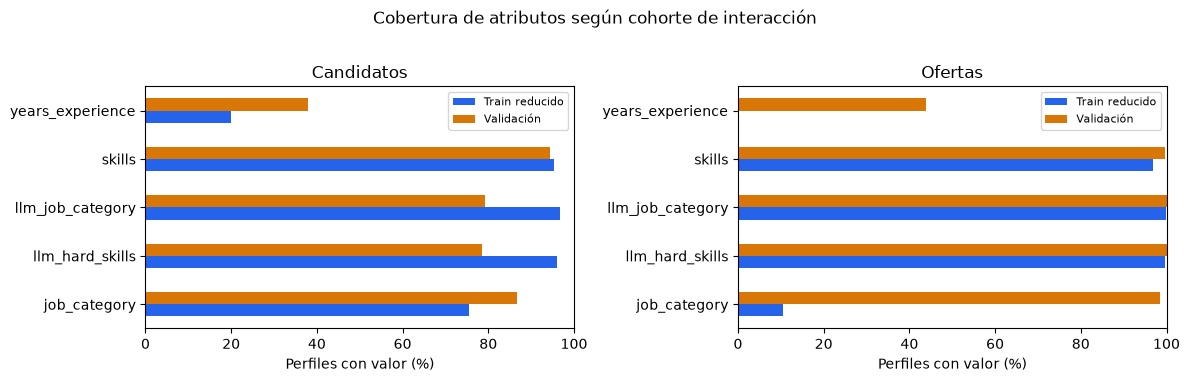

,Entidad,Cohorte,Campo,Perfiles distintos,Perfiles con valor,Cobertura (%)
0,Candidatos,Train reducido,skills,18191,17342,95.33
1,Candidatos,Train reducido,llm_hard_skills,18191,17483,96.11
2,Candidatos,Train reducido,job_category,18191,13730,75.48
3,Candidatos,Train reducido,llm_job_category,18191,17593,96.71
4,Candidatos,Train reducido,years_experience,18191,3620,19.90
5,Candidatos,Validación,skills,3631,3430,94.46
6,Candidatos,Validación,llm_hard_skills,3631,2850,78.49
7,Candidatos,Validación,job_category,3631,3149,86.73
8,Candidatos,Validación,llm_job_category,3631,2877,79.23
9,Candidatos,Validación,years_experience,3631,1375,37.87


In [17]:
cobertura_por_cohorte = []
for nombre, tabla, identificador in [
    ('Candidatos', candidatos, 'candidate_id'), ('Ofertas', ofertas, 'job_id')
]:
    campos = ['skills', 'llm_hard_skills', 'job_category', 'llm_job_category', 'years_experience']
    for cohorte, procesos in [('Train reducido', train_reducido), ('Validación', validacion)]:
        perfiles = tabla[tabla[identificador].isin(procesos[identificador])]
        for campo in campos:
            cobertura_por_cohorte.append({
                'Entidad': nombre, 'Cohorte': cohorte, 'Campo': campo,
                'Perfiles distintos': len(perfiles), 'Perfiles con valor': int(presente(perfiles[campo]).sum()),
                'Cobertura (%)': 100 * presente(perfiles[campo]).mean(),
            })
cobertura_por_cohorte = pd.DataFrame(cobertura_por_cohorte)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for ax, entidad in zip(axes, ['Candidatos', 'Ofertas']):
    vista = cobertura_por_cohorte[cobertura_por_cohorte['Entidad'] == entidad].pivot(
        index='Campo', columns='Cohorte', values='Cobertura (%)'
    )
    vista.plot.barh(ax=ax, color=['#2563eb', '#d97706'])
    ax.set(title=entidad, xlabel='Perfiles con valor (%)', ylabel='', xlim=(0, 100))
    ax.legend(fontsize=8)
fig.suptitle('Cobertura de atributos según cohorte de interacción', y=1.02)
fig.tight_layout()
plt.show()
display(cobertura_por_cohorte.round(2))


Un campo útil por definición puede aportar poco si casi no existe entre las entidades de entrenamiento. Esta comparación motiva revisar cobertura al evaluar contenido y justificar qué campos se usan. La disponibilidad en validación no garantiza que la distribución de sus valores sea igual a entrenamiento ni que la fuente LLM sea más precisa.

En ofertas, la cobertura de `job_category` pasa de 10,47 % en entrenamiento reducido a 98,38 % en validación. Según la fecha de creación de la oferta, este campo casi no se completa hasta mediados de 2023, poco antes del corte de validación, lo que sugiere un cambio en cómo se registraban los datos. Esto puede afectar a los modelos que lo usan: la regresión logística aprende de ofertas donde casi siempre falta, y en TF-IDF su presencia puede actuar en parte como señal de recencia. Todavía no hemos medido este efecto.

#### Habilidades compartidas

Reutilizamos la selección de campos de `jth.features`, que toma habilidades, herramientas, lenguajes, áreas y categorías. Se excluyen las features demográficas y el marcador `_rare_skill_`.

Para esta EDA contamos **presencia de cada token una sola vez por perfil**, aunque aparezca tanto en una fuente humana como en una LLM. Esto evita confundir repetición con cobertura. El modelo TF-IDF puede tener otra ponderación, que deberá evaluarse explícitamente. Las frecuencias se calculan solo sobre los perfiles con procesos en entrenamiento reducido.


,Entidad,Perfiles,Sin tokens (%),Tokens únicos por perfil (mediana),Vocabulario distinto
0,Candidatos,18191,0.00,16.0,1131
1,Ofertas,3296,0.03,10.0,369


,Medida de vocabulario,Tokens
0,Compartido,349
1,Solo candidatos,782
2,Solo ofertas,20
3,Unión,1151


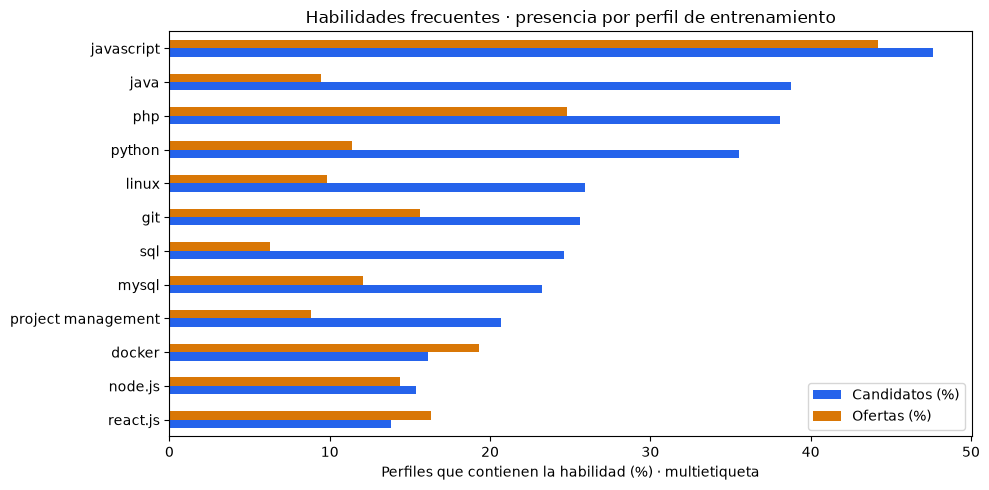

In [18]:
from jth.features import profile_tokens

tokens_candidatos = pd.Series([sorted(set(t)) for t in profile_tokens(candidatos_train)])
tokens_ofertas = pd.Series([sorted(set(t)) for t in profile_tokens(ofertas_train)])
vocab_c = set(tokens_candidatos.explode().dropna())
vocab_j = set(tokens_ofertas.explode().dropna())

resumen_contenido = pd.DataFrame([
    {'Entidad': nombre, 'Perfiles': len(tokens), 'Sin tokens (%)': 100 * tokens.str.len().eq(0).mean(),
     'Tokens únicos por perfil (mediana)': tokens.str.len().median(), 'Vocabulario distinto': len(vocab)}
    for nombre, tokens, vocab in [
        ('Candidatos', tokens_candidatos, vocab_c), ('Ofertas', tokens_ofertas, vocab_j)
    ]
])
display(resumen_contenido.round(2))
display(pd.DataFrame({
    'Medida de vocabulario': ['Compartido', 'Solo candidatos', 'Solo ofertas', 'Unión'],
    'Tokens': [len(vocab_c & vocab_j), len(vocab_c - vocab_j), len(vocab_j - vocab_c), len(vocab_c | vocab_j)],
}))

habilidades_c = tokens_candidatos.map(lambda xs: [x[2:] for x in xs if x.startswith('s:')]).explode().value_counts()
habilidades_j = tokens_ofertas.map(lambda xs: [x[2:] for x in xs if x.startswith('s:')]).explode().value_counts()
frecuencias_habilidades = pd.DataFrame({
    'Candidatos (%)': habilidades_c / len(tokens_candidatos) * 100,
    'Ofertas (%)': habilidades_j / len(tokens_ofertas) * 100,
    'Perfiles totales': habilidades_c.add(habilidades_j, fill_value=0),
}).fillna(0)
seleccion = frecuencias_habilidades[frecuencias_habilidades['Perfiles totales'] >= 5].copy()
seleccion['Promedio de porcentajes'] = seleccion[['Candidatos (%)', 'Ofertas (%)']].mean(axis=1)
top_habilidades = seleccion.nlargest(12, 'Promedio de porcentajes')
top_habilidades[['Candidatos (%)', 'Ofertas (%)']].sort_values('Candidatos (%)').plot.barh(
    figsize=(10, 5), color=['#2563eb', '#d97706']
)
plt.title('Habilidades frecuentes · presencia por perfil de entrenamiento')
plt.xlabel('Perfiles que contienen la habilidad (%) · multietiqueta')
plt.ylabel('')
plt.tight_layout()
plt.show()


El vocabulario compartido permite construir similitudes entre candidatos y ofertas incluso sin interacciones previas del candidato. Una habilidad frecuente puede ser poco discriminativa; frecuencia no implica poder predictivo. La cobertura y el solapamiento léxico tampoco prueban que el contenido supere a LR. Para un experimento honesto, el vocabulario e IDF aprendidos deberán fijarse usando solo entrenamiento y aplicarse después a perfiles nuevos.


### 2.4. Dinámica temporal

#### Vida activa y evolución semanal

La vida activa observada es la diferencia entre el último y el primer **inicio de proceso** de una entidad dentro del entrenamiento reducido. No equivale a la vida real de un candidato en el mercado ni al tiempo de apertura de una oferta.

Las entidades observadas un solo día tienen duración cero con esta definición. Mostramos también la mediana condicionada a dos o más días, y recordamos que la ventana de observación recorta historiales. No utilizamos eventos futuros para construir estas duraciones de entrenamiento.


,Entidad,Entidades observadas,Con actividad en un solo día (%),Mediana de duración (días),P90 (días),Mediana con ≥2 días de actividad
0,Candidatos,18191,67.03,0.0,515.0,258.0
1,Ofertas,3296,24.76,20.0,91.0,30.0


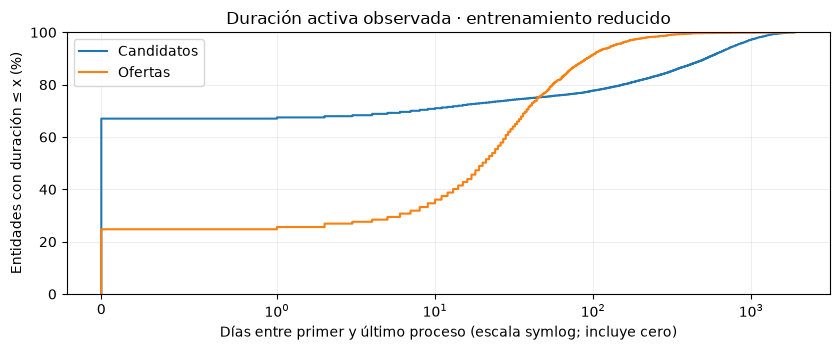

In [19]:
vidas = {}
resumen_vidas = []
for nombre, identificador in [('Candidatos', 'candidate_id'), ('Ofertas', 'job_id')]:
    resumen = train_reducido.assign(dia=train_reducido['timestamp'].dt.normalize()).groupby(identificador)['dia'].agg(
        inicio='min', fin='max', dias_distintos='nunique'
    )
    duracion = (resumen['fin'] - resumen['inicio']).dt.days
    vidas[nombre] = duracion
    resumen_vidas.append({
        'Entidad': nombre, 'Entidades observadas': len(resumen),
        'Con actividad en un solo día (%)': 100 * resumen['dias_distintos'].eq(1).mean(),
        'Mediana de duración (días)': duracion.median(), 'P90 (días)': duracion.quantile(.9),
        'Mediana con ≥2 días de actividad': duracion[resumen['dias_distintos'] >= 2].median(),
    })
display(pd.DataFrame(resumen_vidas).round(2))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for nombre, duracion in vidas.items():
    x = np.sort(duracion.to_numpy())
    ax.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where='post', label=nombre)
ax.set_xscale('symlog', linthresh=1)
ax.set(title='Duración activa observada · entrenamiento reducido',
       xlabel='Días entre primer y último proceso (escala symlog; incluye cero)',
       ylabel='Entidades con duración ≤ x (%)', ylim=(0, 100))
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


Las curvas permiten ver qué proporción concentra su actividad en un intervalo corto y cuánto pesa la cola larga. En candidatos, la mediana sobre todas las entidades es cero, porque el 67 % tiene actividad en un solo día, pero entre quienes tienen dos o más días de actividad sube a 258 días. El intervalo entre primera y última interacción incluye períodos sin observación y puede abarcar episodios diferentes; no mide una única sesión de búsqueda. Por eso no lo equiparamos a otras definiciones de vida activa de la literatura ni inferimos una fecha de cierre desde la última interacción observada.

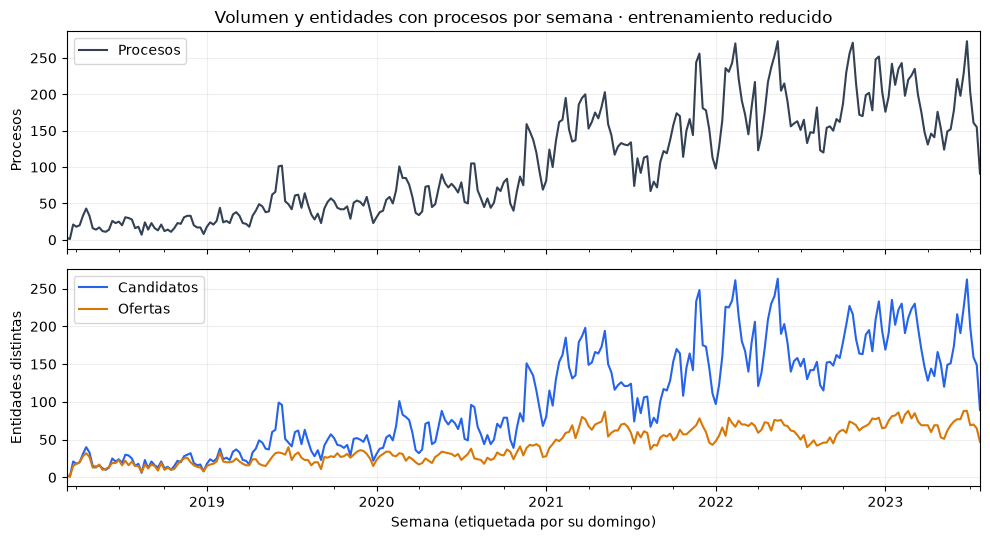

In [20]:
serie_semanal = train_reducido.groupby(pd.Grouper(key='timestamp', freq='W-SUN')).agg(
    Procesos=('candidate_id', 'size'), Candidatos=('candidate_id', 'nunique'), Ofertas=('job_id', 'nunique')
).fillna(0)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
serie_semanal[['Procesos']].plot(ax=axes[0], color=['#334155'])
serie_semanal[['Candidatos', 'Ofertas']].plot(ax=axes[1], color=['#2563eb', '#d97706'])
axes[0].set(title='Volumen y entidades con procesos por semana · entrenamiento reducido', ylabel='Procesos')
axes[1].set(xlabel='Semana (etiquetada por su domingo)', ylabel='Entidades distintas')
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


Las semanas inicial y final del período pueden estar incompletas y las fechas están perturbadas; no atribuimos picos a causas de negocio sin evidencia adicional. La suma de candidatos semanales tampoco equivale a candidatos únicos de todo el período.

#### Tiempo desde creación frente a tiempo desde última actividad

La edad desde publicación y el tiempo desde la última interacción no son la misma señal. Una oferta antigua puede seguir recibiendo candidatos. Comparamos ambas distribuciones en los positivos de validación y mostramos por separado las ofertas sin historial previo.

El cálculo usa información anterior al día de cada consulta. La fecha de creación procede de la instantánea de perfiles; si el positivo aparece antes de esa fecha, se informa como inconsistencia de elegibilidad en lugar de convertir su edad en cero.


,Medida,Consultas con valor válido,Sin valor,Valores negativos,Mediana (días),P90 (días)
0,Edad desde creación,4208,0,0,22.0,74.0
1,Tiempo desde actividad previa,3778,430,0,2.0,10.0


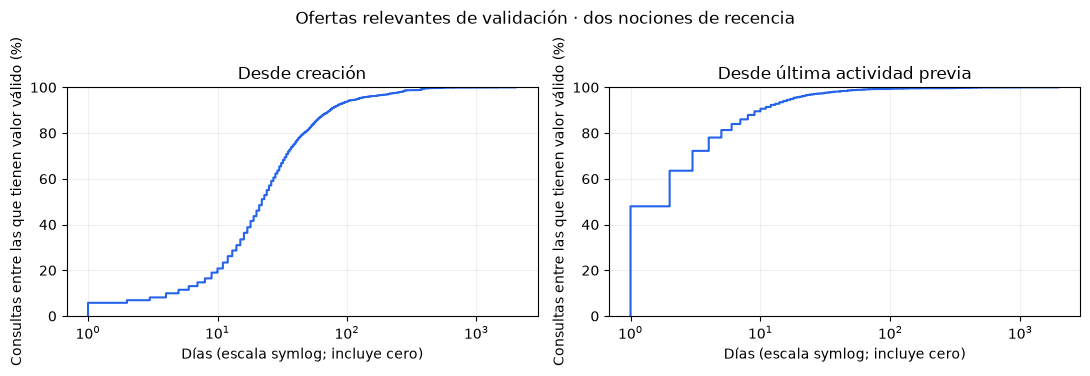

In [21]:
consultas_validacion['edad_desde_creacion'] = (
    consultas_validacion['dia'] - consultas_validacion['fecha_creacion_oferta']
).dt.days
def descripcion_tiempo(nombre, serie):
    validos = serie[serie.notna() & serie.ge(0)]
    return {'Medida': nombre, 'Consultas con valor válido': len(validos),
            'Sin valor': int(serie.isna().sum()), 'Valores negativos': int(serie.lt(0).sum()),
            'Mediana (días)': validos.median(), 'P90 (días)': validos.quantile(.9)}
display(pd.DataFrame([
    descripcion_tiempo('Edad desde creación', consultas_validacion['edad_desde_creacion']),
    descripcion_tiempo('Tiempo desde actividad previa', consultas_validacion['dias_desde_ultima_actividad']),
]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, nombre, serie in [
    (axes[0], 'Desde creación', consultas_validacion['edad_desde_creacion']),
    (axes[1], 'Desde última actividad previa', consultas_validacion['dias_desde_ultima_actividad']),
]:
    validos = np.sort(serie[serie.notna() & serie.ge(0)].to_numpy())
    if len(validos):
        ax.step(validos, np.arange(1, len(validos)+1) / len(validos) * 100, where='post', color='#2563eb')
    ax.set_xscale('symlog', linthresh=1)
    ax.set(title=nombre, xlabel='Días (escala symlog; incluye cero)',
           ylabel='Consultas entre las que tienen valor válido (%)', ylim=(0, 100))
    ax.grid(alpha=.2)
fig.suptitle('Ofertas relevantes de validación · dos nociones de recencia', y=1.02)
fig.tight_layout()
plt.show()


Las curvas están condicionadas a disponer de cada valor; no debemos compararlas como si incluyeran siempre las mismas consultas. La tabla indica qué casos quedaron fuera. Para estudiar un filtro duro, la tabla siguiente mantiene **todas** las consultas en el denominador y contará como pérdidas las ofertas relevantes que no entren al pool.


#### Cobertura de ventanas de actividad

Un filtro duro descartaría las ofertas sin actividad reciente. Antes de construirlo, medimos cuánto perdería. Una oferta sin procesos en los últimos `w` días puede ya no estar abierta, pero si la oferta correcta queda fuera de la lista, ningún ranking puede recuperarla. Por eso esta exploración mira la cobertura del positivo y no el MRR. Para cada día de validación tomamos las ofertas con fecha de creación conocida y no futura. Dentro de ese catálogo identificamos las que tuvieron al menos un proceso en los `w` días anteriores, excluyendo el día de consulta.

Probamos ventanas descriptivas de 7, 14, 30, 60 y 90 días sin declarar una ganadora. Reportamos cobertura del positivo sobre las **4.208 consultas**, pérdidas y tamaño del pool. Los tamaños se resumen por día con consultas; la cobertura se pondera por consulta. Son denominadores distintos, expresamente identificados.

No protegemos aquí ofertas recién publicadas sin historial: queremos medir qué perdería la regla basada únicamente en actividad. Un filtro deberá proteger de alguna forma las ofertas nuevas.


,consultas,conservados,ofertas_pool_mediana,catalogo_mediana,fraccion_catalogo_mediana,Cobertura por consulta (%),Consultas cuyo positivo se elimina
Ventana (días),,,,,,,
7,4208,3249,45.0,5360.0,0.87,77.21,959
14,4208,3532,67.0,5360.0,1.26,83.94,676
30,4208,3679,101.0,5360.0,1.93,87.43,529
60,4208,3739,160.0,5360.0,2.97,88.85,469
90,4208,3750,221.0,5360.0,4.04,89.12,458


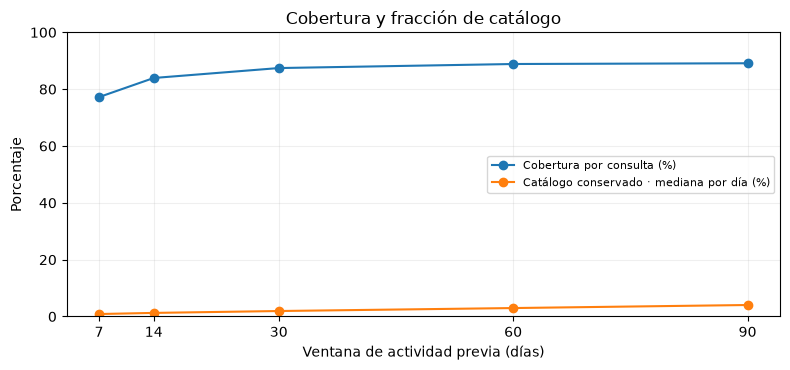

,Casos que requieren atención,Consultas de validación
0,Oferta relevante sin historial previo,430
1,Oferta relevante con creación posterior a la consulta,0


In [22]:
VENTANAS_EXPLORACION = [7, 14, 30, 60, 90]
historia_para_validacion = pd.concat([train_reducido, validacion], ignore_index=True).assign(
    dia=lambda df: df['timestamp'].dt.normalize()
)
filas_ventanas = []
for dia, consultas_dia in consultas_validacion.groupby('dia', sort=True):
    pasado = historia_para_validacion[historia_para_validacion['dia'] < dia]
    ultima = pasado.groupby('job_id')['dia'].max()
    elegibles = set(creacion_ofertas.index[creacion_ofertas.notna() & creacion_ofertas.le(dia)])
    for ventana in VENTANAS_EXPLORACION:
        activas = set(ultima.index[ultima.ge(dia - pd.Timedelta(days=ventana))]) & elegibles
        filas_ventanas.append({
            'Día': dia, 'Ventana (días)': ventana, 'Consultas': len(consultas_dia),
            'Positivos conservados': int(consultas_dia['job_id'].isin(activas).sum()),
            'Ofertas elegibles': len(elegibles), 'Ofertas activas elegibles': len(activas),
            'Fracción del catálogo (%)': 100 * len(activas) / len(elegibles) if elegibles else np.nan,
        })
ventanas_por_dia = pd.DataFrame(filas_ventanas)
resumen_ventanas = ventanas_por_dia.groupby('Ventana (días)').agg(
    consultas=('Consultas', 'sum'), conservados=('Positivos conservados', 'sum'),
    ofertas_pool_mediana=('Ofertas activas elegibles', 'median'),
    catalogo_mediana=('Ofertas elegibles', 'median'), fraccion_catalogo_mediana=('Fracción del catálogo (%)', 'median'),
)
resumen_ventanas['Cobertura por consulta (%)'] = 100 * resumen_ventanas['conservados'] / resumen_ventanas['consultas']
resumen_ventanas['Consultas cuyo positivo se elimina'] = resumen_ventanas['consultas'] - resumen_ventanas['conservados']
assert resumen_ventanas['consultas'].eq(len(consultas_validacion)).all()
assert resumen_ventanas['conservados'].is_monotonic_increasing
display(resumen_ventanas.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
resumen_ventanas[['Cobertura por consulta (%)', 'fraccion_catalogo_mediana']].rename(columns={
    'fraccion_catalogo_mediana':'Catálogo conservado · mediana por día (%)'
}).plot(ax=ax, marker='o')
ax.set(title='Cobertura y fracción de catálogo', xlabel='Ventana de actividad previa (días)',
       ylabel='Porcentaje', ylim=(0, 100))
ax.set_xticks(VENTANAS_EXPLORACION)
ax.grid(alpha=.2)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

nuevo_sin_historial = ~consultas_validacion['oferta_con_historial']
display(pd.DataFrame({
    'Casos que requieren atención': ['Oferta relevante sin historial previo',
                                  'Oferta relevante con creación posterior a la consulta'],
    'Consultas de validación': [int(nuevo_sin_historial.sum()),
                              int(consultas_validacion['edad_desde_creacion'].lt(0).sum())],
}))


Una ventana de 30 días conserva el 1,93 % del catálogo (mediana de 101 de 5.360 ofertas) y aun así el 87,43 % de los positivos, así que la mayoría de las ofertas elegibles no tiene actividad reciente. La cobertura se estanca cerca de 89 % porque en 430 consultas el positivo es una oferta sin historial previo, que ninguna ventana puede conservar. Si el filtro es irreversible, esos casos no pueden recuperarse en el ranking y deben seguir contando como fallos. La cobertura no equivale a precisión ni MRR, y ninguna curva demuestra que una oferta siga realmente abierta.

Esta tabla no elige una ventana. Queda por comparar filtros duros con pesos suaves y definir una regla para ofertas nuevas, junto a un modelo y con incertidumbre.

La cobertura calculada aquí usa consultas de validación y una regla explícita de catálogo. No debe sustituirse por el 92 % citado en la propuesta, que describía procesos del test. Una diferencia entre esos porcentajes no cuantifica por sí sola un cambio temporal: también difieren el período, la unidad y el filtro aplicado.


#### Las cifras de la propuesta, con su tabla

La propuesta citaba estas cifras sin tabla. Se calculan como en `scripts/estadisticas.py`, sobre el **período de test**, para que sean comparables con ese texto. Son descriptivas: no entrenan ni seleccionan nada. La cobertura de ventanas anterior usa validación y otra regla de catálogo, así que no las reemplaza.


In [23]:
todos_ordenados = pd.concat([train_oficial, test_oficial], ignore_index=True)
todos_ordenados['dia'] = todos_ordenados['timestamp'].dt.normalize()
test_filas = test_oficial.assign(dia=test_oficial['timestamp'].dt.normalize())

previos_oferta = todos_ordenados.groupby(['job_id', 'dia']).size().groupby('job_id').cumsum()
previos_oferta = previos_oferta - todos_ordenados.groupby(['job_id', 'dia']).size()
previos_candidato = todos_ordenados.groupby(['candidate_id', 'dia']).size().groupby('candidate_id').cumsum()
previos_candidato = previos_candidato - todos_ordenados.groupby(['candidate_id', 'dia']).size()
oferta_con_historial = pd.MultiIndex.from_frame(test_filas[['job_id', 'dia']]).map(previos_oferta).to_numpy() > 0
candidato_con_historial = pd.MultiIndex.from_frame(test_filas[['candidate_id', 'dia']]).map(previos_candidato).to_numpy() > 0

ofertas_publicadas = pd.to_datetime(ofertas.set_index('job_id')['create_date'], errors='coerce')
aciertos_30, pool_30, publicadas = [], [], []
for dia, grupo in test_filas.groupby('dia'):
    pool = set(todos_ordenados.loc[(todos_ordenados['dia'] < dia) & (todos_ordenados['dia'] >= dia - pd.Timedelta(days=30)), 'job_id'])
    aciertos_30.append(grupo['job_id'].isin(pool).to_numpy())
    pool_30.append(len(pool))
    publicadas.append(int((ofertas_publicadas <= dia).sum()))

tabla_periodo_test = pd.DataFrame({
    'Medida (período de test)': ['Oferta correcta con actividad en los 30 días previos',
                                 'Oferta correcta con interacciones previas', 'Candidato con interacciones previas',
                                 'Ofertas con actividad en 30 días (mediana diaria)', 'Ofertas publicadas (mediana diaria)'],
    'Valor': [f"{100 * np.concatenate(aciertos_30).mean():.1f} %", f"{100 * oferta_con_historial.mean():.1f} %",
              f"{100 * candidato_con_historial.mean():.1f} %", f"{np.median(pool_30):.0f}", f"{np.median(publicadas):.0f}"],
})
display(tabla_periodo_test)


,Medida (período de test),Valor
0,Oferta correcta con actividad en los 30 días previos,92.2 %
1,Oferta correcta con interacciones previas,94.7 %
2,Candidato con interacciones previas,38.8 %
3,Ofertas con actividad en 30 días (mediana diaria),112
4,Ofertas publicadas (mediana diaria),5830


### 2.5. Síntesis

La tabla siguiente reúne evidencia calculada en esta ejecución. Para volver a comprobar una cifra, ejecuta su apartado anterior. Los resultados de composición global, entrenamiento y validación están identificados; no son todos la misma población.


In [24]:
fila30 = resumen_ventanas.loc[30]
hallazgos_eda = pd.DataFrame([
    {'Pregunta': '¿Qué tan escaso es el historial de candidatos?',
     'Evidencia': f'{100 * grados_candidatos.eq(1).mean():.1f}% con un solo proceso en train reducido',
     'Implicancia': 'Mantener contenido y evaluar candidatos nuevos separadamente.'},
    {'Pregunta': '¿Se repite un par candidato-oferta?',
     'Evidencia': f'{historial.duplicated(["candidate_id", "job_id"]).sum():,} filas adicionales en pares repetidos del registro',
     'Implicancia': 'Conservar procesos; documentar si un modelo binariza pares.'},
    {'Pregunta': '¿La experiencia siempre es numérica?',
     'Evidencia': 'La tabla de formatos distingue rangos de texto y números.',
     'Implicancia': 'Codificar según semántica; no convertir rangos a NaN ni booleanos, y revisar cómo los trata cada modelo.'},
    {'Pregunta': '¿Comparten vocabulario candidatos y ofertas?',
     'Evidencia': f'{len(vocab_c & vocab_j):,} tokens compartidos entre perfiles de entrenamiento',
     'Implicancia': 'Se puede comparar contenido sin historial del candidato; aprender vocabulario/IDF solo en train.'},
    {'Pregunta': '¿Cuántos candidatos llegan sin historial?',
     'Evidencia': f'{100 * (~consultas_validacion.candidato_con_historial).mean():.1f}% de consultas de validación',
     'Implicancia': 'Comprobar fallback de CF y posible compuerta por historial.'},
    {'Pregunta': '¿Las ofertas acumulan historial utilizable?',
     'Evidencia': f'{100 * consultas_validacion.oferta_con_historial.mean():.1f}% de consultas de validación con oferta previamente observada',
     'Implicancia': 'Evaluar el promedio temporal de candidatos anteriores de cada oferta.'},
    {'Pregunta': '¿Qué conserva una ventana de 30 días?',
     'Evidencia': f'{fila30["Cobertura por consulta (%)"]:.1f}% de positivos; {fila30["ofertas_pool_mediana"]:.0f} ofertas por día (mediana), en validación',
     'Implicancia': 'Es diagnóstico de cobertura; falta evaluar ranking, pérdidas y costo, y proteger ofertas nuevas.'},
])
display(hallazgos_eda)


,Pregunta,Evidencia,Implicancia
0,¿Qué tan escaso es el historial de candidatos?,66.9% con un solo proceso en train reducido,Mantener contenido y evaluar candidatos nuevos separadamente.
1,¿Se repite un par candidato-oferta?,980 filas adicionales en pares repetidos del registro,Conservar procesos; documentar si un modelo binariza pares.
2,¿La experiencia siempre es numérica?,La tabla de formatos distingue rangos de texto y números.,"Codificar según semántica; no convertir rangos a NaN ni booleanos, y revisar cómo los trata cada modelo."
3,¿Comparten vocabulario candidatos y ofertas?,349 tokens compartidos entre perfiles de entrenamiento,Se puede comparar contenido sin historial del candidato; aprender vocabulario/IDF solo en train.
4,¿Cuántos candidatos llegan sin historial?,65.6% de consultas de validación,Comprobar fallback de CF y posible compuerta por historial.
5,¿Las ofertas acumulan historial utilizable?,89.8% de consultas de validación con oferta previamente observada,Evaluar el promedio temporal de candidatos anteriores de cada oferta.
6,¿Qué conserva una ventana de 30 días?,"87.4% de positivos; 101 ofertas por día (mediana), en validación","Es diagnóstico de cobertura; falta evaluar ranking, pérdidas y costo, y proteger ofertas nuevas."


## Parte 3. Modelos de referencia

Cada modelo se evalúa sobre las mismas 4.208 consultas con el evaluador oficial. Estos números son de validación y no se comparan directamente con resultados publicados sobre otro período de test.


### 3.1. Cómo se evalúa

Con un positivo por consulta, su aporte a MRR es `1 / puesto`. Para nDCG@10 es `1 / log2(puesto + 1)` si aparece entre las diez primeras, y cero en caso contrario. HitRate@10 vale uno si aparece entre esas diez. En este protocolo de un positivo, coincide con Recall@10.

Si el positivo no está en la lista top-1000, su aporte al MRR es cero y la consulta permanece en el denominador. MRR no es el inverso del puesto promedio: primero calculamos el recíproco de cada consulta y luego promediamos.

Reglas comunes, fijadas antes de ver los resultados:

- TF-IDF ordena por similitud coseno. Para empates usamos una prioridad pseudoaleatoria fija por oferta, semilla 42, independiente de IDs, fechas y positivos.
- Un candidato con vector cero recibe scores cero para todas las ofertas elegibles y se ordena por esa misma prioridad. Una oferta con vector cero recibe similitud cero. No añadimos Recencia como fallback oculto.
- El vocabulario/IDF queda congelado después del ajuste con perfiles observados en train reducido. Transformar perfiles nuevos no actualiza el vocabulario.
- Se excluyen ofertas futuras antes de seleccionar top-1000 en los métodos propios. Las referencias oficiales conservan su procedimiento; añadiremos un control LR elegible para separar el efecto de esa diferencia.
- MRR es el criterio principal para elegir parámetros, seguido de nDCG@10 en empates. Con métricas idénticas preferimos la configuración más simple, según el orden de enumeración declarado.


In [25]:
from jth.context import load_official_evaluator
evaluador_oficial = load_official_evaluator(RAIZ)


#### Corridas oficiales

`scripts/run_references.py` corre el código oficial sin modificarlo y conserva una caché dentro de `data/cache/references/`, que git ignora. Contiene predicciones, logs, manifiestos y scores completos de LR. Solo se reutiliza si coinciden datos, código, versiones, parámetros, particiones y hashes.

Para conservar los scores de LR antes del top-1000, el programa intercepta los retornos de `predict_proba`, sin modificarlos. El CF oficial corre con su interfaz de comandos y `PYTHONHASHSEED=42`, porque sus empates dependen del orden de un `set`.


In [26]:
SEMILLA_RECENCIA = 42
KS_RECENCIA = [1, 5, 10, 20]

# Corre todas las referencias oficiales de una vez, o reutiliza su caché verificada.
spec_runner = importlib.util.spec_from_file_location('run_references', RAIZ / 'scripts' / 'run_references.py')
runner_referencias = importlib.util.module_from_spec(spec_runner)
spec_runner.loader.exec_module(runner_referencias)
cache_referencias = runner_referencias.execute(RAIZ, 'val')

ruta_train_r = cache_referencias / 'train.csv'
ruta_val_r = cache_referencias / 'target.csv'
ruta_preds_r = cache_referencias / 'recency' / 'recency_c2j.pkl.gz'
pd.testing.assert_frame_equal(pd.read_csv(ruta_train_r, dtype=str, parse_dates=['timestamp']), train_reducido.reset_index(drop=True))
pd.testing.assert_frame_equal(pd.read_csv(ruta_val_r, dtype=str, parse_dates=['timestamp']), validacion.reset_index(drop=True))

gold_recencia = evaluador_oficial.load_gold(ruta_val_r, 'c2j')
preds_recencia = evaluador_oficial.load_preds(ruta_preds_r)
fechas_objetivo_recencia = evaluador_oficial.load_dates(RAW/'jobs.csv', 'job_id')
conocidos_iniciales_recencia = evaluador_oficial.load_initial_known_queries(ruta_train_r, 'c2j')

random.seed(SEMILLA_RECENCIA)
tablas_recencia, auxiliares_recencia, mrr_recencia, n_recencia = evaluador_oficial.compute_metrics(
    gold_recencia, preds_recencia, KS_RECENCIA, fechas_objetivo_recencia, conocidos_iniciales_recencia
)

assert len(gold_recencia) == len(preds_recencia) == 4208
assert set(gold_recencia) == set(preds_recencia)
assert all(len(ranking) <= 1000 and len(ranking) == len(set(ranking)) for ranking in preds_recencia.values())
display(pd.DataFrame({
    'Comprobación': ['Procesos de validación', 'Consultas evaluadas', 'Rankings generados'],
    'Valor': [len(validacion), n_recencia['all'], len(preds_recencia)],
}))
print('Generador y evaluador oficiales ejecutados, con identidad de entrenamiento y validación verificada.')


CACHE: data/cache/references/val_eb62586c8de437e72346ba25


Verified reference cache reused.


,Comprobación,Valor
0,Procesos de validación,4231
1,Consultas evaluadas,4208
2,Rankings generados,4208


Generador y evaluador oficiales ejecutados, con identidad de entrenamiento y validación verificada.


In [27]:
from jth.context import build_context
from jth.ranking import (detail_from_ranks, lists_from_official, metrics_from_lists, rank_pool,
                         rank_scores, summarize_ranks, verify_official)

ctx = build_context(RAIZ, ruta_train_r, ruta_val_r, ofertas, evaluador_oficial)
assert ctx.gold == gold_recencia
job_ids_modelos, indice_jobs_modelos = ctx.job_ids, ctx.job_index
claves_modelos, gold_indices_modelos, dias_modelos = ctx.keys, ctx.gold_idx, ctx.days
fechas_jobs_modelos, warm_modelos, prioridad_desempate_modelos = ctx.job_dates, ctx.warm, ctx.tie
assert warm_modelos.sum() == n_recencia['warm']

elegibles_modelos = ctx.eligible
def ordenar_scores_modelos(scores, mascara, desempate=None): return rank_scores(ctx, scores, mascara, desempate)
def indices_desde_oficial(preds): return lists_from_official(ctx, preds)
def metricas_listas_modelos(listas): return metrics_from_lists(ctx, listas)
def verificar_oficial_modelos(nombre, listas): return verify_official(ctx, nombre, listas)

resultados_modelos = {}
detalles_modelos = {}
rankings_modelos = {}
rankings_modelos['Recencia'] = indices_desde_oficial(preds_recencia)
resultados_modelos['Recencia'], detalles_modelos['Recencia'] = verificar_oficial_modelos('Recencia', rankings_modelos['Recencia'])


Recencia : coincide con evaluador oficial en global/warm/cold.


### 3.2. Random y Most Popular

Las dos referencias mínimas que pide el enunciado, con el código oficial y sobre las mismas 4.208 consultas.


In [28]:
resultados_v2, detalles_v2 = {}, {}

def registrar_final(nombre, listas):
    resultados_v2[nombre], detalles_v2[nombre] = verify_official(ctx, nombre, listas)

for nombre, carpeta in [('Random', 'random'), ('Most Popular', 'popularity')]:
    preds = evaluador_oficial.load_preds(cache_referencias / carpeta / f'{carpeta}_c2j.pkl.gz')
    registrar_final(nombre, lists_from_official(ctx, preds))
display(pd.DataFrame(resultados_v2).T.round(5))


Random : coincide con evaluador oficial en global/warm/cold.


Most Popular : coincide con evaluador oficial en global/warm/cold.


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Random,4208.0,0.00099,0.00014,0.00048,0.00108,0.00095,83.76901
Most Popular,4208.0,0.00497,0.00307,0.00618,0.00275,0.00614,51.04563


### 3.3. Recencia

¿Cuánto consigue ordenar únicamente por la fecha de publicación? Recencia no aprende preferencias ni usa los atributos del candidato. Sin empates, dos candidatos consultados el mismo día reciben el mismo orden.

#### Rango por consulta

Para analizar errores necesitamos una fila por consulta. Reproducimos el filtrado del evaluador: una oferta con creación futura se omite y no ocupa posición; una fecha desconocida se mantiene según su regla. Comprobamos que las medias y conteos coincidan con el resultado oficial global y por cohorte.


In [29]:
conocidos_analisis_r = set(conocidos_iniciales_recencia)
filas_analisis_r = []
for clave in sorted(gold_recencia, key=lambda x: x[1]):
    candidato_id, fecha = clave
    positivo = gold_recencia[clave]
    lista_bruta = preds_recencia.get(clave, [])
    lista_elegible = [oferta_id for oferta_id in lista_bruta
                      if not fechas_objetivo_recencia.get(oferta_id, '')
                      or fechas_objetivo_recencia[oferta_id] <= fecha]
    puesto = next((i+1 for i, oferta_id in enumerate(lista_elegible) if oferta_id == positivo), np.inf)
    fecha_positivo = fechas_objetivo_recencia.get(positivo, '')
    filas_analisis_r.append({
        'dia': pd.Timestamp(fecha), 'warm': candidato_id in conocidos_analisis_r,
        'puesto': puesto, 'RR': 1/puesto,
        'nDCG@10': 1/np.log2(puesto+1) if puesto <= 10 else 0.,
        'HitRate@10': float(puesto <= 10), 'largo_elegible': len(lista_elegible),
        'edad_positivo': (pd.Timestamp(fecha)-pd.Timestamp(fecha_positivo)).days if fecha_positivo else np.nan,
    })
    conocidos_analisis_r.add(candidato_id)
detalle_recencia = pd.DataFrame(filas_analisis_r)

filas_resumen_r = []
for grupo, mascara in [('all', pd.Series(True, index=detalle_recencia.index)),
                       ('warm', detalle_recencia['warm']), ('cold', ~detalle_recencia['warm'])]:
    parte = detalle_recencia[mascara]
    tabla_oficial = tablas_recencia[grupo].set_index('K')
    assert len(parte) == n_recencia[grupo]
    assert np.isclose(parte['RR'].mean(), mrr_recencia[grupo], atol=1e-12, rtol=0)
    assert np.isclose(parte['nDCG@10'].mean(), tabla_oficial.loc[10, 'NDCG@K'], atol=1e-12, rtol=0)
    assert np.isclose(parte['HitRate@10'].mean(), tabla_oficial.loc[10, 'HitRate@K'], atol=1e-12, rtol=0)
    filas_resumen_r.append({
        'Grupo': {'all':'Todos', 'warm':'Con historial', 'cold':'Nuevos'}[grupo],
        'Consultas': len(parte), 'MRR': mrr_recencia[grupo],
        'nDCG@10': tabla_oficial.loc[10, 'NDCG@K'], 'HitRate@10': tabla_oficial.loc[10, 'HitRate@K'],
        'Positivo fuera de lista (%)': 100 * np.isinf(parte['puesto']).mean(),
    })
resumen_recencia = pd.DataFrame(filas_resumen_r)
display(resumen_recencia.round(6))
print('Coincidencia del análisis por consulta con el evaluador oficial: OK en todos los grupos.')


,Grupo,Consultas,MRR,nDCG@10,HitRate@10,Positivo fuera de lista (%)
0,Todos,4208,0.049298,0.043741,0.101473,0.380228
1,Con historial,1448,0.046738,0.039091,0.091851,0.207182
2,Nuevos,2760,0.050642,0.046180,0.106522,0.471014


Coincidencia del análisis por consulta con el evaluador oficial: OK en todos los grupos.


MRR y nDCG son promedios de aportes, no porcentajes de contrataciones. Si Recencia rinde diferente entre warm y cold, no significa que haya aprendido a personalizar: usa la misma regla.

En la ejecución guardada, la lista contiene el positivo en aproximadamente el 99,6 % de las consultas, pero solo el 10,1 % lo sitúa entre las diez primeras. El principal espacio de mejora de este control está en ordenar mejor las ofertas recuperadas. Esto no prueba que TF-IDF lo consiga; esa es la comparación siguiente.


#### Distribución de puestos y evolución

La media no muestra cómo se reparten aciertos y errores. Graficamos la posición del positivo, la fracción recuperada hasta distintos K y el MRR mensual. Los meses extremos son parciales, y las curvas son descriptivas, sin intervalos de confianza.


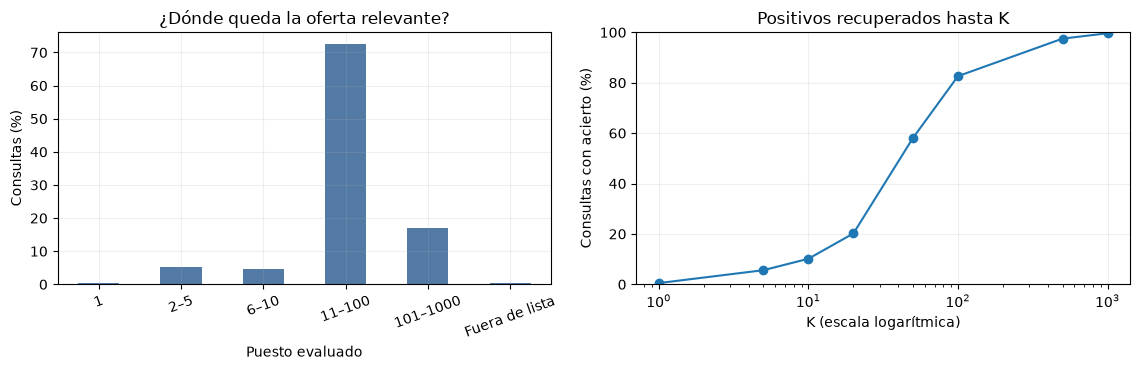

,consultas,MRR,NDCG10,HR10
dia,,,,
2023-07-01,230,0.0397,0.0239,0.0565
2023-08-01,424,0.0613,0.0556,0.1179
2023-09-01,386,0.0490,0.0475,0.1114
2023-10-01,276,0.0692,0.0696,0.1594
2023-11-01,489,0.0508,0.0502,0.1145
2023-12-01,480,0.0429,0.0357,0.0771
2024-01-01,505,0.0576,0.0568,0.1347
2024-02-01,800,0.0400,0.0308,0.0738
2024-03-01,618,0.0451,0.0362,0.0922


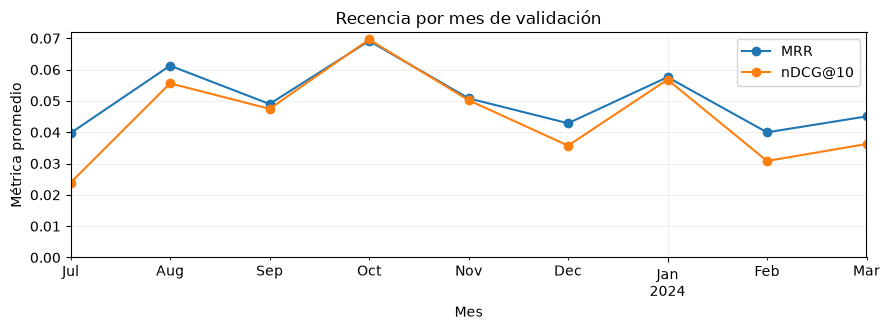

In [30]:
etiquetas_puestos_r = ['1', '2–5', '6–10', '11–100', '101–1000', 'Fuera de lista']
bandas_puesto_r = pd.cut(detalle_recencia['puesto'], [0,1,5,10,100,1000,np.inf], labels=etiquetas_puestos_r)
distribucion_puestos_r = bandas_puesto_r.value_counts(sort=False)
assert distribucion_puestos_r.sum() == len(detalle_recencia)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
(distribucion_puestos_r / len(detalle_recencia) * 100).plot.bar(ax=axes[0], color='#527aa5', rot=20)
axes[0].set(title='¿Dónde queda la oferta relevante?', xlabel='Puesto evaluado', ylabel='Consultas (%)')
valores_k_r = [1,5,10,20,50,100,500,1000]
axes[1].plot(valores_k_r, [100 * detalle_recencia['puesto'].le(k).mean() for k in valores_k_r], marker='o')
axes[1].set_xscale('log')
axes[1].set(title='Positivos recuperados hasta K', xlabel='K (escala logarítmica)', ylabel='Consultas con acierto (%)', ylim=(0,100))
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

mensual_recencia = detalle_recencia.set_index('dia').resample('MS').agg(
    consultas=('RR','size'), MRR=('RR','mean'), NDCG10=('nDCG@10','mean'), HR10=('HitRate@10','mean')
)
display(mensual_recencia.round(4))
assert np.isclose(np.average(mensual_recencia['MRR'], weights=mensual_recencia['consultas']), mrr_recencia['all'])
ax = mensual_recencia[['MRR','NDCG10']].rename(columns={'NDCG10':'nDCG@10'}).plot(marker='o', figsize=(9,3.4))
ax.set(title='Recencia por mes de validación', xlabel='Mes', ylabel='Métrica promedio')
ax.set_ylim(bottom=0)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


#### Resultados según la antigüedad de la oferta

Agrupamos por antigüedad de la oferta relevante al consultar. Es una característica descriptiva del resultado observado, no una variable usada para elegir qué consulta evaluar. Si las ofertas antiguas se recuperan peor, es coherente con ordenar por publicación, pero las diferencias entre grupos no son una prueba causal y se deben leer junto a sus tamaños.


,consultas,MRR,HR10
antiguedad,,,
0–7 días,619,0.2002,0.6834
8–14 días,684,0.0459,0.0058
15–30 días,1450,0.0256,0.0000
31–60 días,883,0.0135,0.0000
61–90 días,270,0.0076,0.0000
91+ días,302,0.0031,0.0000


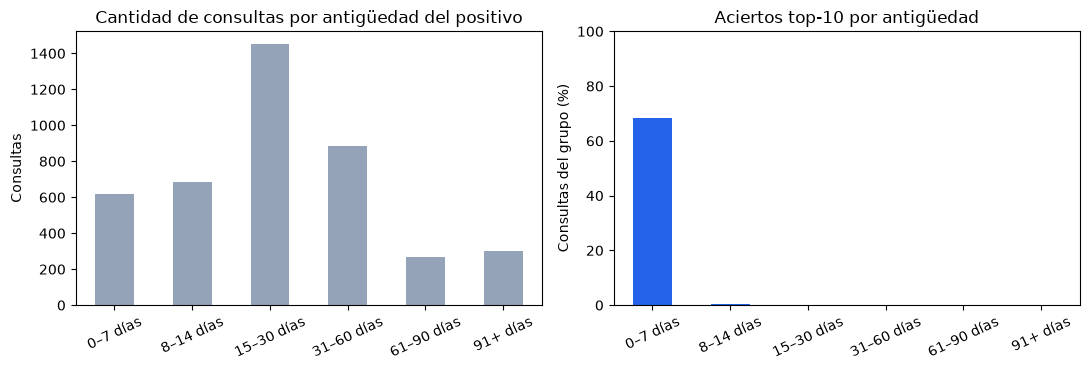

In [31]:
bandas_edad_r = pd.cut(
    detalle_recencia['edad_positivo'], [-1,7,14,30,60,90,np.inf],
    labels=['0–7 días','8–14 días','15–30 días','31–60 días','61–90 días','91+ días']
)
por_edad_recencia = detalle_recencia.assign(antiguedad=bandas_edad_r).groupby('antiguedad', observed=False).agg(
    consultas=('RR','size'), MRR=('RR','mean'), HR10=('HitRate@10','mean')
)
assert por_edad_recencia['consultas'].sum() == len(detalle_recencia)
display(por_edad_recencia.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11,3.8))
por_edad_recencia['consultas'].plot.bar(ax=axes[0], color='#94a3b8', rot=25)
axes[0].set(title='Cantidad de consultas por antigüedad del positivo', xlabel='', ylabel='Consultas')
por_edad_recencia['HR10'].mul(100).plot.bar(ax=axes[1], color='#2563eb', rot=25)
axes[1].set(title='Aciertos top-10 por antigüedad', xlabel='', ylabel='Consultas del grupo (%)', ylim=(0,100))
fig.tight_layout()
plt.show()

fila_global_r = resumen_recencia.iloc[0]


Recencia logra MRR 0,0493, nDCG@10 0,0437 y acierto top-10 en 10,1 % de las 4.208 consultas. Estas métricas describen validación; no son una réplica del resultado de test del paper.

Recencia establece cuánto consigue una señal temporal sencilla sin personalización. Puede priorizar ofertas recientes poco afines y relegar ofertas antiguas todavía activas. El filtro por última actividad de la propuesta es una señal distinta de la fecha de publicación: podría conservar ofertas antiguas que siguen recibiendo procesos.

El siguiente modelo, TF-IDF, deberá demostrar qué aporta la afinidad de atributos bajo estas mismas consultas y reglas.


### 3.4. TF-IDF (baseline propio)

Reutilizamos los campos de `profile_tokens`. Como elección inicial conservadora, el corpus que podrá ajustar IDF contiene **perfiles de entidades con al menos un proceso en entrenamiento reducido**. No incluye entidades que aparecen solo en validación. Los atributos son la instantánea publicada; no disponemos de sus versiones históricas y declaramos esa limitación.

La implementación anterior del repositorio ajusta IDF con todos los perfiles. Aquí lo restringimos al entrenamiento reducido. En las tablas de esta parte, este modelo aparece como «Contenido».


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
from jth.features import profile_tokens, TOKEN_FIELDS

ids_candidatos_fit = set(train_reducido['candidate_id'])
ids_ofertas_fit = set(train_reducido['job_id'])
candidatos_fit_contenido = candidatos[candidatos['candidate_id'].isin(ids_candidatos_fit)].copy()
ofertas_fit_contenido = ofertas[ofertas['job_id'].isin(ids_ofertas_fit)].copy()
docs_candidatos_fit = profile_tokens(candidatos_fit_contenido)
docs_ofertas_fit = profile_tokens(ofertas_fit_contenido)
docs_fit_contenido = docs_candidatos_fit + docs_ofertas_fit

assert set(candidatos_fit_contenido['candidate_id']) == ids_candidatos_fit
assert set(ofertas_fit_contenido['job_id']) == ids_ofertas_fit
assert not {'llm_sex','llm_nationality','llm_age_bucket'}.intersection(TOKEN_FIELDS)

def identidad_tokens_contenido(tokens):
    return tokens

vectorizador_contenido_preparado = TfidfVectorizer(
    analyzer=identidad_tokens_contenido, sublinear_tf=True, norm='l2'
)
assert not hasattr(vectorizador_contenido_preparado, 'vocabulary_')

display(pd.DataFrame([
    {'Corpus preparado': nombre, 'Documentos': len(docs),
     'Documentos vacíos': sum(not doc for doc in docs)}
    for nombre, docs in [('Candidatos de train reducido', docs_candidatos_fit),
                        ('Ofertas de train reducido', docs_ofertas_fit), ('Total para futuro ajuste', docs_fit_contenido)]
]))
display(pd.DataFrame({'Campo seleccionado':list(TOKEN_FIELDS), 'Espacio de tokens':list(TOKEN_FIELDS.values())}))
print('Estado: corpus preparado y vectorizador SIN ajustar. No hay métricas de contenido todavía.')


,Corpus preparado,Documentos,Documentos vacíos
0,Candidatos de train reducido,18191,0
1,Ofertas de train reducido,3296,1
2,Total para futuro ajuste,21487,1


,Campo seleccionado,Espacio de tokens
0,skills,s
1,llm_hard_skills,s
2,llm_programming_languages,s
3,llm_tools_technologies,s
4,expertise_area,a
5,llm_expertise_area,a
6,job_category,c
7,llm_job_category,c


Estado: corpus preparado y vectorizador SIN ajustar. No hay métricas de contenido todavía.


El vocabulario determina qué tokens conoce y el IDF cuánto discrimina cada token en el corpus de ajuste. Después transformaremos los perfiles de consulta y las ofertas disponibles usando ese vocabulario congelado. Los tokens nuevos no vistos durante el ajuste no crearán dimensiones nuevas.


Ajustamos con los documentos preparados y transformamos los perfiles con el vocabulario congelado. Los perfiles de validación pueden aportar sus atributos para una consulta, pero no contribuyen al IDF. Seguimos asumiendo que la instantánea publicada representa atributos disponibles para el benchmark; no demuestra disponibilidad histórica exacta.


In [33]:
t_contenido=time.perf_counter()
vectorizador_contenido_preparado.fit(docs_fit_contenido)
vocab_contenido=dict(vectorizador_contenido_preparado.vocabulary_)
idf_contenido=vectorizador_contenido_preparado.idf_.copy()
docs_candidatos_todos=profile_tokens(candidatos)
docs_ofertas_todas=profile_tokens(ofertas)
Q_contenido=vectorizador_contenido_preparado.transform(docs_candidatos_todos)
T_contenido=vectorizador_contenido_preparado.transform(docs_ofertas_todas).T.tocsr()
assert vocab_contenido==vectorizador_contenido_preparado.vocabulary_
assert np.array_equal(idf_contenido,vectorizador_contenido_preparado.idf_)
indice_candidatos_modelos=pd.Index([evaluador_oficial._parse_id(x) for x in candidatos['candidate_id']])
filas_candidatos_consulta=indice_candidatos_modelos.get_indexer([k[0] for k in claves_modelos])
assert (filas_candidatos_consulta>=0).all()
vector_cero_consulta=Q_contenido[filas_candidatos_consulta].getnnz(axis=1)==0
vector_cero_oferta=T_contenido.getnnz(axis=0)==0
display(pd.DataFrame({'Medida':['Documentos de ajuste','Dimensiones aprendidas','Consultas con vector cero',
                              'Ofertas del archivo con vector cero'],
                      'Cantidad':[len(docs_fit_contenido),len(vocab_contenido),int(vector_cero_consulta.sum()),
                                  int(vector_cero_oferta.sum())]}))


,Medida,Cantidad
0,Documentos de ajuste,21487
1,Dimensiones aprendidas,1151
2,Consultas con vector cero,132
3,Ofertas del archivo con vector cero,1


Para cada consulta calculamos coseno, aplicamos la máscara temporal y seleccionamos top-1000 con la prioridad acordada. Reportamos vectores cero y casos sin ninguna similitud positiva como diagnósticos distintos: un vector no nulo también puede no compartir vocabulario con las ofertas elegibles.


Contenido : coincide con evaluador oficial en global/warm/cold.


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Recencia,4208.0,0.04930,0.04374,0.10147,0.04674,0.05064,0.38023
Contenido,4208.0,0.06095,0.06689,0.12999,0.03700,0.07351,14.78137


,Grupo,Consultas,MRR
0,Vector cero,132,0.001700
1,Vector no cero,4076,0.062869
2,Sin similitud positiva,132,0.001700


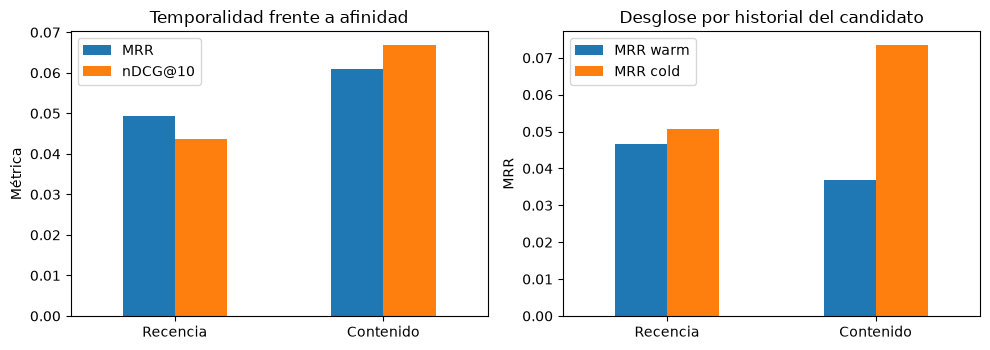

In [34]:
listas_contenido=[]
sin_similitud_positiva=[]
for i,clave in enumerate(claves_modelos):
    scores=(Q_contenido[filas_candidatos_consulta[i]] @ T_contenido).toarray().ravel()
    elegibles=elegibles_modelos(clave[1])
    sin_similitud_positiva.append(not np.any(scores[elegibles]>0))
    listas_contenido.append(ordenar_scores_modelos(scores,elegibles))
rankings_modelos['Contenido']=listas_contenido
resultados_modelos['Contenido'],detalles_modelos['Contenido']=verificar_oficial_modelos('Contenido',listas_contenido)
segundos_contenido=time.perf_counter()-t_contenido
display(pd.DataFrame(resultados_modelos).T.round(5))
diagnosticos_contenido=[]
for nombre,mask in [('Vector cero',vector_cero_consulta),('Vector no cero',~vector_cero_consulta),
                    ('Sin similitud positiva',np.array(sin_similitud_positiva))]:
    diagnosticos_contenido.append({'Grupo':nombre,'Consultas':int(mask.sum()),
        'MRR':detalles_modelos['Contenido']['RR'][mask].mean() if mask.any() else np.nan})
display(pd.DataFrame(diagnosticos_contenido))
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
pd.DataFrame(resultados_modelos).T[['MRR','nDCG@10']].plot.bar(ax=axes[0],rot=0)
pd.DataFrame(resultados_modelos).T[['MRR warm','MRR cold']].plot.bar(ax=axes[1],rot=0)
axes[0].set(title='Temporalidad frente a afinidad',ylabel='Métrica')
axes[1].set(title='Desglose por historial del candidato',ylabel='MRR')
fig.tight_layout(); plt.show()


TF-IDF cambia el MRR en +0,0117 frente a Recencia. Es un resultado de validación, no una mejora confirmada en test.

Esta comparación separa dos señales simples, publicación reciente y afinidad de atributos. Un resultado inferior de TF-IDF no implica que los atributos sean inútiles: puede señalar falta de tiempo, vocabulario imperfecto o diferencias entre perfiles y necesidades. No añadimos una recencia escondida para mejorar el baseline. El siguiente control fuerte será LR, que ya combina atributos y variables temporales.


### 3.5. Regresión logística y CF oficial

Ejecutamos los programas oficiales con los mismos 29.599 procesos de entrenamiento y 4.231 procesos de validación. No reutilizamos las cifras históricas del grupo para esta comparación.

- **LR:** negativo por positivo, semilla 42, modelo logreg, features temporales y LLM, StandardScaler ajustado en train. El programa oficial imputa campos usando los perfiles completos, muestrea negativos de todo el catálogo y conserva peculiaridades de parsing. Son límites heredados de la referencia; no la presentamos como un pipeline de covariables históricas perfectamente reconstruidas.
- **CF + recencia:** ventana oficial de 90 días desde publicación y actualizaciones después de puntuar cada día. No es nuestra futura ventana de actividad. El código usa un catálogo transductivo de IDs de train/val y tiene desempates c2j dependientes del orden de conjuntos; fijamos `PYTHONHASHSEED=42` y no corregimos silenciosamente su algoritmo.
- Ninguna referencia usa etapas finales como etiquetas nuevas ni procesos de validación para entrenar inicialmente. Los atributos sensibles explícitos no forman parte de los feature names usados por LR ni de TF-IDF.

El registro debe mostrar exactamente 29.599 positivos y 29.599 negativos en LR. Alineamos sus scores completos con las consultas y ofertas del notebook. Comprobamos para **todas** las consultas que ordenar esos scores reproduce la lista oficial original antes del filtro de futuras ofertas. Esto permite aplicar actividad antes de truncar, sin fingir que filtrar una lista vieja recupera ofertas que ya estaban fuera.


LR oficial : coincide con evaluador oficial en global/warm/cold.


CF + recencia oficial : coincide con evaluador oficial en global/warm/cold.


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Recencia,4208.0,0.04930,0.04374,0.10147,0.04674,0.05064,0.38023
Contenido,4208.0,0.06095,0.06689,0.12999,0.03700,0.07351,14.78137
LR oficial,4208.0,0.31620,0.37056,0.59387,0.25093,0.35044,0.30894
CF + recencia oficial,4208.0,0.11604,0.11555,0.15684,0.28384,0.02801,4.01616


,Dato de ajuste LR,Valor
0,Positivos,29599
1,Negativos,29599
2,Features no constantes,49
3,Iteraciones solver,[18]


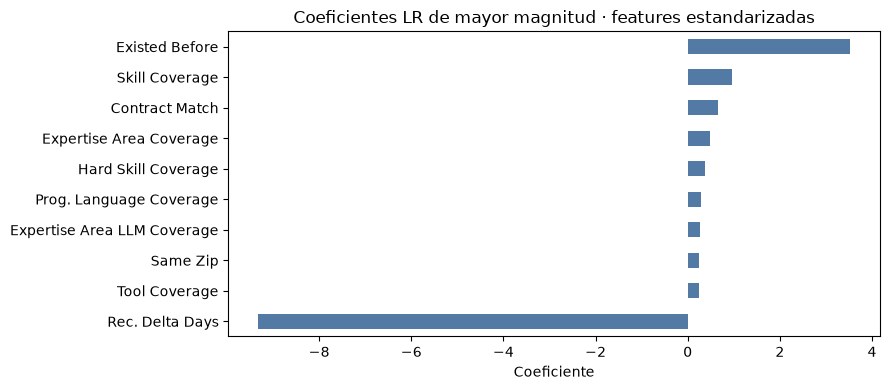

In [35]:
fit_lr=json.loads((cache_referencias/'lr/fit.json').read_text())
assert fit_lr['positives']==len(train_reducido) and fit_lr['negatives']==len(train_reducido)
preds_lr=evaluador_oficial.load_preds(cache_referencias/'lr/lr_c2j.pkl.gz')
preds_cf=evaluador_oficial.load_preds(cache_referencias/'cf/cf_c2j.pkl.gz')
keys_cache=[(evaluador_oficial._parse_id(k[0]),k[1]) for k in json.loads((cache_referencias/'keys.json').read_text())]
jobs_cache=[evaluador_oficial._parse_id(k) for k in json.loads((cache_referencias/'jobs.json').read_text())]
assert jobs_cache==job_ids_modelos.tolist()
indices_cache=pd.Index(keys_cache).get_indexer(claves_modelos)
assert (indices_cache>=0).all()
scores_lr_cache=np.load(cache_referencias/'lr/scores_full.npy',mmap_mode='r')
for i,key in enumerate(claves_modelos):
    score=np.asarray(scores_lr_cache[indices_cache[i]])
    reconstruida=job_ids_modelos[np.argsort(-score,kind='stable')[:1000]]
    assert np.array_equal(reconstruida,preds_lr[key])
for nombre,preds in [('LR oficial',preds_lr),('CF + recencia oficial',preds_cf)]:
    rankings_modelos[nombre]=indices_desde_oficial(preds)
    resultados_modelos[nombre],detalles_modelos[nombre]=verificar_oficial_modelos(nombre,rankings_modelos[nombre])
display(pd.DataFrame(resultados_modelos).T.round(5))
display(pd.DataFrame({'Dato de ajuste LR':['Positivos','Negativos','Features no constantes','Iteraciones solver'],
                      'Valor':[fit_lr['positives'],fit_lr['negatives'],len(fit_lr['features']),fit_lr['n_iter']]}))
coef_lr=pd.Series(fit_lr['coefficients'],index=fit_lr['features'])
seleccion_coef=coef_lr.abs().nlargest(10).index
ax=coef_lr.loc[seleccion_coef].sort_values().plot.barh(figsize=(9,4),color='#527aa5')
ax.set(title='Coeficientes LR de mayor magnitud · features estandarizadas',xlabel='Coeficiente',ylabel='')
plt.tight_layout(); plt.show()


Los coeficientes describen el ajuste de esta referencia condicionada a su muestreo de negativos y su parsing; no son efectos causales ni relevancias comparables entre variables correlacionadas. La salida de LR tampoco es una probabilidad calibrada de contratación: se aprendió a distinguir procesos de negativos muestreados con proporción artificial 1:1. El desglose warm/cold permite comprobar si CF y LR son complementarios en esta validación, sin asumir que la diferencia histórica se repetirá.

Antes de medir actividad añadimos **LR elegible**: mismo score, ofertas futuras excluidas antes del top-1000. Si difiere de LR oficial, ese efecto corresponde al catálogo/corte, no al componente temporal nuevo.


In [36]:
tie_lr=np.arange(len(ofertas))
listas_lr_elegible=[ordenar_scores_modelos(scores_lr_cache[indices_cache[i]],elegibles_modelos(k[1]),tie_lr)
                    for i,k in enumerate(claves_modelos)]
rankings_modelos['LR elegible']=listas_lr_elegible
resultados_modelos['LR elegible'],detalles_modelos['LR elegible']=verificar_oficial_modelos('LR elegible',listas_lr_elegible)
display(pd.DataFrame(resultados_modelos).T.round(5))
ganancias_cf=detalles_modelos['CF + recencia oficial']['RR']-detalles_modelos['LR oficial']['RR']
display(pd.DataFrame({'Comparación por consulta':['CF mejor que LR','LR mejor que CF','Mismo RR'],
                      'Consultas':[int((ganancias_cf>0).sum()),int((ganancias_cf<0).sum()),int((ganancias_cf==0).sum())]}))
listas_lr_neutral=[ordenar_scores_modelos(np.log(np.clip(scores_lr_cache[indices_cache[i]],1e-15,1)),
                   elegibles_modelos(k[1]),tie_lr) for i,k in enumerate(claves_modelos)]
assert all(np.array_equal(a,b) for a,b in zip(listas_lr_neutral,listas_lr_elegible))
del listas_lr_neutral
print('Penalización suave con λ=0 conserva exactamente LR elegible: OK.')


LR elegible : coincide con evaluador oficial en global/warm/cold.


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Recencia,4208.0,0.04930,0.04374,0.10147,0.04674,0.05064,0.38023
Contenido,4208.0,0.06095,0.06689,0.12999,0.03700,0.07351,14.78137
LR oficial,4208.0,0.31620,0.37056,0.59387,0.25093,0.35044,0.30894
CF + recencia oficial,4208.0,0.11604,0.11555,0.15684,0.28384,0.02801,4.01616
LR elegible,4208.0,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517


,Comparación por consulta,Consultas
0,CF mejor que LR,768
1,LR mejor que CF,3343
2,Mismo RR,97


Penalización suave con λ=0 conserva exactamente LR elegible: OK.


### 3.6. CF sin catálogo transductivo

El CF oficial construye su catálogo con las ofertas del período evaluado, de modo que una oferta que recibirá un positivo futuro ya está en el conjunto. Además, sobrescribe similitudes entre las ofertas pasadas del candidato y sus empates de score cero siguen el orden de un `set`. Conservamos esa cifra, rotulada como **catálogo transductivo**, y agregamos un **CF limpio**: la misma similitud coseno, sumada sobre el historial del candidato, sobre todas las ofertas elegibles y con el desempate fijo del notebook.


In [37]:
import scipy.sparse as sp
from jth import systems as sis
from jth.activity import daily_states
from jth.clean_cf import clean_cf_scores

# El estado diario de las ofertas se explica en 4.1. Aquí da la regla de 90 días del CF.
estados_actividad = daily_states(ctx, train_reducido, validacion)
similitud_cf = sp.csr_matrix(clean_cf_scores(ctx, train_reducido, validacion))
extra_v2 = {'tfidf': lambda ix: (Q_contenido[filas_candidatos_consulta[ix]] @ T_contenido).toarray()}
entradas = sis.Inputs(ctx, estados_actividad, scores_lr_cache, np.asarray(indices_cache), similitud_cf, extra_v2)
registro = sis.Registry(ctx)

listas_cf_limpio = entradas.lists(sis.plain(sis.cf_reference))
registrar_final('CF limpio', listas_cf_limpio)

ofertas_train, ofertas_evaluadas = set(train_reducido['job_id']), set(validacion['job_id'])
catalogo_oficial = ofertas_train | ofertas_evaluadas
display(pd.DataFrame({
    'Medida': ['Ofertas en el catálogo del CF oficial', 'De ellas, ofertas que solo aparecen en validación',
               'Ofertas elegibles al final de validación', 'Consultas cuyo positivo está en ese catálogo (%)'],
    'Valor': [len(catalogo_oficial), len(ofertas_evaluadas - ofertas_train), int(ctx.eligible(dias_modelos.max()).sum()),
              100 * np.isin(validacion['job_id'], list(catalogo_oficial)).mean()],
}))
display(pd.DataFrame({'CF oficial (catálogo transductivo)': resultados_modelos['CF + recencia oficial'], 'CF limpio': resultados_v2['CF limpio']}).T.round(5))


CF limpio : coincide con evaluador oficial en global/warm/cold.


,Medida,Valor
0,Ofertas en el catálogo del CF oficial,3697.0
1,"De ellas, ofertas que solo aparecen en validación",401.0
2,Ofertas elegibles al final de validación,5579.0
3,Consultas cuyo positivo está en ese catálogo (%),100.0


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
CF oficial (catálogo transductivo),4208.0,0.11604,0.11555,0.15684,0.28384,0.02801,4.01616
CF limpio,4208.0,0.12615,0.12649,0.16801,0.29696,0.03653,5.67966


El CF oficial queda -0,0101 de MRR respecto del limpio, y -0,0085 en candidatos nuevos. La diferencia mezcla tres cambios (catálogo, suma de similitudes y desempate), así que no se atribuye solo a la fuga. Este límite también afecta a la referencia del paper.

## Parte 4. Etapa 1: filtro de vigencia

La propuesta plantea modelar la vigencia de cada oferta y usarla como contexto. No tenemos una etiqueta de apertura real, así que usamos la actividad como aproximación. Una oferta puede seguir abierta sin procesos en estos datos.


### 4.1. Señal de actividad

Construimos el estado de cada oferta antes de cada día de validación. Hay dos señales distintas: **popularidad con decaimiento** y **tiempo desde última actividad**. Ambas usan solo procesos anteriores al día; las repeticiones cuentan como procesos, a diferencia de la representación binaria de CF.

La actividad no es una etiqueta de apertura real. Las fechas desconocidas conservan elegibilidad según el evaluador; si tampoco hay historial, la penalización del suave fijo será neutral. En estos datos las ofertas tienen fecha de creación, pero dejamos la política especificada.

Para popularidad reciente usamos `A(j,t;τ)=Σ exp(-(t-ti)/τ)` con `ti<t`. Para la penalización del suave fijo usamos el tiempo desde última actividad; si no existe, usamos edad desde publicación. Un evento del día actual solo modifica el estado para días posteriores.


#### Popularidad reciente

Este modelo ordena por la popularidad con decaimiento definida arriba, `A(j,t;τ)`. Probamos τ de 7, 30 y 90 días, declarados de antemano, para medir cuánto puede explicar esta señal sola. Las ofertas sin actividad tienen score cero, no se eliminan; el desempate usa la prioridad ya fijada. Elegir el mejor τ aquí es ajuste de hiperparámetros sobre validación.


In [38]:
from jth.activity import TAUS as TAUS_ACTIVIDAD

estados_por_consulta = [estados_actividad[k[1]] for k in claves_modelos]

def parametros_primero(tabla, *columnas):
    return tabla[[*columnas, *tabla.columns.difference(columnas, sort=False)]]

grid_actividad=[]
mejor_actividad=None
for tau in TAUS_ACTIVIDAD:
    listas=[ordenar_scores_modelos(s['decay'][tau],s['eligible']) for s in estados_por_consulta]
    res,det=metricas_listas_modelos(listas)
    grid_actividad.append(dict(tau=tau,**res))
    if mejor_actividad is None or (res['MRR'],res['nDCG@10'])>(mejor_actividad[0]['MRR'],mejor_actividad[0]['nDCG@10']):
        mejor_actividad=(res,listas,det,tau)
grid_actividad=pd.DataFrame(grid_actividad)
rankings_modelos['Popularidad reciente']=mejor_actividad[1]
resultados_modelos['Popularidad reciente'],detalles_modelos['Popularidad reciente']=verificar_oficial_modelos('Popularidad reciente',mejor_actividad[1])
display(grid_actividad.round(5))


Popularidad reciente : coincide con evaluador oficial en global/warm/cold.


,tau,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,7,4208,0.20343,0.24307,0.43346,0.19315,0.20882,10.33745
1,30,4208,0.14316,0.16523,0.30228,0.12682,0.15173,10.33745
2,90,4208,0.09088,0.10186,0.19202,0.06920,0.10225,10.38498


### 4.2. Filtro duro y suave fijo sobre LR

- **Duro:** conservar actividad previa en `w∈{7,14,30,60,90}` días. Comparar sin protección de ofertas nuevas (`g=0`, desactivada) y con gracia por publicación de siete días (`g=7`).
- **Suave fijo:** `log(p_LR)+λ log(g_actividad)`, donde `g_actividad=exp(-lag_efectivo/τ)`. Probamos `τ∈{7,30,90}` y `λ∈{0.25,0.5,1}`. Es un peso heurístico, no probabilidad calibrada de vigencia.
- LR elegible es el control común. Un valor de λ cero debe recuperar ese control exactamente. La multiplicación de probabilidades positivas y la formulación logarítmica son equivalentes salvo el recorte numérico de estabilidad.

El filtro se aplica a **todos los scores LR antes de top-1000**. Si elimina el positivo, la consulta permanece con RR cero. La protección de ofertas nuevas no se basa en el positivo: se calcula para todo el catálogo con su fecha de creación.


In [39]:
from jth.activity import GRACE_DAYS as GRACIAS_NUEVAS, HARD_WINDOWS as VENTANAS_DURO, SOFT_LAMBDAS as LAMBDAS_SUAVE, SOFT_TAUS as TAUS_SUAVE, hard_mask as mascara_dura_modelos

def cobertura_mascaras_modelos(mascaras):
    return np.array([m[j] for m,j in zip(mascaras,gold_indices_modelos)])

# Prueba inventada: historial reciente, nueva sin historial, vieja sin historial y futura.
estado_toy={'age':np.array([100.,2.,100.,-1.]),'lag':np.array([2.,np.inf,np.inf,np.inf]),
            'eligible':np.array([True,True,True,False])}
assert mascara_dura_modelos(estado_toy,7,0).tolist()==[True,False,False,False]
assert mascara_dura_modelos(estado_toy,7,7).tolist()==[True,True,False,False]
assert np.isclose(np.log(.3)+0*(-200/30),np.log(.3))
print('Pruebas de filtro, rescate de nueva, futuro excluido y peso cero: OK.')

grid_duro=[]; best_duro=None
for w in VENTANAS_DURO:
    for gracia in GRACIAS_NUEVAS:
        mascaras=[mascara_dura_modelos(s,w,gracia) for s in estados_por_consulta]
        listas=[ordenar_scores_modelos(scores_lr_cache[indices_cache[i]],m,tie_lr) for i,m in enumerate(mascaras)]
        res,det=metricas_listas_modelos(listas)
        cobertura=cobertura_mascaras_modelos(mascaras)
        fila=dict(res,w=w,gracia=gracia,Cobertura_pool=100*cobertura.mean(),
                  Positivos_eliminados=int((~cobertura).sum()),Pool_mediano_consulta=float(np.median([m.sum() for m in mascaras])))
        grid_duro.append(fila)
        if best_duro is None or (res['MRR'],res['nDCG@10'])>(best_duro[0]['MRR'],best_duro[0]['nDCG@10']):
            best_duro=(fila,listas,det)
grid_duro=pd.DataFrame(grid_duro)
rankings_modelos['LR + duro']=best_duro[1]
resultados_modelos['LR + duro'],detalles_modelos['LR + duro']=verificar_oficial_modelos('LR + duro',best_duro[1])

grid_suave=[]; best_suave=None
for tau in TAUS_SUAVE:
    for lam in LAMBDAS_SUAVE:
        listas=[]
        for i,s in enumerate(estados_por_consulta):
            score=np.log(np.clip(scores_lr_cache[indices_cache[i]],1e-15,1))-lam*s['effective_lag']/tau
            listas.append(ordenar_scores_modelos(score,s['eligible'],tie_lr))
        res,det=metricas_listas_modelos(listas)
        fila=dict(res,tau=tau,lambda_=lam)
        grid_suave.append(fila)
        if best_suave is None or (res['MRR'],res['nDCG@10'])>(best_suave[0]['MRR'],best_suave[0]['nDCG@10']):
            best_suave=(fila,listas,det)
grid_suave=pd.DataFrame(grid_suave)
rankings_modelos['LR + suave fijo']=best_suave[1]
resultados_modelos['LR + suave fijo'],detalles_modelos['LR + suave fijo']=verificar_oficial_modelos('LR + suave fijo',best_suave[1])
display(parametros_primero(grid_duro, 'w', 'gracia').round(5)); display(parametros_primero(grid_suave, 'tau', 'lambda_').round(5))


Pruebas de filtro, rescate de nueva, futuro excluido y peso cero: OK.


LR + duro : coincide con evaluador oficial en global/warm/cold.


LR + suave fijo : coincide con evaluador oficial en global/warm/cold.


,w,gracia,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%),Cobertura_pool,Positivos_eliminados,Pool_mediano_consulta
0,7,0,4208,0.35812,0.41637,0.62500,0.30389,0.38656,22.78992,77.21008,959,54.0
1,7,7,4208,0.36203,0.42334,0.64971,0.30651,0.39117,15.44677,84.55323,650,62.0
2,14,0,4208,0.35083,0.41036,0.63189,0.29453,0.38037,16.06464,83.93536,676,79.0
3,14,7,4208,0.35813,0.42024,0.65708,0.30033,0.38845,8.72148,91.27852,367,85.0
4,30,0,4208,0.33483,0.39189,0.61145,0.27450,0.36648,12.57129,87.42871,529,110.0
5,30,7,4208,0.34383,0.40488,0.64282,0.28176,0.37640,5.22814,94.77186,220,118.0
6,60,0,4208,0.32419,0.37768,0.58888,0.26113,0.35727,11.14544,88.85456,469,162.0
7,60,7,4208,0.33428,0.39161,0.62048,0.26970,0.36817,3.80228,96.19772,160,171.0
8,90,0,4208,0.32029,0.37300,0.58175,0.25746,0.35326,10.88403,89.11597,458,222.0
9,90,7,4208,0.33099,0.38783,0.61502,0.26653,0.36481,3.54087,96.45913,149,231.0


,tau,lambda_,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,7,0.25,4208,0.33309,0.39194,0.62619,0.29595,0.35258,0.23764
1,7,0.50,4208,0.29240,0.35231,0.59316,0.26332,0.30765,0.23764
2,7,1.00,4208,0.24909,0.30542,0.54016,0.22753,0.26040,0.28517
3,30,0.25,4208,0.37925,0.43962,0.67205,0.33115,0.40449,0.28517
4,30,0.50,4208,0.36151,0.42208,0.65803,0.32093,0.38279,0.26141
5,30,1.00,4208,0.33586,0.39488,0.62928,0.29836,0.35553,0.23764
6,90,0.25,4208,0.38573,0.44701,0.67966,0.33391,0.41292,0.30894
7,90,0.50,4208,0.38399,0.44485,0.67752,0.33483,0.40977,0.30894
8,90,1.00,4208,0.37313,0.43352,0.66730,0.32893,0.39633,0.28517


La protección de nuevas ofertas puede recuperar cobertura y a la vez añadir competencia al ranking. La ventana que conserva más positivos no necesariamente maximiza MRR. El suave fijo conserva el catálogo elegible pero puede desplazar un positivo fuera de top-1000. Presentamos todas las configuraciones y no solo la fila ganadora.

La penalización exponencial depende de `λ/τ`: esos parámetros controlan juntos una única intensidad. Parejas distintas podrían ser equivalentes; no interpretamos sus efectos como independientes. En el resumen congelamos la pareja concreta elegida.


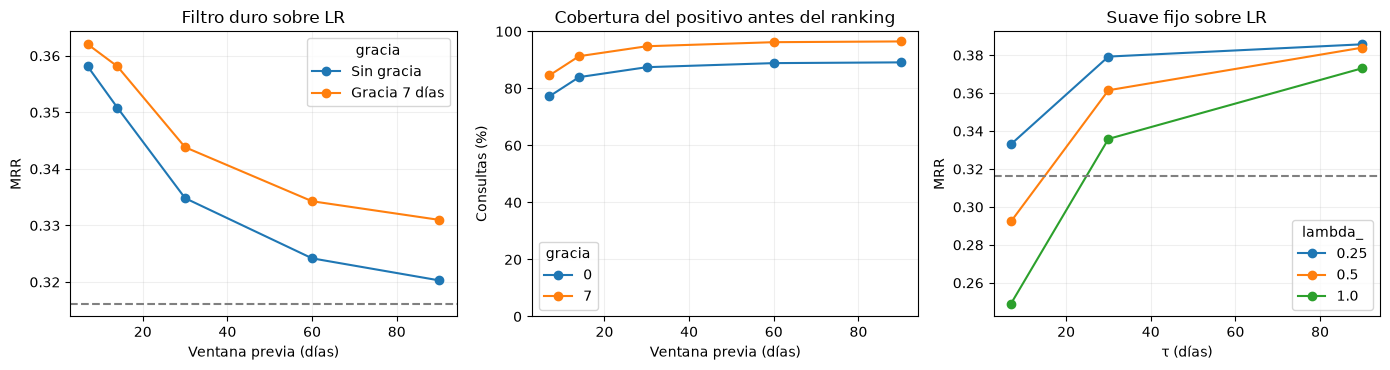

,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Recencia,4208.0,0.04930,0.04374,0.10147,0.04674,0.05064,0.38023
Contenido,4208.0,0.06095,0.06689,0.12999,0.03700,0.07351,14.78137
LR oficial,4208.0,0.31620,0.37056,0.59387,0.25093,0.35044,0.30894
CF + recencia oficial,4208.0,0.11604,0.11555,0.15684,0.28384,0.02801,4.01616
LR elegible,4208.0,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517
Popularidad reciente,4208.0,0.20343,0.24307,0.43346,0.19315,0.20882,10.33745
LR + duro,4208.0,0.36203,0.42334,0.64971,0.30651,0.39117,15.44677
LR + suave fijo,4208.0,0.38573,0.44701,0.67966,0.33391,0.41292,0.30894


In [40]:
fig,axes=plt.subplots(1,3,figsize=(14,3.8))
grid_duro.pivot(index='w',columns='gracia',values='MRR').rename(columns={0:'Sin gracia',7:'Gracia 7 días'}).plot(ax=axes[0],marker='o')
axes[0].axhline(resultados_modelos['LR elegible']['MRR'],color='gray',ls='--',label='LR elegible')
axes[0].set(title='Filtro duro sobre LR',xlabel='Ventana previa (días)',ylabel='MRR')
grid_duro.pivot(index='w',columns='gracia',values='Cobertura_pool').plot(ax=axes[1],marker='o')
axes[1].set(title='Cobertura del positivo antes del ranking',xlabel='Ventana previa (días)',ylabel='Consultas (%)',ylim=(0,100))
grid_suave.pivot(index='tau',columns='lambda_',values='MRR').plot(ax=axes[2],marker='o')
axes[2].axhline(resultados_modelos['LR elegible']['MRR'],color='gray',ls='--')
axes[2].set(title='Suave fijo sobre LR',xlabel='τ (días)',ylabel='MRR')
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
display(pd.DataFrame(resultados_modelos).T.round(5))


Sobre el control comparable LR elegible, el filtro duro aporta +0,0458 de MRR y el suave fijo +0,0695. El mejor filtro duro elimina 650 positivos antes de ordenar. Son diferencias de validación tras selección de parámetros.

### 4.3. Suave aprendido: P(actividad)

La propuesta plantea ponderar cada oferta por una probabilidad estimada de seguir vigente. Aquí agregamos esa versión junto al suave fijo de 4.2: en vez de fijar cómo cae el peso con el tiempo, lo aprendemos de los datos.

Para eso tomamos una fotografía semanal de todas las ofertas ya publicadas durante el entrenamiento reducido. Cada fila es una oferta en una fecha y describe lo que se sabía de ella en ese momento. Una regresión logística sobre esas filas entrega, para cualquier oferta en cualquier día, la probabilidad de que reciba un nuevo proceso pronto. Esa probabilidad reemplaza al peso del suave fijo en el score de LR.

- **Variables:** logaritmo del tiempo desde la última actividad, indicador de que no hubo actividad, logaritmo de la edad y logaritmo del volumen reciente.
- **Etiqueta:** al menos un proceso nuevo en los siguientes H días, con H de 7 y 30. Las fotografías a menos de H días del corte se descartan porque su etiqueta está incompleta.
- **Uso:** `log p_LR + λ log P(actividad)`, con λ de 0,25, 0,5 y 1.

La etiqueta mide actividad futura, no apertura real: una oferta puede seguir abierta sin procesos en estos datos. Por eso la llamamos P(actividad).


In [41]:
from jth.activity_model import HORIZONS, LAMBDAS, fit_activity_model, predict_log_activity, snapshots
from sklearn.metrics import brier_score_loss, roc_auc_score

dias_a_int = lambda serie: pd.to_datetime(serie).to_numpy(dtype='datetime64[D]').astype(int)
ids_a_pos = lambda serie: ctx.job_index.get_indexer([evaluador_oficial._parse_id(x) for x in serie])
dias_train_int, jobs_train_pos = dias_a_int(train_reducido['timestamp']), ids_a_pos(train_reducido['job_id'])
dias_val_int, jobs_val_pos = dias_a_int(validacion['timestamp']), ids_a_pos(validacion['job_id'])
corte_int = int(dias_val_int.min())
todos_dias, todos_jobs = np.concatenate([dias_train_int, dias_val_int]), np.concatenate([jobs_train_pos, jobs_val_pos])

modelos_actividad, calibracion_filas = {}, []
dias_estado = sorted(estados_actividad)
for H in HORIZONS:
    x, y = snapshots(dias_train_int, jobs_train_pos, ctx.job_dates, H, corte_int)
    modelo = fit_activity_model(x, y)
    x_val, y_val = snapshots(todos_dias, todos_jobs, ctx.job_dates, H, int(dias_val_int.max()) + 1, start_day=corte_int)
    p_val = modelo.predict_proba(x_val)[:, 1]
    activas_90 = (x_val[:, 1] == 0) & (np.expm1(x_val[:, 0]) <= 90)
    calibracion_filas.append({'H (días)': H, 'Fotografías de ajuste': len(y), 'Tasa positiva (ajuste)': y.mean(),
                              'AUC (período de validación)': roc_auc_score(y_val, p_val),
                              'AUC (activas en 90 días)': roc_auc_score(y_val[activas_90], p_val[activas_90]), 'Brier': brier_score_loss(y_val, p_val),
                              'Tasa observada (validación)': y_val.mean(), 'Promedio predicho (validación)': p_val.mean()})
    modelos_actividad[H] = np.stack([predict_log_activity(modelo, {d: estados_actividad[d]})[d] for d in dias_estado])
    for lam in LAMBDAS:
        registro.add('LR + suave aprendido', {'H': H, 'lambda': lam}, entradas.ranks(sis.lr_activity_model(modelos_actividad[H], lam)))
display(pd.DataFrame(calibracion_filas).round(4))

display(registro.table('LR + suave aprendido').round(5))
mejor_pa = summarize_ranks(ctx, registro.best('LR + suave aprendido')['ranks'])


,H (días),Fotografías de ajuste,Tasa positiva (ajuste),AUC (período de validación),AUC (activas en 90 días),Brier,Tasa observada (validación),Promedio predicho (validación)
0,7,741939,0.0142,0.9896,0.8976,0.0043,0.0076,0.007
1,30,721568,0.0234,0.9813,0.8811,0.0066,0.0124,0.011


,H,lambda,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,7,0.25,4208,0.37378,0.42152,0.61977,0.33679,0.39318,0.30894
1,7,0.50,4208,0.34763,0.38985,0.57343,0.31513,0.36468,0.30894
2,7,1.00,4208,0.31377,0.35495,0.53731,0.28646,0.32810,0.28517
3,30,0.25,4208,0.37412,0.42919,0.64710,0.33160,0.39642,0.30894
4,30,0.50,4208,0.35123,0.40045,0.60385,0.31014,0.37279,0.30894
5,30,1.00,4208,0.31975,0.36619,0.56321,0.28417,0.33842,0.28517


Las probabilidades coinciden en promedio con lo observado. El AUC global es alto en buena parte porque la mayoría de las ofertas lleva meses sin actividad y es fácil descartarla. Entre las ofertas activas en los últimos 90 días baja a 0,90 con H = 7 y 0,88 con H = 30.

El suave aprendido alcanza MRR 0,3741 frente a 0,3857 del suave fijo, una diferencia de -0,0116. La calibración indica si la probabilidad se puede leer como tal; el MRR solo mide si ordena bien. El mejor λ queda en el borde de la grilla, igual que en el suave fijo.

### 4.4. Filtros en todos los modelos

Hasta aquí el filtro solo se aplicó a LR. La propuesta plantea medirlo también sobre las demás referencias: si la señal de vigencia sirve por sí misma, debería ayudar a modelos muy distintos. Aplicamos las mismas 10 configuraciones duras y 9 de suave fijo de 4.2, y las 6 de suave aprendido de 4.3, antes del corte top-1000, a Most Popular, Recencia, CF limpio y TF-IDF. Random lleva una sola configuración de control por filtro: como no tiene señal propia, muestra cuánto consigue el filtro solo.

El filtro duro funciona igual que en LR: descarta las ofertas sin actividad reciente. El suave fijo resta la misma penalización en espacio logarítmico, pero estos scores no son probabilidades, así que antes del logaritmo se normalizan por consulta a `[ε, 1]`. El suave aprendido usa la misma normalización y suma su logaritmo con peso λ. LR conserva su fórmula, por lo que su λ no es directamente comparable con el de los demás. En candidatos nuevos, CF limpio no tiene señal, así que ahí "CF + filtro" ordena solo por el filtro.

Most Popular y Recencia se reconstruyen como scores completos. Recencia oficial baraja sus empates con otro generador, así que comparamos sus métricas con las oficiales en lugar de exigir listas idénticas.


,Modelo,MRR reconstruido,MRR de referencia
0,Most Popular,0.00492,0.00497
1,Recencia,0.04894,0.04930
2,CF limpio,0.12615,0.12615
3,TF-IDF,0.06095,0.06095


,Modelo,Variante,Configuración,MRR,nDCG@10,MRR con historial,MRR nuevos,Fuera top1000 (%)
0,Random,base,{},0.00126,0.00075,0.00165,0.00106,80.98859
1,Random,duro,"{'w': 30, 'gracia': 7}",0.04452,0.03902,0.04517,0.04417,5.22814
2,Random,suave fijo,"{'tau': 30, 'lambda': 0.5}",0.06912,0.07561,0.06681,0.07033,0.35646
3,Random,suave aprendido,"{'H': 30, 'lambda': 0.5}",0.09103,0.10233,0.08574,0.09380,3.75475
4,Most Popular,base,{},0.00492,0.00305,0.00271,0.00608,51.14068
5,Most Popular,duro,"{'w': 7, 'gracia': 7}",0.10524,0.12121,0.09767,0.10921,15.44677
6,Most Popular,suave fijo,"{'tau': 7, 'lambda': 1.0}",0.11873,0.13754,0.11078,0.12291,0.30894
7,Most Popular,suave aprendido,"{'H': 7, 'lambda': 1.0}",0.13366,0.15737,0.12116,0.14022,10.48004
8,Recencia,base,{},0.04894,0.04215,0.04637,0.05028,0.38023
9,Recencia,duro,"{'w': 7, 'gracia': 0}",0.06158,0.05648,0.05810,0.06341,22.78992


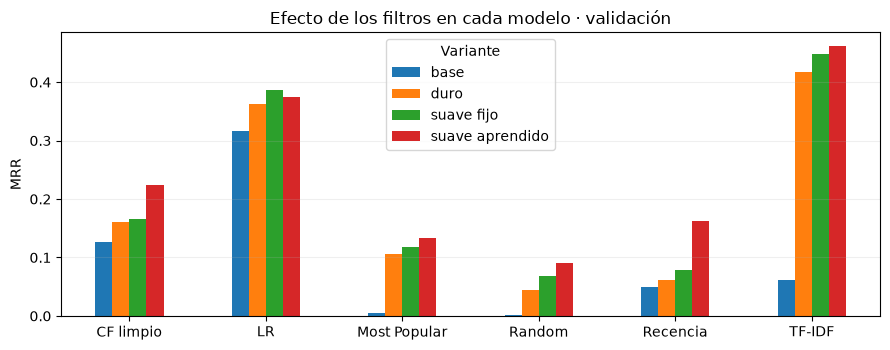

In [42]:
modelos_base = {'Most Popular': sis.popularity, 'Recencia': sis.recency, 'CF limpio': sis.cf_reference,
                'TF-IDF': sis.external('tfidf')}

control_reconstruccion = []
for nombre, base in modelos_base.items():
    r = entradas.ranks(sis.plain(base))
    registro.add(f'{nombre} base', {}, r)
    oficial = {'Most Popular': resultados_v2['Most Popular'], 'Recencia': resultados_modelos['Recencia'],
               'CF limpio': resultados_v2['CF limpio'], 'TF-IDF': resultados_modelos['Contenido']}[nombre]
    control_reconstruccion.append({'Modelo': nombre, 'MRR reconstruido': (1 / r).mean(), 'MRR de referencia': oficial['MRR']})
display(pd.DataFrame(control_reconstruccion).round(5))

for nombre, base in modelos_base.items():
    for w in VENTANAS_DURO:
        for g in GRACIAS_NUEVAS:
            registro.add(f'{nombre} + duro', {'w': w, 'gracia': g}, entradas.ranks(sis.hard(base, w, g)))
    for tau in TAUS_SUAVE:
        for lam in LAMBDAS_SUAVE:
            registro.add(f'{nombre} + suave fijo', {'tau': tau, 'lambda': lam}, entradas.ranks(sis.soft_normalized(base, tau, lam)))
    for H in HORIZONS:
        for lam in LAMBDAS:
            registro.add(f'{nombre} + suave aprendido', {'H': H, 'lambda': lam}, entradas.ranks(sis.normalized_activity_model(base, modelos_actividad[H], lam)))
registro.add('Random base', {}, entradas.ranks(sis.plain(sis.random_score)))
registro.add('Random + duro', {'w': 30, 'gracia': 7}, entradas.ranks(sis.hard(sis.random_score, 30, 7)))
registro.add('Random + suave fijo', {'tau': 30, 'lambda': 0.5}, entradas.ranks(sis.soft_normalized(sis.random_score, 30, 0.5)))
registro.add('Random + suave aprendido', {'H': 30, 'lambda': 0.5}, entradas.ranks(sis.normalized_activity_model(sis.random_score, modelos_actividad[30], 0.5)))

def fila_resumen(nombre, familia):
    mejor = registro.best(familia)
    resumen = summarize_ranks(ctx, mejor['ranks'])
    return {'Modelo': nombre, 'Variante': familia.split(' + ')[-1] if ' + ' in familia else familia.split(' ')[-1], 'MRR': resumen['MRR'], 'nDCG@10': resumen['nDCG@10'],
            'MRR con historial': resumen['MRR warm'], 'MRR nuevos': resumen['MRR cold'], 'Fuera top1000 (%)': resumen['Fuera top1000 (%)'],
            'Configuración': str(mejor['config'])}

tabla_filtros = pd.DataFrame([fila_resumen(n, f'{n} {v}') for n in ['Random', *modelos_base] for v in ['base', '+ duro', '+ suave fijo', '+ suave aprendido']])
for variante, resultado in [('base', resultados_modelos['LR elegible']), ('+ duro', resultados_modelos['LR + duro']), ('+ suave fijo', resultados_modelos['LR + suave fijo'])]:
    tabla_filtros.loc[len(tabla_filtros)] = {'Modelo': 'LR', 'Variante': variante.removeprefix('+ '), 'MRR': resultado['MRR'], 'nDCG@10': resultado['nDCG@10'],
        'MRR con historial': resultado['MRR warm'], 'MRR nuevos': resultado['MRR cold'], 'Fuera top1000 (%)': resultado['Fuera top1000 (%)'], 'Configuración': 'ver 4.2'}
tabla_filtros.loc[len(tabla_filtros)] = fila_resumen('LR', 'LR + suave aprendido')
display(parametros_primero(tabla_filtros, 'Modelo', 'Variante', 'Configuración').round(5))
ax = tabla_filtros.pivot(index='Modelo', columns='Variante', values='MRR')[['base', 'duro', 'suave fijo', 'suave aprendido']].plot.bar(rot=0, figsize=(9, 3.6))
ax.set(title='Efecto de los filtros en cada modelo · validación', xlabel='', ylabel='MRR')
ax.grid(axis='y', alpha=.2); plt.tight_layout(); plt.show()
ganancias = tabla_filtros.pivot(index='Modelo', columns='Variante', values='MRR')
mejor_tfidf = fila_resumen('TF-IDF', 'TF-IDF + suave fijo')


El filtro duro, el suave fijo y el suave aprendido mejoran a los 6 modelos. Destaca TF-IDF: pasa de 0,0610 a 0,4487 con el suave fijo y a 0,4621 con el suave aprendido, por encima de LR con los mismos filtros (0,3857 y 0,3741). El suave aprendido supera con claridad al fijo en Recencia (0,1632 frente a 0,0793) y CF limpio (0,2243 frente a 0,1655), quizás porque también usa el volumen reciente, una señal que esos modelos no tienen. En LR la diferencia va en sentido contrario y es menor. Los campos de TF-IDF ingresados por reclutadores son una fotografía del perfil y podrían reflejar la oferta, lo que también alcanza a LR. Son resultados de validación tras selección de parámetros.

## Parte 5. Etapa 1: ensamble


LR y CF aportan señales distintas, así que esta parte los combina de cuatro maneras. La primera viene del notebook original y combina posiciones en las listas. Las otras tres se agregan aquí y combinan scores, usando CF limpio: CF asigna score cero a un candidato nuevo, y la lista de ese candidato queda en un orden arbitrario que RRF lee como señal. Un score cero, en cambio, no aporta nada a una mezcla.

| Método | Qué combina | Peso | Fundamento | Origen |
|---|---|---|---|---|
| Fusión de rangos (RRF) | Posiciones en las listas de LR y CF | Uno, con compuerta opcional | *Reciprocal rank fusion* (Cormack et al., 2009) | Notebook original |
| Mezcla ponderada | Scores: `α·norm(LR) + (1−α)·norm(CF)` | Uno, con y sin compuerta | Híbrido ponderado (Burke, 2002); combinación convexa frente a RRF (Bruch et al., 2023) | Agregada |
| Mezcla por historial | Scores, con la misma fórmula | Uno por tramo de historial: 0, 1 y 2 o más procesos | *Binned linear regression* (Jahrer et al., 2010). La compuerta es el caso de dos tramos | Agregada |
| Mezcla aprendida | Scores, con pesos según metacaracterísticas del candidato | Aprendidos con regresión sobre datos reservados | *Feature-weighted linear stacking* (Sill et al., 2009), con pérdida por pares (Rendle et al., 2009) | Agregada |

Bruch et al. estudian búsqueda, no recomendación, y Jahrer y Sill optimizan RMSE sobre ratings. Aplicarlos a este problema es una extensión nuestra, no un resultado establecido.

Para comparar sin inflar resultados, dividimos validación por fecha en dos partes con cerca de la mitad de las consultas cada una: el período de ajuste (P1), hasta el 13 de diciembre de 2023, y el período de control (P2), desde el 14. Los parámetros se eligen en P1 y se evalúan en P2.


### 5.1. Fusión de rangos (RRF)

Primero combinamos las listas oficiales elegibles usando una fusión de rangos ponderada:

`score_RRF(j)=α/(60+r_LR(j)) + (1-α)/(60+r_CF(j))`.

Una oferta ausente de un componente aporta cero en él. La constante 60 queda fija; probamos `α∈{0,0.25,0.5,0.75,1}`. Los extremos deben devolver exactamente la lista del componente correspondiente, sin rellenar con el otro.

También comparamos una compuerta simple: LR para candidatos sin historial y el peso elegido para quienes sí lo tienen. El estado warm se conoce antes de recomendar. Es una variante adicional declarada, no una modificación posterior ocultada al ver resultados.

La fusión trabaja sobre la unión de dos listas truncadas. Es un método válido sobre ese conjunto de recuperación, pero no equivale a fusionar scores CF completos ni garantiza que estén todas las ofertas relevantes. Medimos ese techo de recuperación.


Fusión de rangos (RRF) : coincide con evaluador oficial en global/warm/cold.


,alpha_LR,compuerta,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,0.00,False,4208,0.11604,0.11555,0.15684,0.28384,0.02801,4.01616
1,0.25,False,4208,0.14830,0.14893,0.20913,0.30812,0.06446,1.42586
2,0.50,False,4208,0.19678,0.22318,0.39663,0.30970,0.13754,0.61787
3,0.75,False,4208,0.26866,0.34154,0.62405,0.30433,0.24995,0.33270
4,1.00,False,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.30894
5,0.00,True,4208,0.32752,0.37095,0.54705,0.28384,0.35044,1.40209
6,0.25,True,4208,0.33588,0.37957,0.55989,0.30812,0.35044,0.52281
7,0.50,True,4208,0.33642,0.38553,0.59221,0.30970,0.35044,0.35646
8,0.75,True,4208,0.33457,0.39243,0.62334,0.30433,0.35044,0.30894
9,1.00,True,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.30894


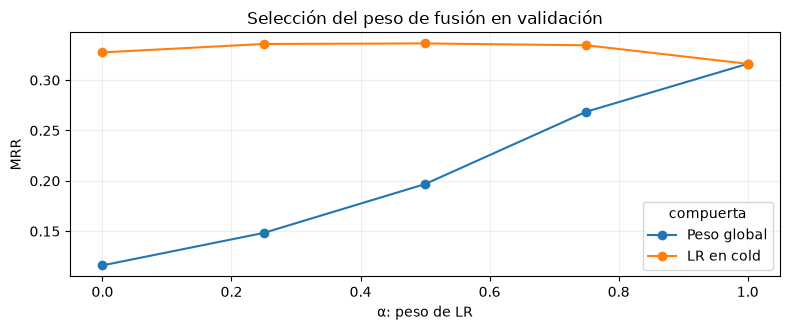

Positivos presentes en el pool de fusión elegido: 4195 / 4208


In [43]:
from jth.fusion import ALPHAS as ALPHAS_FUSION, RRF_C, rrf_pool
listas_lr_base=rankings_modelos['LR oficial']
listas_cf_base=rankings_modelos['CF + recencia oficial']

def pool_fusion_modelos(i,alpha):
    return rrf_pool(listas_lr_base[i],listas_cf_base[i],alpha,len(ofertas),RRF_C)

def ordenar_pool_modelos(pool,scores):
    return rank_pool(ctx,pool,scores)

def rankings_fusion_modelos(alpha,compuerta):
    listas=[]
    for i in range(len(claves_modelos)):
        a=1. if compuerta and not warm_modelos[i] else alpha
        if a==1: listas.append(listas_lr_base[i]); continue
        if a==0: listas.append(listas_cf_base[i]); continue
        pool,s=pool_fusion_modelos(i,a)
        listas.append(ordenar_pool_modelos(pool,s))
    return listas

assert all(np.array_equal(a,b) for a,b in zip(rankings_fusion_modelos(1,False),listas_lr_base))
assert all(np.array_equal(a,b) for a,b in zip(rankings_fusion_modelos(0,False),listas_cf_base))

grid_fusion=[]; best_fusion=None
for compuerta in [False,True]:
    for alpha in ALPHAS_FUSION:
        listas=rankings_fusion_modelos(alpha,compuerta)
        res,det=metricas_listas_modelos(listas)
        fila=dict(res,alpha_LR=alpha,compuerta=compuerta)
        grid_fusion.append(fila)
        if best_fusion is None or (res['MRR'],res['nDCG@10'])>(best_fusion[0]['MRR'],best_fusion[0]['nDCG@10']):
            best_fusion=(fila,listas,det)
grid_fusion=pd.DataFrame(grid_fusion)
rankings_modelos['Fusión de rangos (RRF)']=best_fusion[1]
resultados_modelos['Fusión de rangos (RRF)'],detalles_modelos['Fusión de rangos (RRF)']=verificar_oficial_modelos('Fusión de rangos (RRF)',best_fusion[1])
display(parametros_primero(grid_fusion, 'alpha_LR', 'compuerta').round(5))
ax=grid_fusion.pivot(index='alpha_LR',columns='compuerta',values='MRR').rename(columns={False:'Peso global',True:'LR en cold'}).plot(marker='o',figsize=(8,3.4))
ax.set(title='Selección del peso de fusión en validación',xlabel='α: peso de LR',ylabel='MRR')
ax.grid(alpha=.2); plt.tight_layout(); plt.show()

pool_ganador=[]; scores_ganador=[]
for i in range(len(claves_modelos)):
    a=1. if best_fusion[0]['compuerta'] and not warm_modelos[i] else best_fusion[0]['alpha_LR']
    pool,s=pool_fusion_modelos(i,a)
    pool_ganador.append(pool); scores_ganador.append(s)
cobertura_pool_fusion=np.array([g in p for g,p in zip(gold_indices_modelos,pool_ganador)])
print('Positivos presentes en el pool de fusión elegido:',int(cobertura_pool_fusion.sum()),'/',len(claves_modelos))


### 5.2. Mezcla ponderada

Los pesos que se evalúan en P2 se eligen solo en P1 (ver 6.3). Una división por días alternados compartiría casi las mismas ofertas activas entre ambos períodos.

También corremos RRF con CF limpio y las mismas listas de LR, para una comparación justa con la mezcla ponderada.


P1: 2098 consultas hasta 2023-12-13. P2: 2110 consultas desde 2023-12-14.


,alpha_LR,compuerta,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,0.00,False,4208,0.09339,0.09704,0.11169,0.26866,0.00143,71.62548
1,0.25,False,4208,0.36772,0.42291,0.64116,0.40067,0.35044,0.28517
2,0.50,False,4208,0.36809,0.42335,0.64163,0.40173,0.35044,0.28517
3,0.75,False,4208,0.36742,0.42273,0.64116,0.39980,0.35044,0.28517
4,1.00,False,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517
5,0.00,True,4208,0.32230,0.36500,0.52947,0.26866,0.35044,18.36977
6,0.25,True,4208,0.36772,0.42291,0.64116,0.40067,0.35044,0.28517
7,0.50,True,4208,0.36809,0.42335,0.64163,0.40173,0.35044,0.28517
8,0.75,True,4208,0.36742,0.42273,0.64116,0.39980,0.35044,0.28517
9,1.00,True,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517


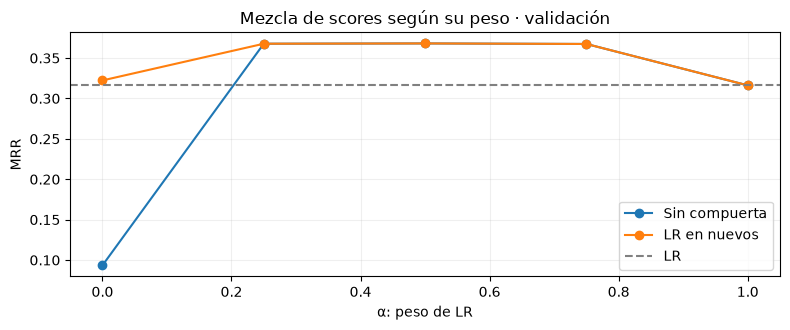

,alpha_LR,compuerta,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
0,0.00,False,4208,0.12615,0.12649,0.16801,0.29696,0.03653,5.67966
1,0.25,False,4208,0.15905,0.16174,0.22410,0.31025,0.07972,1.80608
2,0.50,False,4208,0.20977,0.23539,0.39758,0.31626,0.15390,0.61787
3,0.75,False,4208,0.27388,0.33938,0.60219,0.30118,0.25956,0.30894
4,1.00,False,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517
5,0.00,True,4208,0.33204,0.37471,0.54824,0.29696,0.35044,1.73479
6,0.25,True,4208,0.33661,0.38043,0.56084,0.31025,0.35044,0.57034
7,0.50,True,4208,0.33868,0.38834,0.59529,0.31626,0.35044,0.33270
8,0.75,True,4208,0.33349,0.39029,0.61906,0.30118,0.35044,0.28517
9,1.00,True,4208,0.31620,0.37056,0.59387,0.25093,0.35044,0.28517


,Normalización,MRR
0,Min-max,0.36809
1,z-score,0.36765


In [44]:
from jth.fusion import ALPHAS, best_alpha_per_bin, zscore_rows

mitad = dias_modelos[len(dias_modelos) // 2]
en_v1, en_v2 = dias_modelos < mitad, dias_modelos >= mitad
print(f'P1: {en_v1.sum()} consultas hasta {dias_modelos[en_v1].max()}. P2: {en_v2.sum()} consultas desde {mitad}.')

for compuerta in [False, True]:
    for alpha in ALPHAS:
        registro.add('Mezcla ponderada', {'alpha_LR': alpha, 'compuerta': compuerta}, entradas.ranks(sis.score_blend(alpha, compuerta)))
display(registro.table('Mezcla ponderada').round(5))

ax = registro.table('Mezcla ponderada').pivot(index='alpha_LR', columns='compuerta', values='MRR').rename(columns={False: 'Sin compuerta', True: 'LR en nuevos'}).plot(marker='o', figsize=(8, 3.4))
ax.axhline(resultados_modelos['LR elegible']['MRR'], color='gray', ls='--', label='LR')
ax.set(title='Mezcla de scores según su peso · validación', xlabel='α: peso de LR', ylabel='MRR'); ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

listas_lr_elegible_base = rankings_modelos['LR elegible']
for compuerta in [False, True]:
    for alpha in ALPHAS:
        registro.add('RRF con CF limpio', {'alpha_LR': alpha, 'compuerta': compuerta},
                     sis.ranks_from_lists(ctx, sis.rrf_lists(entradas, listas_lr_elegible_base, listas_cf_limpio, alpha, compuerta)))
display(registro.table('RRF con CF limpio').round(5))

a_sin = max((r for r in registro.family('Mezcla ponderada') if not r['config']['compuerta'] and 0 < r['config']['alpha_LR'] < 1), key=lambda r: (1 / r['ranks']).mean())
a_con = max((r for r in registro.family('Mezcla ponderada') if r['config']['compuerta'] and 0 < r['config']['alpha_LR'] < 1), key=lambda r: (1 / r['ranks']).mean())
ranks_z = entradas.ranks(sis.score_blend(a_con['config']['alpha_LR'], True, normalize=zscore_rows))
display(pd.DataFrame({'Normalización': ['Min-max', 'z-score'], 'MRR': [(1 / a_con['ranks']).mean(), (1 / ranks_z).mean()]}).round(5))
mejor_rrf_sin = max((1 / r['ranks']).mean() for r in registro.family('RRF con CF limpio') if not r['config']['compuerta'] and r['config']['alpha_LR'] < 1)


La mezcla de scores logra MRR 0,3681 sin compuerta y 0,3681 con ella, frente a 0,3162 de LR. La mejor RRF sin compuerta logra 0,2739. Es decir, al mezclar scores la compuerta deja de ser necesaria: CF no tiene señal sobre un candidato nuevo y por lo tanto no altera su orden.

### 5.3. Mezcla por historial

Un α para cada tramo: sin procesos previos, con uno, y con dos o más. Como el MRR se descompone por consultas, cada tramo se elige por separado. La compuerta de 5.1 es el caso de dos tramos con LR fijo en los candidatos nuevos.


In [45]:
rr_globales = {r['config']['alpha_LR']: 1 / r['ranks'] for r in registro.family('Mezcla ponderada') if not r['config']['compuerta']}
# Lo que se evalúa en P2 se elige solo en P1. El peso de toda la validación se usa únicamente para el finalista de 6.4.
_, alpha_tramo_v1 = best_alpha_per_bin(rr_globales, entradas.bins, en_v1)
_, alpha_tramo_total = best_alpha_per_bin(rr_globales, entradas.bins)
ranks_b = entradas.ranks(sis.score_blend(alpha_tramo_v1))
registro.add('Mezcla por historial', {'alpha_por_tramo': str(alpha_tramo_v1)}, ranks_b)
tramos = pd.DataFrame([{'Tramo de historial': {0: '0 procesos', 1: '1 proceso', 2: '2 o más'}[b], 'Consultas': int((entradas.bins == b).sum()), 'α elegido en P1': alpha_tramo_v1[b], 'α elegido en toda la validación': alpha_tramo_total[b],
                        'MRR con α de P1': (1 / ranks_b)[entradas.bins == b].mean(), 'MRR de LR': detalles_modelos['LR elegible']['RR'][entradas.bins == b].mean()} for b in [0, 1, 2]])
display(tramos.round(5))


,Tramo de historial,Consultas,α elegido en P1,α elegido en toda la validación,MRR con α de P1,MRR de LR
0,0 procesos,2760,0.25,0.25,0.35044,0.35044
1,1 proceso,711,0.50,0.50,0.39011,0.25951
2,2 o más,737,0.75,0.75,0.41342,0.24266


El peso de LR elegido en P1 es 0,25 sin historial, 0,5 con un proceso y 0,75 con dos o más. En candidatos sin historial α no importa, porque CF no tiene señal sobre ellos. El aporte frente a un único peso está en 6.2.

### 5.4. Mezcla aprendida

En un modelo lineal, el historial es igual para todas las ofertas de una consulta, así que no puede cambiar su orden por sí solo. Solo actúa multiplicando a una señal de la oferta, que es lo que hace FWLS. Las entradas son `norm(log LR)`, `norm(CF)` y, en una variante, `norm(-lag)`, de modo que el modelo puede expresar el suave fijo como caso particular.

Se ajusta con pares de oferta correcta frente a negativos, mezclando ofertas elegibles al azar con las primeras de LR. La regularización se elige dentro de P1, separando su último tercio. **Como aprende pesos, la mezcla aprendida solo puede evaluarse en P2**, que no usó.


In [46]:
GRILLA_RIDGE = [0.01, 0.1, 1.0, 10.0]
dias_v1 = dias_modelos[en_v1]
corte_interno = dias_v1[int(len(dias_v1) * 2 / 3)]
ajuste_interno, control_interno = en_v1 & (dias_modelos < corte_interno), en_v1 & (dias_modelos >= corte_interno)

def elegir_y_ajustar_c(con_actividad, mascara_ajuste):
    filas, mejor = [], None
    for c_ridge in GRILLA_RIDGE:
        pesos = sis.fit_fwls(entradas, ajuste_interno, con_actividad, c_ridge)
        r = entradas.ranks(sis.fwls_scorer(pesos, con_actividad))
        mrr = (1 / r[control_interno]).mean()
        filas.append({'C (ridge)': c_ridge, 'MRR en control interno': mrr})
        if mejor is None or mrr > mejor[0]:
            mejor = (mrr, c_ridge)
    return pd.DataFrame(filas), mejor[1], sis.fit_fwls(entradas, mascara_ajuste, con_actividad, mejor[1])

nombres_entrada = ['norm(log LR)', 'norm(CF)', 'norm(-lag)']
nombres_meta = ['constante', 'con historial', 'log(1+historial)']
pesos_c = {}
for con_actividad, familia in [(False, 'Mezcla aprendida'), (True, 'Mezcla aprendida + actividad')]:
    tabla_c, c_ridge, pesos = elegir_y_ajustar_c(con_actividad, en_v1)
    pesos_c[familia] = {'c': c_ridge, 'v1': pesos}
    display(tabla_c.round(5))
    registro.add(familia, {'c': c_ridge, 'ajuste': 'P1'}, entradas.ranks(sis.fwls_scorer(pesos, con_actividad)))
    entradas_usadas = nombres_entrada[:3 if con_actividad else 2]
    display(pd.DataFrame(np.asarray(pesos).reshape(len(entradas_usadas), 3), index=entradas_usadas, columns=nombres_meta).round(3))
    resumen_v2 = summarize_ranks(ctx, registro.family(familia)[-1]['ranks'], en_v2)


,C (ridge),MRR en control interno
0,0.01,0.37883
1,0.10,0.37883
2,1.00,0.37906
3,10.00,0.37936


,constante,con historial,log(1+historial)
norm(log LR),18.253,2.701,1.286
norm(CF),1.980,1.980,-0.186


,C (ridge),MRR en control interno
0,0.01,0.40969
1,0.10,0.34432
2,1.00,0.14451
3,10.00,0.15270


,constante,con historial,log(1+historial)
norm(log LR),4.841,0.814,0.541
norm(CF),1.273,1.273,0.723
norm(-lag),7.954,1.618,1.357


Ajustadas en P1 y evaluadas en P2, Mezcla aprendida logra MRR 0,3468 (con historial 0,3677, nuevos 0,3369) y Mezcla aprendida + actividad 0,3663 (con historial 0,3821, nuevos 0,3588). Cada celda de la tabla es cuánto pesa esa señal según esa característica del candidato. Si el control interno cambia mucho con la regularización, el ajuste es inestable.

### 5.5. Ensamble con filtro

#### Filtro sobre la fusión original

Fijamos primero su α y su compuerta. Después probamos el mismo presupuesto de diez cortes duros y nueve configuraciones de suave fijo sobre su pool. La variante de suave fijo ordena por `log(score_RRF) - λ·lag_efectivo/τ`. No modifica las listas base ni usa atributos futuros.

Aquí el filtro se aplica antes del top-1000 **de la fusión**, pero dentro de su pool de recuperación. No lo confundimos con el filtro sobre el catálogo completo de LR. Reportamos pérdidas adicionales y conservamos todas las consultas, incluidas las que quedan con lista vacía.


In [47]:
grid_fusion_temporal=[]; best_fusion_temporal=None
config_temporales=[('duro',w,g,None,None) for w in VENTANAS_DURO for g in GRACIAS_NUEVAS]
config_temporales += [('suave fijo',None,None,tau,lam) for tau in TAUS_SUAVE for lam in LAMBDAS_SUAVE]
for tipo,w,gracia,tau,lam in config_temporales:
    listas=[]; conservados=[]
    for i,(pool,s) in enumerate(zip(pool_ganador,scores_ganador)):
        estado=estados_por_consulta[i]
        if tipo=='duro':
            mantener=mascara_dura_modelos(estado,w,gracia)[pool]
            p,ss=pool[mantener],s[mantener]
        else:
            p=pool
            ss=np.log(np.maximum(s,1e-15))-lam*estado['effective_lag'][p]/tau
        conservados.append(gold_indices_modelos[i] in p)
        listas.append(ordenar_pool_modelos(p,ss))
    res,det=metricas_listas_modelos(listas)
    fila=dict(res,tipo=tipo,w=w,gracia=gracia,tau=tau,lambda_=lam,
              Cobertura_pool=100*np.mean(conservados),Positivos_fuera_pool=int(len(conservados)-np.sum(conservados)))
    grid_fusion_temporal.append(fila)
    if best_fusion_temporal is None or (res['MRR'],res['nDCG@10'])>(best_fusion_temporal[0]['MRR'],best_fusion_temporal[0]['nDCG@10']):
        best_fusion_temporal=(fila,listas,det)
grid_fusion_temporal=pd.DataFrame(grid_fusion_temporal)
rankings_modelos['Fusión + actividad']=best_fusion_temporal[1]
resultados_modelos['Fusión + actividad'],detalles_modelos['Fusión + actividad']=verificar_oficial_modelos('Fusión + actividad',best_fusion_temporal[1])
display(parametros_primero(grid_fusion_temporal, 'tipo', 'w', 'gracia', 'tau', 'lambda_').round(5))


Fusión + actividad : coincide con evaluador oficial en global/warm/cold.


,tipo,w,gracia,tau,lambda_,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%),Cobertura_pool,Positivos_fuera_pool
0,duro,7.0,0.0,NaN,NaN,4208,0.37099,0.42567,0.62334,0.34132,0.38656,22.78992,77.21008,959
1,duro,7.0,7.0,NaN,NaN,4208,0.37541,0.43272,0.64734,0.34537,0.39117,15.44677,84.55323,650
2,duro,14.0,0.0,NaN,NaN,4208,0.36495,0.41887,0.62357,0.33556,0.38037,16.11217,83.88783,678
3,duro,14.0,7.0,NaN,NaN,4208,0.37231,0.42748,0.64449,0.34154,0.38845,8.76901,91.23099,369
4,duro,30.0,0.0,NaN,NaN,4208,0.34899,0.40032,0.60195,0.31567,0.36647,12.64259,87.35741,532
5,duro,30.0,7.0,NaN,NaN,4208,0.35781,0.41183,0.62904,0.32238,0.37640,5.29943,94.70057,223
6,duro,60.0,0.0,NaN,NaN,4208,0.33884,0.38643,0.57890,0.30373,0.35727,11.21673,88.78327,472
7,duro,60.0,7.0,NaN,NaN,4208,0.34855,0.39897,0.60694,0.31118,0.36816,3.87357,96.12643,163
8,duro,90.0,0.0,NaN,NaN,4208,0.33565,0.38286,0.57391,0.30208,0.35325,10.95532,89.04468,461
9,duro,90.0,7.0,NaN,NaN,4208,0.34579,0.39573,0.60195,0.30953,0.36481,3.61217,96.38783,152


La actividad aumenta el MRR de la fusión seleccionada en +0,0576. La complejidad extra no se adopta automáticamente.

#### Filtrar antes o después de mezclar

El filtro puede aplicarse en dos momentos: antes de mezclar, como plantea la propuesta, de modo que los modelos solo ordenen ofertas vigentes, o después, como recién en la fusión de rangos, que mezcla, luego penaliza y fija α antes de ajustar el filtro. Comparamos ambos órdenes para RRF y para la mezcla ponderada, y también ajustamos α y el filtro en conjunto.

Usamos el suave fijo en las variantes de orden, porque ya superó al filtro duro en LR. Los α fijos de estas variantes se eligen en P1, para que P2 siga siendo una evaluación limpia.


In [48]:
gated_a = [r for r in registro.family('Mezcla ponderada') if r['config']['compuerta'] and r['config']['alpha_LR'] < 1]
alpha_a = max(gated_a, key=lambda r: (1 / r['ranks'][en_v1]).mean())['config']['alpha_LR']
compuerta_a = True
gated_rrf = [r for r in registro.family('RRF con CF limpio') if r['config']['compuerta'] and r['config']['alpha_LR'] < 1]
alpha_rrf = max(gated_rrf, key=lambda r: (1 / r['ranks'][en_v1]).mean())['config']['alpha_LR']
print('α elegidos en P1: mezcla ponderada', alpha_a, '| RRF', alpha_rrf)
ALPHAS_CONJUNTOS = [0.25, 0.5, 0.75]

for w in VENTANAS_DURO:
    for g in GRACIAS_NUEVAS:
        registro.add('Mezcla ponderada, filtro después', {'alpha_LR': alpha_a, 'tipo': 'duro', 'w': w, 'gracia': g}, entradas.ranks(sis.score_blend_hard_after(alpha_a, compuerta_a, w, g)))
for tau in TAUS_SUAVE:
    for lam in LAMBDAS_SUAVE:
        registro.add('Mezcla ponderada, filtro después', {'alpha_LR': alpha_a, 'tipo': 'suave fijo', 'tau': tau, 'lambda': lam}, entradas.ranks(sis.score_blend_after(alpha_a, compuerta_a, tau, lam)))
        registro.add('Mezcla ponderada, filtro antes', {'alpha_LR': alpha_a, 'tau': tau, 'lambda': lam}, entradas.ranks(sis.score_blend_before(alpha_a, compuerta_a, tau, lam)))
        registro.add('Mezcla por historial, filtro después', {'tau': tau, 'lambda': lam}, entradas.ranks(sis.score_blend_after(alpha_tramo_v1, False, tau, lam)))
for alpha in ALPHAS_CONJUNTOS:
    for tau in TAUS_SUAVE:
        for lam in LAMBDAS_SUAVE:
            registro.add('Mezcla ponderada, ajuste conjunto', {'alpha_LR': alpha, 'compuerta': True, 'tau': tau, 'lambda': lam}, entradas.ranks(sis.score_blend_after(alpha, True, tau, lam)))

for tau in TAUS_SUAVE:
    for lam in LAMBDAS_SUAVE:
        lista_lr = entradas.lists(sis.soft_lr(tau, lam), tie_lr)
        lista_cf = entradas.lists(sis.soft_normalized(sis.cf_reference, tau, lam))
        registro.add('RRF, filtro antes', {'alpha_LR': alpha_rrf, 'tau': tau, 'lambda': lam}, sis.ranks_from_lists(ctx, sis.rrf_lists(entradas, lista_lr, lista_cf, alpha_rrf, True)))
for alpha in ALPHAS_CONJUNTOS:
    for tau in TAUS_SUAVE:
        for lam in LAMBDAS_SUAVE:
            registro.add('RRF, ajuste conjunto', {'alpha_LR': alpha, 'compuerta': True, 'tau': tau, 'lambda': lam},
                         sis.ranks_from_lists(ctx, sis.rrf_lists(entradas, listas_lr_elegible_base, listas_cf_limpio, alpha, True, soft=(tau, lam))))

familias_orden = ['Mezcla ponderada, filtro después', 'Mezcla ponderada, filtro antes', 'Mezcla ponderada, ajuste conjunto', 'Mezcla por historial, filtro después', 'RRF, filtro antes', 'RRF, ajuste conjunto']
columnas = ['MRR', 'nDCG@10', 'HR@10', 'MRR warm', 'MRR cold']
tabla_orden = pd.DataFrame([{'Familia': f, **{k: summarize_ranks(ctx, registro.best(f)['ranks'])[k] for k in columnas}, 'Configuración': str(registro.best(f)['config'])} for f in familias_orden])
tabla_orden.loc[len(tabla_orden)] = {'Familia': 'Fusión + actividad (original)', **{k: resultados_modelos['Fusión + actividad'][k] for k in columnas}, 'Configuración': str({k: best_fusion_temporal[0][k] for k in ['tipo', 'tau', 'lambda_']})}
tabla_orden.loc[len(tabla_orden)] = {'Familia': 'LR + suave fijo (4.2)', **{k: resultados_modelos['LR + suave fijo'][k] for k in columnas}, 'Configuración': str({'tau': best_suave[0]['tau'], 'lambda': best_suave[0]['lambda_']})}
display(parametros_primero(tabla_orden.sort_values('MRR', ascending=False), 'Familia', 'Configuración').round(5))
print('Configuraciones nuevas registradas hasta aquí:', len(registro))


α elegidos en P1: mezcla ponderada 0.75 | RRF 0.5


,Familia,Configuración,MRR,nDCG@10,HR@10,MRR warm,MRR cold
3,"Mezcla por historial, filtro después","{'tau': 90, 'lambda': 0.25}",0.42385,0.48313,0.70485,0.44470,0.41292
0,"Mezcla ponderada, filtro después","{'alpha_LR': 0.75, 'tipo': 'suave fijo', 'tau': 90, 'lambda': 0.25}",0.42382,0.48310,0.70485,0.44458,0.41292
2,"Mezcla ponderada, ajuste conjunto","{'alpha_LR': 0.75, 'compuerta': True, 'tau': 90, 'lambda': 0.25}",0.42382,0.48310,0.70485,0.44458,0.41292
1,"Mezcla ponderada, filtro antes","{'alpha_LR': 0.75, 'tau': 90, 'lambda': 0.25}",0.41980,0.47897,0.70081,0.43291,0.41292
4,"RRF, filtro antes","{'alpha_LR': 0.5, 'tau': 90, 'lambda': 0.25}",0.39787,0.45807,0.68607,0.36918,0.41292
5,"RRF, ajuste conjunto","{'alpha_LR': 0.75, 'compuerta': True, 'tau': 30, 'lambda': 0.5}",0.39757,0.45700,0.68489,0.37609,0.40885
6,Fusión + actividad (original),"{'tipo': 'suave fijo', 'tau': 30, 'lambda_': 0.5}",0.39397,0.44973,0.66920,0.36562,0.40884
7,LR + suave fijo (4.2),"{'tau': 90, 'lambda': 0.25}",0.38573,0.44701,0.67966,0.33391,0.41292


Configuraciones nuevas registradas hasta aquí: 237


El mejor orden depende del método. En la mezcla ponderada conviene filtrar después: MRR 0,4238 frente a 0,4198 en toda la validación, y 0,4022 frente a 0,4002 en P2. Los candidatos nuevos quedan igual (0,4129), porque CF no tiene señal sobre ellos, así que toda la diferencia viene de quienes tienen historial. En RRF conviene filtrar antes: 0,3979 frente a 0,3940, y 0,3796 frente a 0,3732 en P2.

Ajustar α y el filtro en conjunto no agrega nada. En la mezcla ponderada elige la misma configuración que filtrar después, y en RRF queda en 0,3976, y 0,3751 en P2, por debajo de filtrar antes. Las diferencias entre órdenes son pequeñas frente a lo que aporta el filtro, y no les calculamos un intervalo propio.


## Parte 6. Resultados de la Etapa 1


### 6.1. Comparación e incertidumbre

Mostramos referencias y mejores variantes por familia. El mejor resultado explorado puede ser una referencia o una variante sin CF; no forzamos que gane el sistema más complejo. Los valores de validación del ganador están condicionados a la búsqueda realizada y deben contrastarse en una evaluación posterior con decisiones congeladas.

Cuantificamos además diferencias pareadas frente a LR oficial mediante bootstrap de bloques consecutivos de siete días, 2.000 remuestreos y semilla 42. Se remuestrean los mismos bloques en ambos modelos. Es una aproximación a la dependencia temporal; no elimina dependencias de candidatos entre bloques ni corrige el optimismo de selección de hiperparámetros.


,Consultas,MRR,nDCG@10,HR@10,MRR warm,MRR cold,Fuera top1000 (%)
Fusión + actividad,4208.0,0.393971,0.449731,0.669202,0.365620,0.408845,0.308935
LR + suave fijo,4208.0,0.385731,0.447008,0.679658,0.333908,0.412919,0.308935
LR + duro,4208.0,0.362033,0.423336,0.649715,0.306506,0.391165,15.446768
Fusión de rangos (RRF),4208.0,0.336418,0.385535,0.592205,0.309697,0.350438,0.356464
LR elegible,4208.0,0.316197,0.370559,0.593869,0.250932,0.350438,0.285171
LR oficial,4208.0,0.316197,0.370559,0.593869,0.250932,0.350438,0.308935
Popularidad reciente,4208.0,0.203426,0.243066,0.433460,0.193149,0.208817,10.337452
CF + recencia oficial,4208.0,0.116043,0.115551,0.156844,0.283837,0.028011,4.016160
Contenido,4208.0,0.060950,0.066892,0.129990,0.037004,0.073514,14.781369
Recencia,4208.0,0.049298,0.043741,0.101473,0.046738,0.050642,0.380228


,Variante,Control,ΔMRR,ΔMRR warm,ΔMRR cold
0,Contenido,Recencia,0.011652,-0.009734,0.022872
1,LR elegible,LR oficial,0.000000,0.000000,0.000000
2,LR + duro,LR elegible,0.045836,0.055574,0.040727
3,LR + suave fijo,LR elegible,0.069534,0.082977,0.062482
4,Fusión de rangos (RRF),LR oficial,0.020222,0.058765,0.000000
5,Fusión + actividad,Fusión de rangos (RRF),0.057553,0.055923,0.058407


,ΔMRR vs LR oficial,IC95 inferior,IC95 superior
Modelo,,,
Recencia,-0.266899,-0.284348,-0.250128
Contenido,-0.255247,-0.273551,-0.237570
LR oficial,0.000000,0.000000,0.000000
CF + recencia oficial,-0.200154,-0.226545,-0.173310
LR elegible,0.000000,0.000000,0.000001
Popularidad reciente,-0.112771,-0.131810,-0.094988
LR + duro,0.045837,0.037710,0.054151
LR + suave fijo,0.069534,0.062237,0.076698
Fusión de rangos (RRF),0.020222,0.011425,0.029403


Consultas: 4208 | Bloques temporales: 36 | Remuestreos: 2000


,Variante,Control,ΔMRR,IC95 inferior,IC95 superior
0,Contenido,Recencia,0.011652,0.003575,0.019209
1,LR elegible,LR oficial,0.000000,0.000000,0.000001
2,LR + duro,LR elegible,0.045836,0.037710,0.054150
3,LR + suave fijo,LR elegible,0.069534,0.062237,0.076698
4,Fusión de rangos (RRF),LR oficial,0.020222,0.011425,0.029403
5,Fusión + actividad,Fusión de rangos (RRF),0.057553,0.050442,0.065240
6,Fusión + actividad,LR + suave fijo,0.008240,-0.000214,0.017966


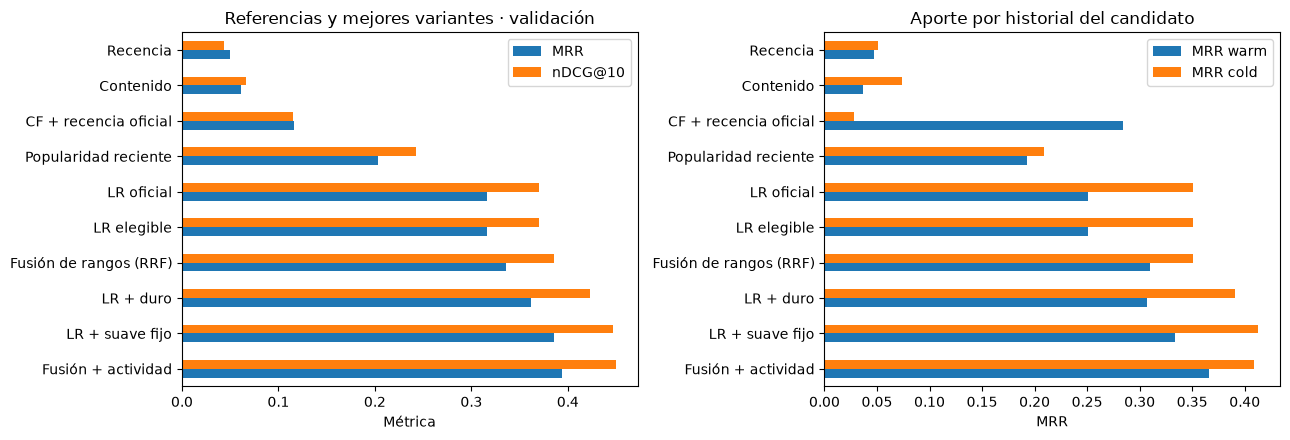

{
  "criterio": "MRR; nDCG@10 secundario; primera configuración enumerada en empate exacto",
  "ganador_validacion": "Fusión + actividad",
  "actividad_tau": 7,
  "lr_duro": {
    "w": 7,
    "gracia": 7
  },
  "lr_suave": {
    "tau": 90,
    "lambda": 0.25
  },
  "fusion": {
    "alpha_LR": 0.5,
    "compuerta": true,
    "RRF_c": 60.0
  },
  "fusion_actividad": {
    "tipo": "suave fijo",
    "w": null,
    "gracia": null,
    "tau": 30,
    "lambda_": 0.5
  },
  "configuraciones_exploradas": 51,
  "cache_referencias": "data/cache/references/val_eb62586c8de437e72346ba25",
  "evaluacion_test": "No realizada en esta etapa; no se utilizó para seleccionar parámetros."
}


In [49]:
tabla_final_modelos=pd.DataFrame(resultados_modelos).T.sort_values(['MRR','nDCG@10'],ascending=False)
display(tabla_final_modelos.round(6))
comparaciones_incrementales=[('Contenido','Recencia'),('LR elegible','LR oficial'),
    ('LR + duro','LR elegible'),('LR + suave fijo','LR elegible'),
    ('Fusión de rangos (RRF)','LR oficial'),('Fusión + actividad','Fusión de rangos (RRF)')]
tabla_aportes=pd.DataFrame([
    {'Variante':v,'Control':c,'ΔMRR':resultados_modelos[v]['MRR']-resultados_modelos[c]['MRR'],
     'ΔMRR warm':resultados_modelos[v]['MRR warm']-resultados_modelos[c]['MRR warm'],
     'ΔMRR cold':resultados_modelos[v]['MRR cold']-resultados_modelos[c]['MRR cold']}
    for v,c in comparaciones_incrementales])
display(tabla_aportes.round(6))
ganador_modelos=tabla_final_modelos.index[0]
from jth.uncertainty import BlockBootstrap
bootstrap=BlockBootstrap(dias_modelos)
filas_ic=[]
for nombre,detalle in detalles_modelos.items():
    media,low,high=bootstrap.difference(detalle['RR'],detalles_modelos['LR oficial']['RR'])
    filas_ic.append({'Modelo':nombre,'ΔMRR vs LR oficial':media,'IC95 inferior':low,'IC95 superior':high})
intervalos_modelos=pd.DataFrame(filas_ic).set_index('Modelo')
display(intervalos_modelos.round(6))
print('Consultas:',len(claves_modelos),'| Bloques temporales:',len(bootstrap.unique),'| Remuestreos:',len(bootstrap.resamples))
pares_incrementales=comparaciones_incrementales+[('Fusión + actividad','LR + suave fijo')]
ic_incrementales=[]
for variante,control in pares_incrementales:
    media,low,high=bootstrap.difference(detalles_modelos[variante]['RR'],detalles_modelos[control]['RR'])
    ic_incrementales.append({'Variante':variante,'Control':control,'ΔMRR':media,
                            'IC95 inferior':low,'IC95 superior':high})
display(pd.DataFrame(ic_incrementales).round(6))

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
tabla_final_modelos[['MRR','nDCG@10']].plot.barh(ax=axes[0])
tabla_final_modelos[['MRR warm','MRR cold']].plot.barh(ax=axes[1])
axes[0].set(title='Referencias y mejores variantes · validación',xlabel='Métrica',ylabel='')
axes[1].set(title='Aporte por historial del candidato',xlabel='MRR',ylabel='')
fig.tight_layout(); plt.show()

configuracion_seleccionada={
    'criterio':'MRR; nDCG@10 secundario; primera configuración enumerada en empate exacto',
    'ganador_validacion':ganador_modelos,
    'actividad_tau':mejor_actividad[3],
    'lr_duro':{'w':int(best_duro[0]['w']),'gracia':int(best_duro[0]['gracia'])},
    'lr_suave':{'tau':int(best_suave[0]['tau']),'lambda':float(best_suave[0]['lambda_'])},
    'fusion':{'alpha_LR':float(best_fusion[0]['alpha_LR']),'compuerta':bool(best_fusion[0]['compuerta']),'RRF_c':RRF_C},
    'fusion_actividad':{k:best_fusion_temporal[0][k] for k in ['tipo','w','gracia','tau','lambda_']},
    'configuraciones_exploradas':int(len(grid_actividad)+len(grid_duro)+len(grid_suave)+len(grid_fusion)+len(grid_fusion_temporal)),
    'cache_referencias':str(cache_referencias.relative_to(RAIZ)),
    'evaluacion_test':'No realizada en esta etapa; no se utilizó para seleccionar parámetros.',
}
print(json.dumps(configuracion_seleccionada,indent=2,ensure_ascii=False))


Entre las familias de esta tabla, la mejor es Fusión + actividad, con MRR 0,3940. La diferencia respecto de LR oficial es +0,0778. La tabla de intervalos y la exposición a validación deben acompañar esa cifra; no es todavía rendimiento final en test.

Fusión + actividad cambia el MRR en +0,0082 y el acierto top-10 en -1,05 puntos porcentuales respecto de LR + suave fijo. Es un intercambio entre métricas y complejidad. Las dos variantes tienen puntuaciones y parámetros temporales distintos; esta comparación no aísla exclusivamente el aporte de CF.

Podemos distinguir contenido puro, actividad pura, LR/CF, efecto de elegibilidad, efecto de filtrar o penalizar y efecto de fusionar. Las tablas de búsqueda completas permiten revisar los parámetros. Si la mezcla o actividad no mejoran, conservaremos la referencia más simple; una ganancia seleccionada aquí sigue necesitando evaluación posterior.

**Límites de esta iteración.** Los perfiles son una instantánea; LR y CF conservan peculiaridades oficiales documentadas; la búsqueda secuencial no explora todas las interacciones posibles y puede sobreajustar validación. Los IC son condicionales al procedimiento y no deben presentarse como prueba concluyente de generalización. La etiqueta sigue siendo proceso registrado, no contratación, y ausencia de actividad no equivale a cierre.


En la ejecución guardada, Fusión + actividad gana por el criterio principal MRR, pero su diferencia frente a LR + suave fijo es de aproximadamente 0,0082. El IC pareado por bloques para esa diferencia va de aproximadamente −0,0002 a 0,0180 e incluye cero. Esta validación no permite afirmar una superioridad firme de la alternativa más compleja sobre LR + suave fijo. Además, LR + suave fijo alcanza más aciertos top-10 y mejor MRR cold, mientras la fusión con actividad mejora el grupo warm. Conservamos ambos como candidatos, con la configuración de mayor MRR identificada para contrastarla posteriormente. Estos intervalos son condicionales y no corrigen la búsqueda de hiperparámetros.


### 6.2. Contribución de componentes

Reúne en una sola tabla cada referencia, cada filtro, cada mezcla y las ablaciones. Todo sobre validación, con el mismo *bootstrap* de bloques de 6.1. **TF-IDF es nuestro baseline propio**, y la popularidad reciente se presenta como la señal por sí sola.

Cada fila está elegida en toda la validación dentro de su familia, por lo que estas cifras son optimistas. La sección 6.3 corrige esa selección.


In [50]:
filas_componentes = []
def agregar_componente(grupo, nombre, ranks):
    for etiqueta, mascara in [('Todos', np.ones(len(ranks), dtype=bool)), ('Con historial', ctx.warm), ('Nuevos', ~ctx.warm)]:
        d = detail_from_ranks(ranks)
        mrr, b_low, b_high = bootstrap.interval(d['RR'], mascara)
        ndcg, n_low, n_high = bootstrap.interval(d['nDCG'], mascara)
        filas_componentes.append({'Grupo': grupo, 'Sistema': nombre, 'Candidatos': etiqueta, 'MRR': mrr, 'IC95 MRR': f'[{b_low:.3f}, {b_high:.3f}]', 'nDCG@10': ndcg, 'IC95 nDCG@10': f'[{n_low:.3f}, {n_high:.3f}]'})

componentes = [('Referencias', 'Random', detalles_v2['Random']['puestos']), ('Referencias', 'Most Popular', detalles_v2['Most Popular']['puestos']),
               ('Referencias', 'Recencia', detalles_modelos['Recencia']['puestos']), ('Referencias', 'TF-IDF (baseline propio)', detalles_modelos['Contenido']['puestos']),
               ('Referencias', 'CF oficial (catálogo transductivo)', detalles_modelos['CF + recencia oficial']['puestos']), ('Referencias', 'CF limpio', detalles_v2['CF limpio']['puestos']),
               ('Referencias', 'LR', detalles_modelos['LR oficial']['puestos']), ('Señal', 'Popularidad reciente', detalles_modelos['Popularidad reciente']['puestos']),
               ('Filtro', 'LR + duro', detalles_modelos['LR + duro']['puestos']), ('Filtro', 'LR + suave fijo', detalles_modelos['LR + suave fijo']['puestos']),
               ('Filtro', 'LR + suave aprendido', registro.best('LR + suave aprendido')['ranks']), ('Filtro', 'TF-IDF + suave fijo', registro.best('TF-IDF + suave fijo')['ranks']), ('Filtro', 'TF-IDF + suave aprendido', registro.best('TF-IDF + suave aprendido')['ranks']),
               ('Mezcla sin filtro', 'Fusión de rangos (RRF) con compuerta', detalles_modelos['Fusión de rangos (RRF)']['puestos']), ('Mezcla sin filtro', 'RRF con CF limpio', registro.best('RRF con CF limpio')['ranks']),
               ('Mezcla sin filtro', 'Mezcla ponderada', registro.best('Mezcla ponderada')['ranks']), ('Mezcla sin filtro', 'Mezcla por historial', registro.best('Mezcla por historial')['ranks']), ('Mezcla sin filtro', 'Mezcla aprendida (ajustada en P1)', registro.best('Mezcla aprendida')['ranks']),
               ('Mezcla con filtro', 'Fusión + actividad original', detalles_modelos['Fusión + actividad']['puestos']), ('Mezcla con filtro', 'RRF, ajuste conjunto', registro.best('RRF, ajuste conjunto')['ranks']),
               ('Mezcla con filtro', 'Mezcla ponderada, filtro después', registro.best('Mezcla ponderada, filtro después')['ranks']), ('Mezcla con filtro', 'Mezcla ponderada, filtro antes', registro.best('Mezcla ponderada, filtro antes')['ranks']),
               ('Mezcla con filtro', 'Mezcla ponderada, ajuste conjunto', registro.best('Mezcla ponderada, ajuste conjunto')['ranks']), ('Mezcla con filtro', 'Mezcla por historial, filtro después', registro.best('Mezcla por historial, filtro después')['ranks']),
               ('Mezcla con filtro', 'Mezcla aprendida + actividad (ajustada en P1)', registro.best('Mezcla aprendida + actividad')['ranks'])]
for grupo, nombre, ranks in componentes:
    agregar_componente(grupo, nombre, ranks)
tabla_componentes = pd.DataFrame(filas_componentes)
with pd.option_context('display.max_rows', None):
    display(tabla_componentes.round(5))
tabla_componentes.to_csv(RAIZ / 'results' / 'v2_componentes_validacion.csv', index=False)

rr_de = lambda n: detalles_modelos[n]['RR']
rr_mejor = lambda f: 1 / registro.best(f)['ranks']
aportes = [('Filtro duro sobre LR', rr_de('LR + duro'), rr_de('LR elegible')), ('Suave fijo sobre LR', rr_de('LR + suave fijo'), rr_de('LR elegible')),
           ('Suave aprendido frente a suave fijo', rr_mejor('LR + suave aprendido'), rr_de('LR + suave fijo')), ('Fusión de rangos (RRF) con compuerta frente a LR', rr_de('Fusión de rangos (RRF)'), rr_de('LR oficial')),
           ('Mezcla ponderada frente a LR', rr_mejor('Mezcla ponderada'), rr_de('LR elegible')), ('Mezcla por historial frente a mezcla ponderada', rr_mejor('Mezcla por historial'), rr_mejor('Mezcla ponderada')),
           ('Actividad sobre mezcla ponderada', rr_mejor('Mezcla ponderada, filtro después'), rr_mejor('Mezcla ponderada')), ('Mezcla ponderada + filtro frente a LR + suave fijo', rr_mejor('Mezcla ponderada, filtro después'), rr_de('LR + suave fijo')),
           ('TF-IDF + suave fijo frente a LR + suave fijo', rr_mejor('TF-IDF + suave fijo'), rr_de('LR + suave fijo'))]
display(pd.DataFrame([(texto, *bootstrap.difference(a, b)) for texto, a, b in aportes], columns=['Aporte', 'ΔMRR', 'IC95 inferior', 'IC95 superior']).round(5))


,Grupo,Sistema,Candidatos,MRR,IC95 MRR,nDCG@10,IC95 nDCG@10
0,Referencias,Random,Todos,0.00099,"[0.001, 0.001]",0.00014,"[0.000, 0.000]"
1,Referencias,Random,Con historial,0.00108,"[0.001, 0.001]",0.00022,"[0.000, 0.001]"
2,Referencias,Random,Nuevos,0.00095,"[0.001, 0.001]",0.00010,"[0.000, 0.000]"
3,Referencias,Most Popular,Todos,0.00497,"[0.003, 0.007]",0.00307,"[0.001, 0.007]"
4,Referencias,Most Popular,Con historial,0.00275,"[0.002, 0.004]",0.00079,"[0.000, 0.002]"
5,Referencias,Most Popular,Nuevos,0.00614,"[0.004, 0.009]",0.00426,"[0.001, 0.009]"
6,Referencias,Recencia,Todos,0.04930,"[0.045, 0.054]",0.04374,"[0.038, 0.050]"
7,Referencias,Recencia,Con historial,0.04674,"[0.041, 0.054]",0.03909,"[0.030, 0.049]"
8,Referencias,Recencia,Nuevos,0.05064,"[0.046, 0.056]",0.04618,"[0.039, 0.054]"
9,Referencias,TF-IDF (baseline propio),Todos,0.06095,"[0.054, 0.068]",0.06689,"[0.057, 0.077]"


,Aporte,ΔMRR,IC95 inferior,IC95 superior
0,Filtro duro sobre LR,0.04584,0.03771,0.05415
1,Suave fijo sobre LR,0.06953,0.06224,0.07670
2,Suave aprendido frente a suave fijo,-0.01161,-0.01961,-0.00355
3,Fusión de rangos (RRF) con compuerta frente a LR,0.02022,0.01143,0.02940
4,Mezcla ponderada frente a LR,0.05189,0.04068,0.06325
5,Mezcla por historial frente a mezcla ponderada,0.00008,-0.00104,0.00113
6,Actividad sobre mezcla ponderada,0.05573,0.04980,0.06159
7,Mezcla ponderada + filtro frente a LR + suave fijo,0.03808,0.02860,0.04724
8,TF-IDF + suave fijo frente a LR + suave fijo,0.06300,0.04355,0.08335


### 6.3. Selección en ajuste y control

Probamos muchas configuraciones, y elegir la mejor sobre los mismos datos con que se reporta sobreestima su rendimiento. Aquí cada familia elige su configuración en P1 y se evalúa en P2, sin usar test. También es la única comparación válida para la mezcla aprendida.

El intervalo sigue siendo condicional: no corrige por completo que varias familias se comparen entre sí. Esta es la tabla más confiable de esta etapa.


In [51]:
familias_v1v2 = [f'{n} + {v}' for n in ['Most Popular', 'Recencia', 'CF limpio', 'TF-IDF'] for v in ['duro', 'suave fijo', 'suave aprendido']] + ['LR + suave aprendido', 'Mezcla ponderada', 'Mezcla por historial', 'RRF con CF limpio', 'Mezcla aprendida', 'Mezcla aprendida + actividad',
                 'Mezcla ponderada, filtro después', 'Mezcla ponderada, filtro antes', 'Mezcla ponderada, ajuste conjunto', 'Mezcla por historial, filtro después', 'RRF, filtro antes', 'RRF, ajuste conjunto']

# Las familias originales se vuelven a seleccionar en P1 con las mismas grillas.
for tau in TAUS_SUAVE:
    for lam in LAMBDAS_SUAVE:
        registro.add('LR + suave fijo (original)', {'tau': tau, 'lambda': lam}, entradas.ranks(sis.soft_lr(tau, lam), tie_lr))
for w in VENTANAS_DURO:
    for g in GRACIAS_NUEVAS:
        registro.add('LR + duro (original)', {'w': w, 'gracia': g}, entradas.ranks(sis.hard(sis.lr_score, w, g), tie_lr))
for alpha in ALPHAS_FUSION:
    for compuerta in [False, True]:
        registro.add('Fusión de rangos (RRF)', {'alpha_LR': alpha, 'compuerta': compuerta}, sis.ranks_from_lists(ctx, sis.rrf_lists(entradas, listas_lr_base, listas_cf_base, alpha, compuerta)))
elegido_rrf_v1 = registro.best('Fusión de rangos (RRF)', en_v1)['config']
def grilla_fusion_actividad(familia, alpha, compuerta):
    for tau in TAUS_SUAVE:
        for lam in LAMBDAS_SUAVE:
            registro.add(familia, {'alpha_LR': alpha, 'compuerta': compuerta, 'tau': tau, 'lambda': lam},
                         sis.ranks_from_lists(ctx, sis.rrf_lists(entradas, listas_lr_base, listas_cf_base, alpha, compuerta, soft=(tau, lam))))
grilla_fusion_actividad('Fusión + actividad (original)', best_fusion[0]['alpha_LR'], best_fusion[0]['compuerta'])
grilla_fusion_actividad('Fusión + actividad (α de P1)', elegido_rrf_v1['alpha_LR'], elegido_rrf_v1['compuerta'])

# Los mismos scorers deben reproducir a los ganadores originales.
for familia, original in [('LR + suave fijo (original)', 'LR + suave fijo'), ('LR + duro (original)', 'LR + duro'), ('Fusión de rangos (RRF)', 'Fusión de rangos (RRF)'), ('Fusión + actividad (original)', 'Fusión + actividad')]:
    assert np.isclose((1 / registro.best(familia)['ranks']).mean(), resultados_modelos[original]['MRR'], atol=1e-12, rtol=0), familia
print('Los scorers de src/jth reproducen a los cuatro ganadores originales.')

ranks_lr = detalles_modelos['LR elegible']['puestos']
filas_seleccion = []
for familia in ['LR + duro (original)', 'LR + suave fijo (original)', 'Fusión de rangos (RRF)', 'Fusión + actividad (α de P1)'] + familias_v1v2:
    elegido = registro.best(familia, en_v1)
    r = elegido['ranks']
    media, low, high = bootstrap.difference(1 / r, 1 / ranks_lr, en_v2)
    v1_res, v2_res = summarize_ranks(ctx, r, en_v1), summarize_ranks(ctx, r, en_v2)
    filas_seleccion.append({'Familia': familia, 'Configuración (elegida en P1)': str(elegido['config']), 'MRR P1': v1_res['MRR'], 'MRR P2': v2_res['MRR'], 'nDCG@10 P2': v2_res['nDCG@10'],
                            'MRR P2 con historial': v2_res['MRR warm'], 'MRR P2 nuevos': v2_res['MRR cold'], 'ΔMRR P2 vs LR': media, 'IC95 inferior': low, 'IC95 superior': high})
tabla_seleccion = pd.DataFrame(filas_seleccion).sort_values('MRR P2', ascending=False)
display(tabla_seleccion.round(5))
tabla_seleccion.to_csv(RAIZ / 'results' / 'v2_seleccion_v1_v2.csv', index=False)
configuraciones_probadas = len(registro) + int(len(grid_actividad) + len(grid_duro) + len(grid_suave) + len(grid_fusion) + len(grid_fusion_temporal))
print('MRR de LR: P1', round(summarize_ranks(ctx, ranks_lr, en_v1)['MRR'], 5), '| P2', round(summarize_ranks(ctx, ranks_lr, en_v2)['MRR'], 5))
print('Configuraciones probadas en total, incluidas las 51 originales:', configuraciones_probadas)


Los scorers de src/jth reproducen a los cuatro ganadores originales.


,Familia,Configuración (elegida en P1),MRR P1,MRR P2,nDCG@10 P2,MRR P2 con historial,MRR P2 nuevos,ΔMRR P2 vs LR,IC95 inferior,IC95 superior
15,TF-IDF + suave aprendido,"{'H': 7, 'lambda': 1.0}",0.46560,0.45863,0.51653,0.37347,0.49877,0.14978,0.12606,0.17969
14,TF-IDF + suave fijo,"{'tau': 7, 'lambda': 0.5}",0.43933,0.45549,0.51329,0.36446,0.49840,0.14664,0.12482,0.17400
13,TF-IDF + duro,"{'w': 7, 'gracia': 7}",0.40330,0.43196,0.48923,0.33973,0.47544,0.12311,0.10066,0.15135
25,"Mezcla por historial, filtro después","{'tau': 90, 'lambda': 0.25}",0.44422,0.40361,0.46054,0.40741,0.40181,0.09476,0.07173,0.11325
24,"Mezcla ponderada, ajuste conjunto","{'alpha_LR': 0.75, 'compuerta': True, 'tau': 90, 'lambda': 0.5}",0.44494,0.40217,0.46087,0.40897,0.39897,0.09332,0.07066,0.11199
22,"Mezcla ponderada, filtro después","{'alpha_LR': 0.75, 'tipo': 'suave fijo', 'tau': 90, 'lambda': 0.5}",0.44494,0.40217,0.46087,0.40897,0.39897,0.09332,0.07066,0.11199
23,"Mezcla ponderada, filtro antes","{'alpha_LR': 0.75, 'tau': 90, 'lambda': 0.25}",0.43946,0.40024,0.45859,0.39692,0.40181,0.09140,0.06797,0.10978
26,"RRF, filtro antes","{'alpha_LR': 0.5, 'tau': 90, 'lambda': 0.25}",0.41622,0.37962,0.43687,0.33255,0.40181,0.07077,0.05267,0.08551
27,"RRF, ajuste conjunto","{'alpha_LR': 0.5, 'compuerta': True, 'tau': 30, 'lambda': 0.5}",0.41689,0.37511,0.42742,0.33260,0.39515,0.06626,0.04832,0.08298
1,LR + suave fijo (original),"{'tau': 90, 'lambda': 0.25}",0.39785,0.37368,0.43023,0.31400,0.40181,0.06483,0.05341,0.07420


MRR de LR: P1 0.32359 | P2 0.30885
Configuraciones probadas en total, incluidas las 51 originales: 335


### 6.4. Finalistas

Antes de tocar test fijamos qué sistemas se evaluarán y con qué parámetros. La lista queda escrita aquí y no cambia después de ver test:

1. **LR + suave fijo**, el finalista simple de 6.1.
2. **Fusión + actividad**, la versión original, de mayor MRR en 6.1.
3. **Mezcla ponderada + filtro**, la mezcla de scores que no necesita compuerta.
4. **Mezcla por historial + filtro**, con un peso por tramo de historial.
5. **TF-IDF + suave fijo**, nuestro baseline propio con el filtro. Sus campos ingresados por reclutadores podrían reflejar la oferta, lo que debe quedar dicho junto a su resultado.
6. **LR + suave aprendido**, porque es la versión que plantea la propuesta.
7. **TF-IDF + suave aprendido**, el mismo baseline con el filtro aprendido y la misma advertencia sobre sus campos.

Los parámetros de cada finalista se eligen de nuevo en toda la validación. El archivo `results/v2_frozen.json` queda en el repositorio antes de ejecutar test: `run_references.py` se niega a correr test si no está versionado.


In [52]:
ruta_congelado = RAIZ / 'results' / 'v2_frozen.json'

def limpiar(config):
    return {k: (v.item() if hasattr(v, 'item') else v) for k, v in config.items()}

definicion = {nombre: {'familia': familia, 'config': limpiar(registro.best(familia)['config'])} for nombre, familia in [
    ('LR + suave fijo', 'LR + suave fijo (original)'), ('Fusión + actividad', 'Fusión + actividad (original)'),
    ('Mezcla ponderada + filtro', 'Mezcla ponderada, filtro después'), ('Mezcla por historial + filtro', 'Mezcla por historial, filtro después'),
    ('TF-IDF + suave fijo', 'TF-IDF + suave fijo'), ('LR + suave aprendido', 'LR + suave aprendido'), ('TF-IDF + suave aprendido', 'TF-IDF + suave aprendido')]}
definicion['Mezcla por historial + filtro']['alpha_por_tramo'] = {str(k): float(v) for k, v in alpha_tramo_total.items()}
congelado = {'decision': 'Elegido en validación antes de ejecutar test. No se modifica después de ver test.', 'configuraciones_probadas': configuraciones_probadas,
             'seleccion_v2': tabla_seleccion[['Familia', 'MRR P2']].round(5).to_dict('records'), 'finalistas': definicion}
if ruta_congelado.exists():
    previo = json.loads(ruta_congelado.read_text(encoding='utf-8'))
    assert previo['finalistas'] == json.loads(json.dumps(definicion)), 'La selección cambió respecto de lo congelado.'
    print('Congelamiento existente confirmado.')
else:
    ruta_congelado.write_text(json.dumps(congelado, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
    print('Congelamiento escrito en', ruta_congelado.relative_to(RAIZ))
print(json.dumps(definicion, indent=2, ensure_ascii=False))


Congelamiento escrito en results/v2_frozen.json
{
  "LR + suave fijo": {
    "familia": "LR + suave fijo (original)",
    "config": {
      "tau": 90,
      "lambda": 0.25
    }
  },
  "Fusión + actividad": {
    "familia": "Fusión + actividad (original)",
    "config": {
      "alpha_LR": 0.5,
      "compuerta": true,
      "tau": 30,
      "lambda": 0.5
    }
  },
  "Mezcla ponderada + filtro": {
    "familia": "Mezcla ponderada, filtro después",
    "config": {
      "alpha_LR": 0.75,
      "tipo": "suave fijo",
      "tau": 90,
      "lambda": 0.25
    }
  },
  "Mezcla por historial + filtro": {
    "familia": "Mezcla por historial, filtro después",
    "config": {
      "tau": 90,
      "lambda": 0.25
    },
    "alpha_por_tramo": {
      "0": 0.25,
      "1": 0.5,
      "2": 0.75
    }
  },
  "TF-IDF + suave fijo": {
    "familia": "TF-IDF + suave fijo",
    "config": {
      "tau": 7,
      "lambda": 1.0
    }
  },
  "LR + suave aprendido": {
    "familia": "LR + suave aprendido

### 6.5. Test

¿Superamos a la regresión logística bajo el protocolo del paper? Se reentrenan las referencias con los 33.830 procesos del entrenamiento oficial y se evalúan las 8.341 consultas. P(actividad) se reentrena censurando H días antes del 23 de marzo de 2024. De validación solo se traen λ, los pesos y la configuración congelada. **Nada se ajusta después de ver estos resultados.**

Cada cifra se rotula: la del paper, la de nuestra réplica anterior y la de esta ejecución. El CF oficial se regenera con la semilla de *hash* fija, y su número puede diferir del 0,114 reportado en la propuesta, que se generó sin fijarla.

Esta sección se ejecuta una sola vez, después de versionar `results/v2_frozen.json`. Mientras `EJECUTAR_TEST` sea falso, no lee ningún resultado de test.


In [53]:
EJECUTAR_TEST = False  # se activa una sola vez, tras versionar results/v2_frozen.json

if EJECUTAR_TEST:
    from jth.context import build_context as construir_contexto
    from jth.activity_model import fit_activity_model as ajustar_actividad, predict_log_activity as predecir_actividad, snapshots as fotografias
    from sklearn.feature_extraction.text import TfidfVectorizer as Tfidf

    congelado = json.loads(ruta_congelado.read_text(encoding='utf-8'))
    cache_test = runner_referencias.execute(RAIZ, 'test')
    ctx_t = construir_contexto(RAIZ, cache_test / 'train.csv', cache_test / 'target.csv', ofertas, evaluador_oficial)
    train_t = pd.read_csv(cache_test / 'train.csv', dtype=str)
    target_t = pd.read_csv(cache_test / 'target.csv', dtype=str)
    estados_t = daily_states(ctx_t, train_t, target_t, TAUS_ACTIVIDAD)
    similitud_t = sp.csr_matrix(clean_cf_scores(ctx_t, train_t, target_t))

    claves_cache = [(evaluador_oficial._parse_id(k[0]), k[1]) for k in json.loads((cache_test / 'keys.json').read_text())]
    filas_lr_t = pd.Index(claves_cache).get_indexer(ctx_t.keys)
    assert (filas_lr_t >= 0).all()
    scores_lr_t = np.load(cache_test / 'lr' / 'scores_full.npy', mmap_mode='r')

    ids_c, ids_o = set(train_t['candidate_id']), set(train_t['job_id'])
    docs = profile_tokens(candidatos[candidatos['candidate_id'].isin(ids_c)]) + profile_tokens(ofertas[ofertas['job_id'].isin(ids_o)])
    tfidf_t = Tfidf(analyzer=identidad_tokens_contenido, sublinear_tf=True, norm='l2').fit(docs)
    Q_t, T_t = tfidf_t.transform(profile_tokens(candidatos)), tfidf_t.transform(profile_tokens(ofertas)).T.tocsr()
    filas_c_t = indice_candidatos_modelos.get_indexer([k[0] for k in ctx_t.keys])
    entradas_t = sis.Inputs(ctx_t, estados_t, scores_lr_t, filas_lr_t, similitud_t, {'tfidf': lambda ix: (Q_t[filas_c_t[ix]] @ T_t).toarray()})
    tie_lr_t = np.arange(ctx_t.n_jobs)

    resultados_t, detalles_t = {}, {}
    def registrar_t(nombre, listas):
        resultados_t[nombre], detalles_t[nombre] = verify_official(ctx_t, nombre, listas)

    listas_oficiales = {}
    for nombre, carpeta in [('Random', 'random'), ('Most Popular', 'popularity'), ('Recencia', 'recency'), ('CF oficial (catálogo transductivo)', 'cf'), ('LR', 'lr')]:
        preds = evaluador_oficial.load_preds(cache_test / carpeta / f'{carpeta}_c2j.pkl.gz')
        listas_oficiales[nombre] = lists_from_official(ctx_t, preds)
        registrar_t(nombre, listas_oficiales[nombre])
    registrar_t('TF-IDF (baseline propio)', entradas_t.lists(sis.plain(sis.external('tfidf'))))
    registrar_t('CF limpio', entradas_t.lists(sis.plain(sis.cf_reference)))

    finalistas = congelado['finalistas']
    c = finalistas['LR + suave fijo']['config']
    registrar_t('LR + suave fijo', entradas_t.lists(sis.soft_lr(c['tau'], c['lambda']), tie_lr_t))
    c = finalistas['Fusión + actividad']['config']
    registrar_t('Fusión + actividad', sis.rrf_lists(entradas_t, listas_oficiales['LR'], listas_oficiales['CF oficial (catálogo transductivo)'], c['alpha_LR'], c['compuerta'], soft=(c['tau'], c['lambda'])))

    dias_t = pd.to_datetime(train_t['timestamp']).to_numpy(dtype='datetime64[D]').astype(int)
    jobs_t = ctx_t.job_index.get_indexer([evaluador_oficial._parse_id(x) for x in train_t['job_id']])
    inicio_test_int = int(np.datetime64(min(estados_t), 'D').astype(int))
    previos = dias_t < inicio_test_int
    def actividad_t(H):
        x_t, y_t = fotografias(dias_t[previos], jobs_t[previos], ctx_t.job_dates, H, inicio_test_int)
        modelo_t = ajustar_actividad(x_t, y_t)
        return np.stack([predecir_actividad(modelo_t, {d: estados_t[d]})[d] for d in sorted(estados_t)])
    c = finalistas['LR + suave aprendido']['config']
    registrar_t('LR + suave aprendido', entradas_t.lists(sis.lr_activity_model(actividad_t(c['H']), c['lambda'])))
    c = finalistas['TF-IDF + suave aprendido']['config']
    registrar_t('TF-IDF + suave aprendido', entradas_t.lists(sis.normalized_activity_model(sis.external('tfidf'), actividad_t(c['H']), c['lambda'])))

    c = finalistas['Mezcla ponderada + filtro']['config']
    puntaje_a = sis.score_blend_hard_after(c['alpha_LR'], True, c['w'], c['gracia']) if c.get('tipo') == 'duro' else sis.score_blend_after(c['alpha_LR'], True, c['tau'], c['lambda'])
    registrar_t('Mezcla ponderada + filtro', entradas_t.lists(puntaje_a))
    b = finalistas['Mezcla por historial + filtro']
    registrar_t('Mezcla por historial + filtro', entradas_t.lists(sis.score_blend_after({int(k): v for k, v in b['alpha_por_tramo'].items()}, False, b['config']['tau'], b['config']['lambda'])))
    c = finalistas['TF-IDF + suave fijo']['config']
    registrar_t('TF-IDF + suave fijo', entradas_t.lists(sis.soft_normalized(sis.external('tfidf'), c['tau'], c['lambda'])))

    bloques_t = BlockBootstrap(ctx_t.days)
    filas_test = []
    for nombre, d in detalles_t.items():
        mrr, b_low, b_high = bloques_t.interval(d['RR'])
        ndcg, n_low, n_high = bloques_t.interval(d['nDCG'])
        delta, d_low, d_high = bloques_t.difference(d['RR'], detalles_t['LR']['RR'])
        filas_test.append({'Sistema': nombre, 'MRR': mrr, 'IC95 MRR': f'[{b_low:.3f}, {b_high:.3f}]', 'nDCG@10': ndcg, 'IC95 nDCG@10': f'[{n_low:.3f}, {n_high:.3f}]',
                           'MRR con historial': resultados_t[nombre]['MRR warm'], 'MRR nuevos': resultados_t[nombre]['MRR cold'], 'ΔMRR vs LR': delta, 'IC95 Δ': f'[{d_low:.3f}, {d_high:.3f}]'})
    tabla_test = pd.DataFrame(filas_test).sort_values('MRR', ascending=False)
    display(tabla_test.round(5))
    tabla_test.to_csv(RAIZ / 'results' / 'v2_test.csv', index=False)
    print('Referencia: LR 0,283 en el paper y 0,286 en nuestra réplica de la propuesta. CF + recencia 0,119 en el paper y 0,114 en esa réplica.')
else:
    print('Test sin ejecutar: decisiones aún no congeladas y versionadas.')


Test sin ejecutar: decisiones aún no congeladas y versionadas.


### 6.6. Próximos pasos

1. **Etapa 2:** perfil dinámico de ofertas mediante el promedio de sus candidatos anteriores, antes de cualquier versión secuencial, e integrar el mejor al ensamble.
2. **Comparación pendiente:** un único modelo de *boosting* con las mismas señales, que es el enfoque ganador del RecSys Challenge 2017 (Volkovs et al.).
3. **Evaluar TF-IDF quitando campos:** sin `job_category` ni `expertise_area`, cuya cobertura cambia cerca de mediados de 2023, y solo con campos LLM, por si los campos de reclutador reflejan la oferta.
4. **Incluir TF-IDF en el ensamble:** rinde más en candidatos nuevos (0,50 frente a 0,40 en P2) y la mezcla ponderada en quienes tienen historial (0,41 frente a 0,36). Ningún ensamble probado lo incluye.

Las fechas perturbadas, los perfiles como instantánea y los procesos curados por reclutadores limitan lo que podemos inferir sobre disponibilidad y preferencias reales. La etiqueta sigue siendo proceso registrado, no contratación.
